# Intro

Check the readme files in the folder to learn how to run scans and use defaults vs specify parameters

# Initialize

In [5]:
#expt_path = 'C:\\_Data\\Lairon\\2025_06_02\\'
cfg_file='aggron.yml'
expt_path = 'C:\\_Data\\Aggron\\2025_06_16\\'

ip = '192.168.137.1'
max_t1 = 150

## Imports

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from qick import QickConfig
import sys 
sys.path.append('../')
from slab_qick_calib.exp_handling.instrumentmanager import InstrumentManager
import slab_qick_calib.experiments as meas
from slab_qick_calib.calib import qubit_tuning, tuneup
from slab_qick_calib import handy
from tqdm.notebook import tqdm
from slab_qick_calib.calib.time_tracking import time_tracking

%load_ext autoreload
%autoreload 2

# Set color palette and font size
handy.config_figs()

<module 'slab_qick_calib.experiments' from 'C:\\_Lib\\python\\slab_qick_calib\\experiments\\__init__.py'>
C:\_Lib\python\slab_qick_calib\experiments
imported slab_qick_calib.experiments.general.qick_experiment
imported slab_qick_calib.experiments.general.qick_experiment_2q
imported slab_qick_calib.experiments.general.qick_program
C:\_Lib\python\slab_qick_calib\experiments\general
C:\_Lib\python\slab_qick_calib\experiments\single_qubit
imported slab_qick_calib.experiments.single_qubit.active_reset
imported slab_qick_calib.experiments.single_qubit.pulse_probe_spectroscopy
imported slab_qick_calib.experiments.single_qubit.rabi
imported slab_qick_calib.experiments.single_qubit.resonator_spectroscopy
imported slab_qick_calib.experiments.single_qubit.single_shot
imported slab_qick_calib.experiments.single_qubit.single_shot_opt
imported slab_qick_calib.experiments.single_qubit.stark_spectroscopy
imported slab_qick_calib.experiments.single_qubit.t1
imported slab_qick_calib.experiments.single_q

ImportError: cannot import name 'tuneup' from 'slab_qick_calib.calib' (C:\_Lib\python\slab_qick_calib\calib\__init__.py)

## Set up new config 
Set to variables to True when setting up a new experiment. 

Note: make sure you set your ADC/DAC channels correctly. This code does not automatically fill in the ADC/DAC into your configuration file, so you should check yourself to make sure these values are correct. 

There are several elements that you may want to customize based on your readout parameters and coherence times. Check readme file config_init_config_manual.md

In [8]:
# Set to false if you aren't creating a new onenew_config = False
new_folder = False
new_config = False
nqubits = 3
rfsoc_alias = 'Qick105'
t1_guess = 50 

import os
import slab_qick_calib.config as config

configs_dir = os.path.join(os.getcwd(),'../', 'configs')

cfg_file_path = os.path.join(configs_dir, cfg_file)
images_dir = os.path.join(expt_path, 'images')
summary_dir = os.path.join(images_dir, 'summary')

if new_config or new_folder:
    if new_config:
        config.init_config(cfg_file_path, nqubits, type='full', aliases=rfsoc_alias, t1=t1_guess)

    if not os.path.exists(expt_path):
        os.makedirs(expt_path)
        os.mkdir(images_dir)
        os.mkdir(summary_dir)

print('Data will be stored in', expt_path)

ModuleNotFoundError: No module named 'slab_qick_calib.config'

## Connect to RFSoC
Before running first cell, make sure a nameserver is running on the network, the Qick board is connected to it, and the ip address listed below matches that of the nameserver. 

You just need to run the first cell, then should be able to run any other cell in whatever order. 

In [9]:
# Results config file
cfg_path = os.path.join(os.getcwd(),'..', 'configs', cfg_file)
auto_cfg = config.load(cfg_path)

# Connect to instruments
im = InstrumentManager(ns_address=ip)
print(im)
soc = QickConfig(im[auto_cfg['aliases']['soc']].get_cfg())
print(soc)

cfg_dict = {'soc': soc, 'expt_path': expt_path, 'cfg_file': cfg_path, 'im': im}

NameError: name 'config' is not defined

In [6]:
cfg_dict

{'soc': <qick.qick_asm.QickConfig at 0x1bf91000b80>,
 'expt_path': 'C:\\_Data\\Aggron\\2025_06_16\\',
 'cfg_file': 'c:\\_Lib\\python\\slab_qick_calib\\notebooks\\..\\configs\\aggron.yml',
 'im': {'Pyro.NameServer': <Pyro4.core.Proxy at 0x1bfa7fdb7f0; not connected; for PYRO:Pyro.NameServer@192.168.137.1:9090>,
  'chatot': <Pyro4.core.Proxy at 0x1bfa7fd94b0; not connected; for PYRO:obj_3ba60199343a44dbaff3c740348d0ef3@192.168.137.104:36851>,
  'Qick105': <Pyro4.core.Proxy at 0x1bfa7fd9ae0; connected IPv4; for PYRO:obj_8775e3de38b544f4af0f91c2323878cb@192.168.137.105:42611>,
  'Qick233': <Pyro4.core.Proxy at 0x1bfa7fd9a20; not connected; for PYRO:obj_373453b9dad1494b9a8220b56ae711bc@192.168.137.233:41795>}}

## How to update config (you can also just edit yml directly)

In [11]:
# #                                          param   value qubit #
# auto_cfg = config.update_readout(cfg_path, 'lamb', 5, qi)
# auto_cfg = config.update_qubit(cfg_path, 'f_ge', 5700, qi)

# # For multiple levels of nesting: 
# auto_cfg = config.update_qubit(cfg_path, ('pulses','pi_ge','gain'), 0.2, qi)

## Print scan params

In [12]:
t1 = meas.T1Experiment(cfg_dict, qi=0, print=True)

reps: 400
soft_avgs: 1
expts: 60
start: 0
span: 303.40000000000003
acStark: False
active_reset: False
qubit: [0]
qubit_chan: 1


In general, all scans will be interacted with either by running default, or giving arguments from params dict. 
You can run scans on list of different qubits or just one by adding first couple lines of each cell. 
Flag of update is used to decide if to set new config vals based on output of scan (if the fit looks good)

## Check QICK issues

### Check mirror frequencies on qubit

In [13]:
import qick_check
qick_check.check_freqs(0, cfg_dict)

Nyquist frequency: 4915.2 MHz
Possible g-e frequencies: 3392.5586 MHz and 6437.841399999999 MHz
Possible e-f frequencies: 3250.0555 MHz and 6580.344499999999 MHz
Anharmonicity: 142.5030999999999 MHz. With aliased e-f: -3187.7858999999994 MHz
Aliased e-f frequency is greater than both g-e frequencies.
Recommendation: Current e-f frequency is the correct choice.


### Check mirror frequencies from resonators

In [21]:
import qick_check
qick_check.check_resonances(cfg_dict)

Nyquist frequency: 4915.2 MHz
Configured resonator frequencies (MHz):
[5381.7495 5920.75   6629.0915]
Aliased resonator frequencies (MHz):
[4448.6505 3909.65   3201.3085]


### Check sampling rates and minimum point spacing

In [36]:
cfg_dict['soc']._get_ch_cfg(ro_ch=0)['f_dds']/2
cfg_dict['soc'].cycles2us(1)

0.0016276041666666667

### Make sure you're not near the nyquist frequency of the ADC

In [16]:
import qick_check
qick_check.check_adc(cfg_dict)

ADC sampling frequency: 4423.68


In [17]:
from slab_qick_calib.qick_check import get_ch

# Assuming 'soc' is your QickSoc object
dac_channel = get_ch(soc, 'DAC_B', type='dac')

In [18]:
from slab_qick_calib.qick_check import get_ch, print_dac_channels, print_adc_channels

# Get a specific channel number
dac_ch = get_ch(soc, 'DAC_A', 'dac')
print(f"DAC_A is on channel: {dac_ch}")

DAC_A is on channel: 1


## Update qubit params

In [ ]:
import slab_qick_calib.qubit_params as qubit_params 

#qubit_params.delta(cfg_path) # Need to find qubit frequency for this 
#qubit_params.cohere(cfg_path) # Need pi pulse and coherence times 
#qubit_params.ham(cfg_path) # Need EF splitting. 

# Time of Flight (TOF)

TOF measures the time it takes for the signal to run through the wires. It will give us the time in clock ticks that we should wait to make a measurements 

 Use this to set trig_offset in config file

  0%|          | 0/1000 [00:00<?, ?it/s]

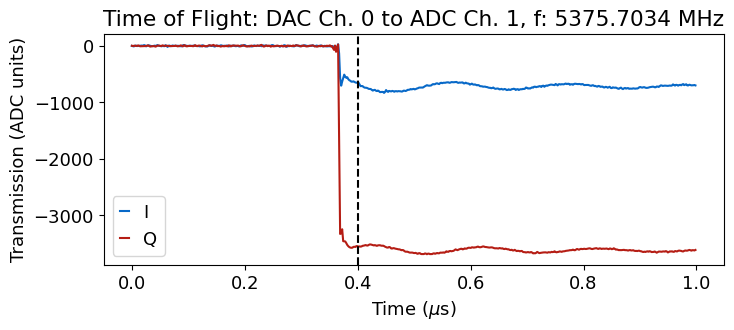

In [189]:
qubit_list = np.arange(3)
qubit_list = [0]

for qi in qubit_list:  
        tof=meas.ToFCalibrationExperiment(cfg_dict=cfg_dict, qi=qi)

        # Set frequency of choice and readout length up to 13 us
        #tof=meas.ToFCalibrationExperiment(cfg_dict=cfg_dict, qi=qi,params={'readout_length':13,'frequency':4000})

## Set trig_offset to point where signal has appeared, usually around 300-500 ns

In [ ]:
qubit_list=np.arange(3)
for qi in qubit_list: 
    auto_cfg = config.update_readout(cfg_path, 'trig_offset', 0.65, qi)

## Collect many time traces of TOF data (for examining measurement data)

check_e first prepares e state

In [ ]:
tof2d = meas.ToF2D(cfg_dict=cfg_dict, qi=qi, params={'expts_count':10000, 'readout_length': 13})
tof2d = meas.ToF2D(cfg_dict=cfg_dict, qi=qi, params={'expts_count':10000, 'readout_length': 13,'check_e':True})

# Resonator Spectroscopy 

Run resonator spectroscopy for all resonators by choosing a large frequency scan to look over. The scan will then find the different resonators and fill in the config file with their respective frequencies. In the autocalibration, there will be a finer sweep of each resonator to more accurately find its frequency. The frequencies are saved in <code>auto_cfg.device.readout.frequency</code>

## Coarse 

This will perform peak finding
Use params to specify frequency range, averaging, gain, expts. 
If gain is too high, you may be in punch out region, where resonators disappear, or above it 

  0%|          | 0/800000 [00:00<?, ?it/s]

Number of peaks: 0


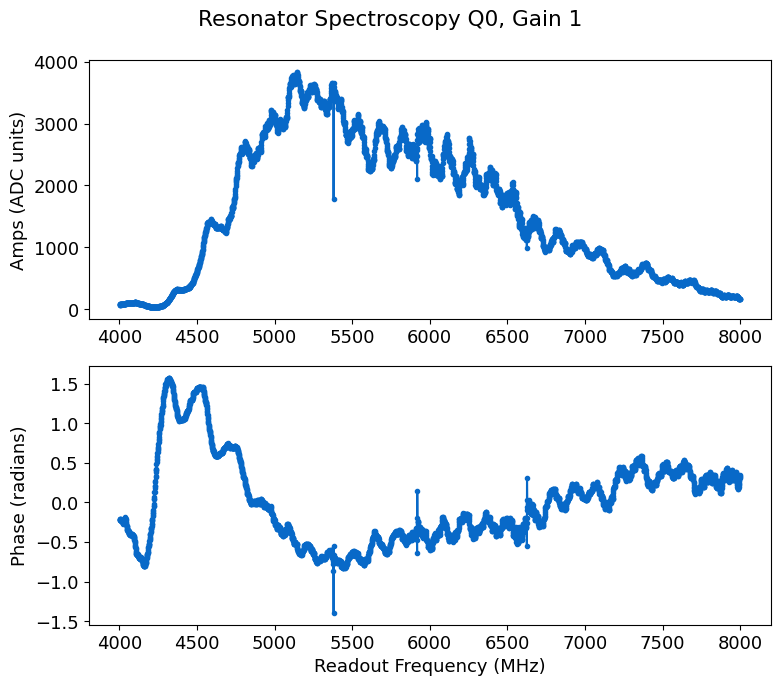

In [13]:
qi=0 # We only run this once for all qubits on a single feedline, this is a dummy value to make the scan work 
 
rspecc = meas.ResSpec(cfg_dict, qi=qi, style='coarse', params={'start':4000, 'span':4000, 'reps':200, 'gain':1, 'expts':4000})
res_values = rspecc.data['coarse_peaks']

Change prom (prominence value) to adjust how many peaks you find

Number of peaks: 3


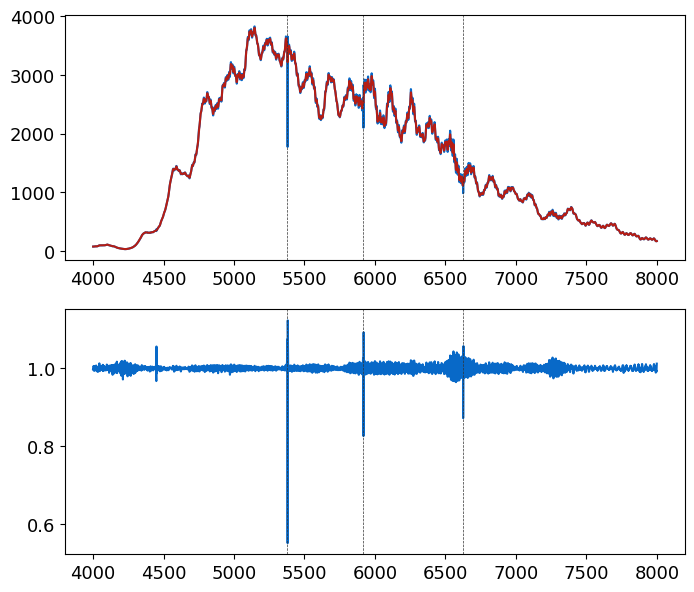

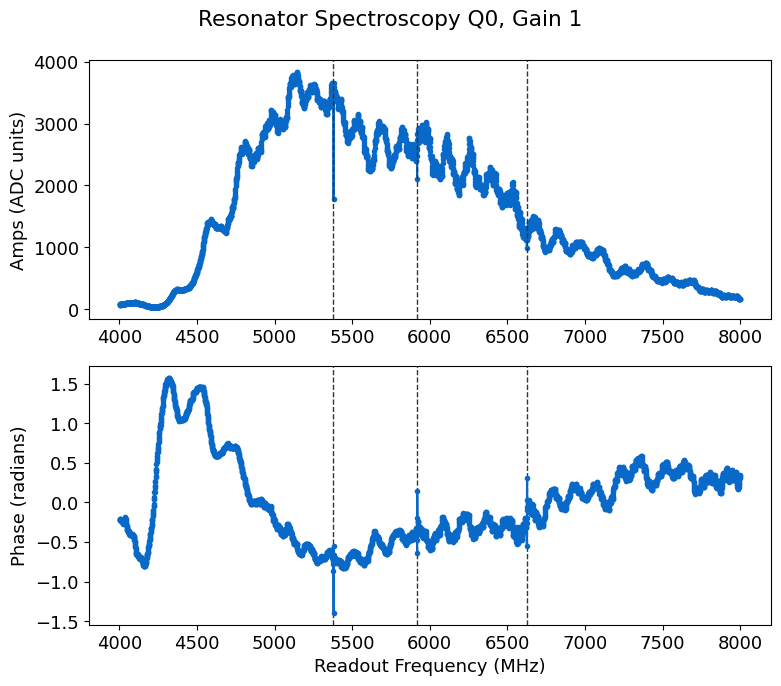

In [14]:
rspecc.analyze(peaks=True, debug=True, fit=False, prom=0.15)
rspecc.display(peaks=True, fit=False)
res_values = rspecc.data['coarse_peaks']

In [193]:
res_values

array([5380.33586655, 5918.46680374, 6625.63887177])

Can delete values from res_values if they don't seem to be real res_values. 

In [ ]:
res_values = np.delete(res_values, 8)

## Fine (initial)

This will fit the resonance amplitude

Can run scan with default options, or specify your own, by commenting out different lines and editing paramters. 

### First time after running coarse scan, using res_values list
Assumes you have the same number of res_values as qubits. 
First time you run scan, plot will appear weird first because it plots the resonator frequency in the config on the same plot. Just run again

  0%|          | 0/33000 [00:00<?, ?it/s]

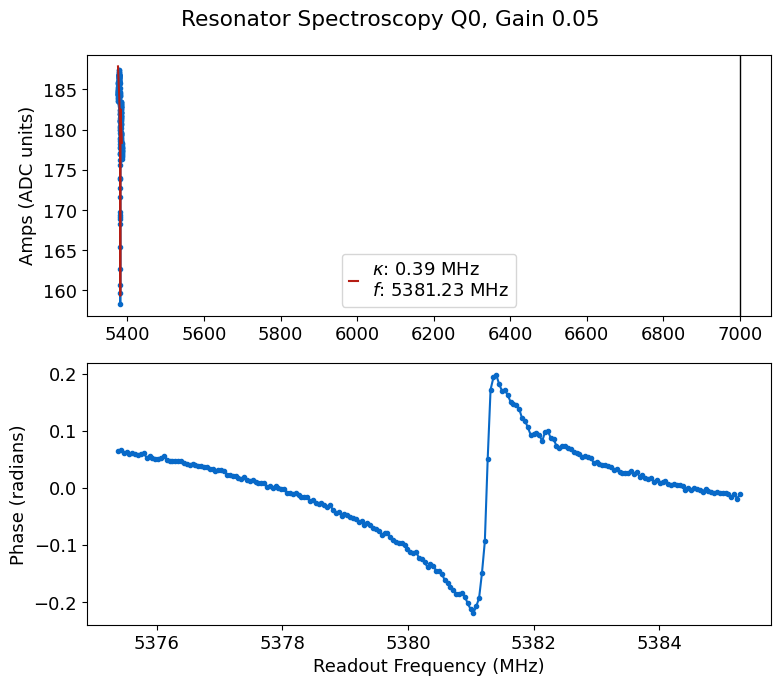

*Set cfg device.readout 0 frequency to 5381.2245 from 7000*
*Set cfg device.readout 0 kappa to 0.3858 from 0.5*
*Set cfg device.readout 0 qi to 1.6072 from 0*
*Set cfg device.readout 0 qe to 10.5591 from 0*


  0%|          | 0/33000 [00:00<?, ?it/s]

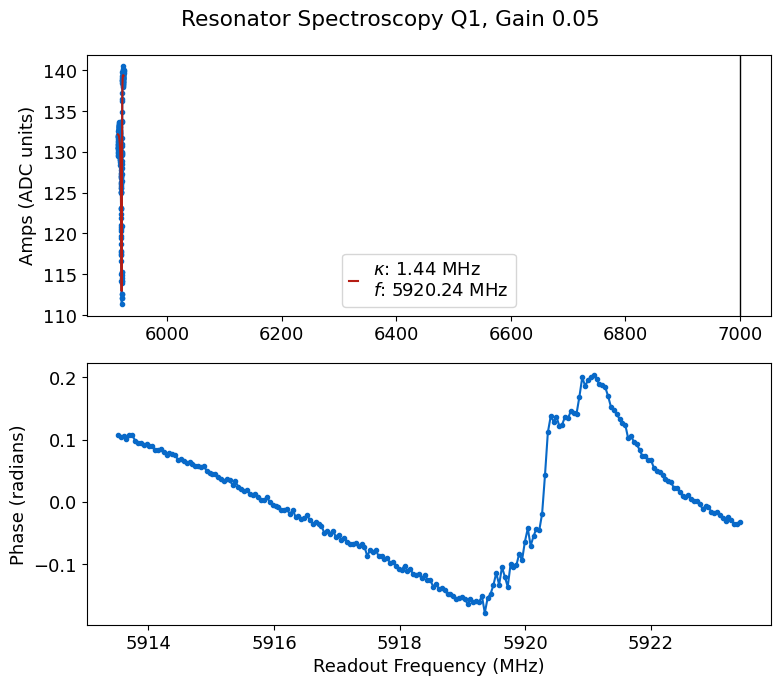

*Set cfg device.readout 1 frequency to 5920.2684 from 7000*
*Set cfg device.readout 1 kappa to 1.4382 from 0.5*
*Set cfg device.readout 1 qi to 0.5078 from 0*
*Set cfg device.readout 1 qe to 2.174 from 0*


  0%|          | 0/33000 [00:00<?, ?it/s]

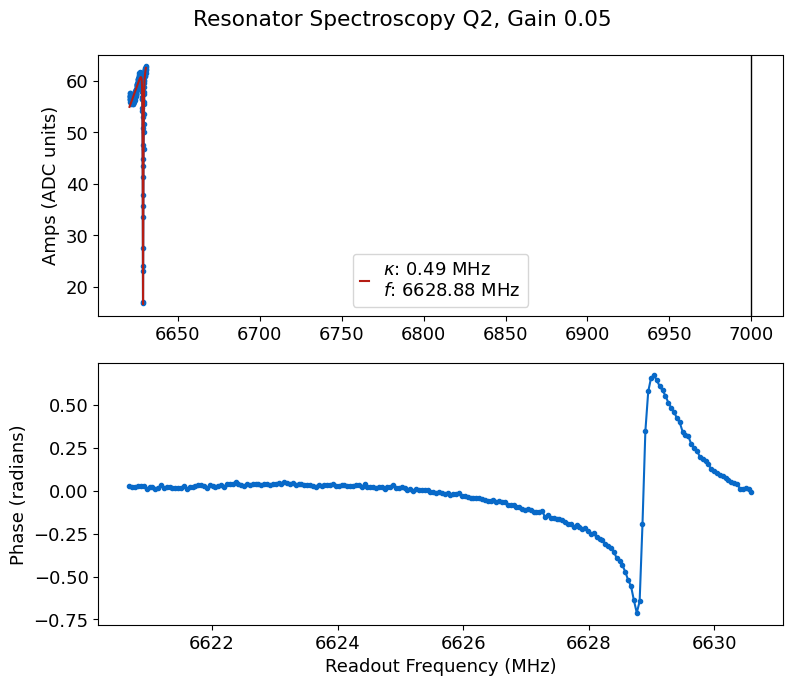

*Set cfg device.readout 2 frequency to 6628.8555 from 7000*
*Set cfg device.readout 2 kappa to 0.4851 from 0.5*
*Set cfg device.readout 2 qi to 5.1526 from 0*
*Set cfg device.readout 2 qe to 1.8597 from 0*


In [15]:
update=True

num_peaks = len(res_values)

for qi in range(len(res_values)):    
    # Used for initial finding of resonance 
    rspec = meas.ResSpec(cfg_dict, qi=qi, params={'span':10, 'center':res_values[qi]})

    if update: rspec.update(cfg_dict['cfg_file'])

## Fine (main)

  0%|          | 0/33000 [00:00<?, ?it/s]

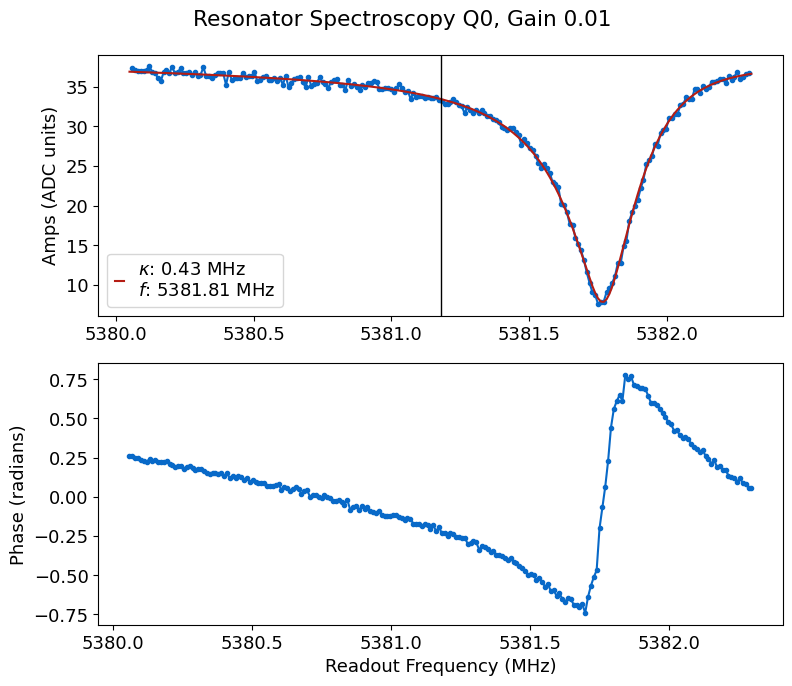

*Set cfg device.readout 0 frequency to 5381.7495 from 5381.1799*
*Set cfg device.readout 0 kappa to 0.4278 from 0.3228*
*Set cfg device.readout 0 qi to 6.513 from 1.883*
*Set cfg device.readout 0 qe to 1.5591 from 14.5506*


  0%|          | 0/33000 [00:00<?, ?it/s]

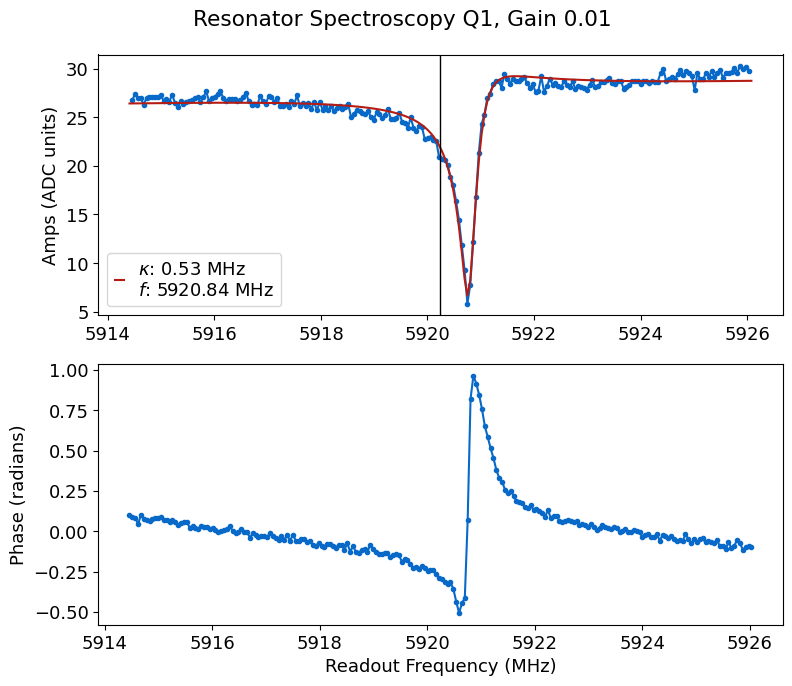

*Set cfg device.readout 1 frequency to 5920.75 from 5920.244*
*Set cfg device.readout 1 kappa to 0.5286 from 1.668*
*Set cfg device.readout 1 qi to 5.9912 from 0.4352*
*Set cfg device.readout 1 qe to 1.3778 from 1.9238*


  0%|          | 0/33000 [00:00<?, ?it/s]

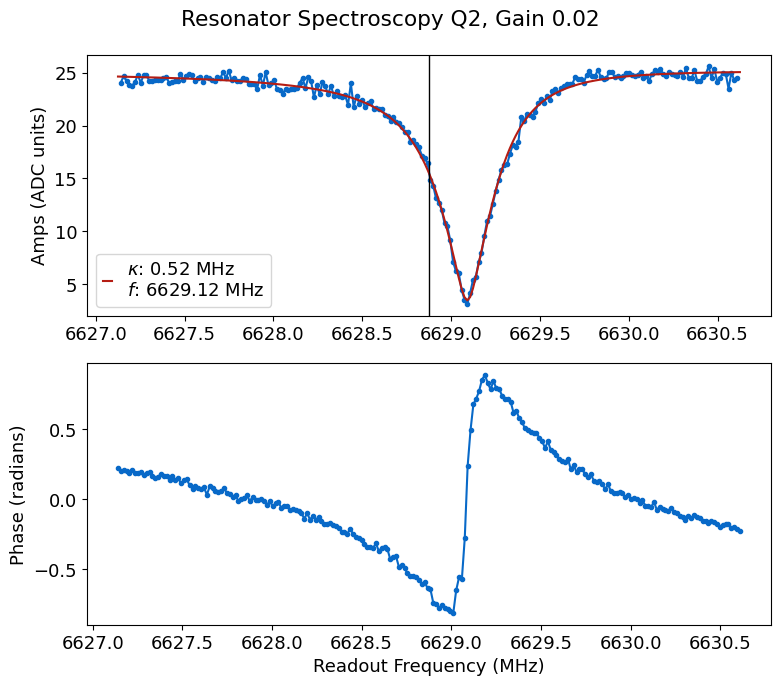

*Set cfg device.readout 2 frequency to 6629.0915 from 6628.8771*
*Set cfg device.readout 2 kappa to 0.5242 from 0.5005*
*Set cfg device.readout 2 qi to 9.443 from 4.3992*
*Set cfg device.readout 2 qe to 1.46 from 1.8952*


In [18]:
update=True # Set to true if you want to update the config file with the new resonance values

# comment out one of these 
qubit_list = np.arange(3)
for qi in qubit_list:    
    # Manually set the span and gain 
    #rspec = meas.ResSpec(cfg_dict, qi=qi, params={'span':5, 'gain':1})

    # Fully automated, using previous fit to kappa to set span
    rspec = meas.ResSpec(cfg_dict, qi=qi, params={'span':'kappa'})
    if update: rspec.update(cfg_dict['cfg_file'])

### Print out scan params

In [ ]:
rspec.print()

## Resonator Power Spectroscopy 

Find a good value for gain to park your readout at until you run readout optimization. From the 2D sweep that is produced, choose a value for gain that is right before the resonator punches out. Want to choose a high value for gain because we want to be in the shot noise limited regime which increases our signal:noise ratio. 

Setting up a new session...


  0%|          | 0/30 [00:00<?, ?it/s]

c:\_Lib\python\slab_qick_calib\notebooks\..\gen\qick_experiment.py:1182: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  im1 = axs[0, 0].imshow(amps_so_far, aspect='auto', cmap='viridis',
c:\_Lib\python\slab_qick_calib\notebooks\..\gen\qick_experiment.py:1187: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  im2 = axs[0, 1].imshow(phases_so_far, aspect='auto', cmap='twilight',
c:\_Lib\python\slab_qick_calib\notebooks\..\gen\qick_experiment.py:1192: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  im3 = axs[1, 0].imshow(avgi_so_far, aspect='auto', cmap='plasma',
c:\_Lib\python\slab_qick_calib\notebooks\..\gen\qick_experiment.py:1197: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  im4 = axs[1, 1].imshow(avgq_so_fa

High power peak [MHz]: 5380.4878
Low power peak [MHz]: 5381.8004
Lamb shift [MHz]: -1.3126


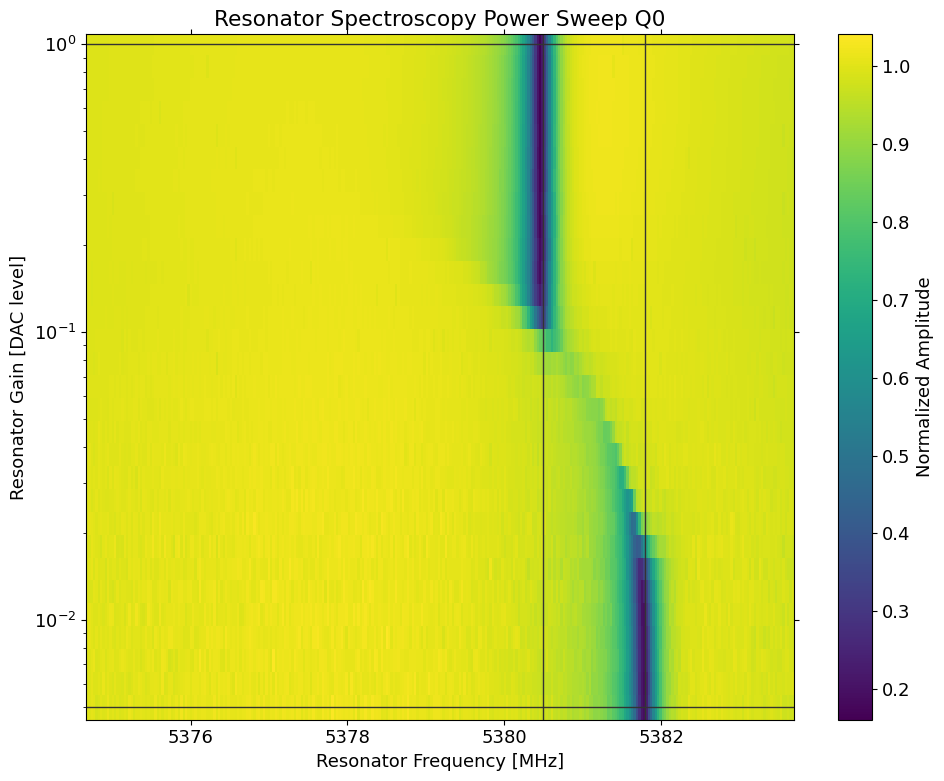

Setting up a new session...


*Set cfg device.readout 0 lamb to -1.3126 from 0*


  0%|          | 0/30 [00:00<?, ?it/s]

High power peak [MHz]: 5919.0953
Low power peak [MHz]: 5920.8836
Lamb shift [MHz]: -1.7883


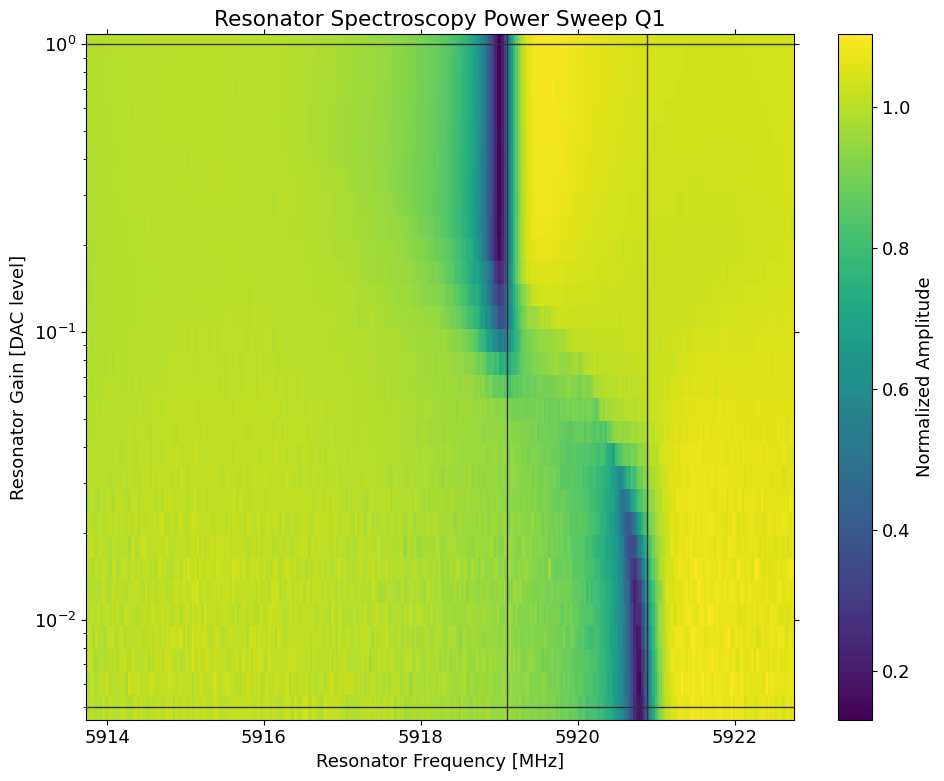

Setting up a new session...


*Set cfg device.readout 1 lamb to -1.7883 from 0*


  0%|          | 0/30 [00:00<?, ?it/s]

High power peak [MHz]: 6626.1365
Low power peak [MHz]: 6629.1415
Lamb shift [MHz]: -3.0050


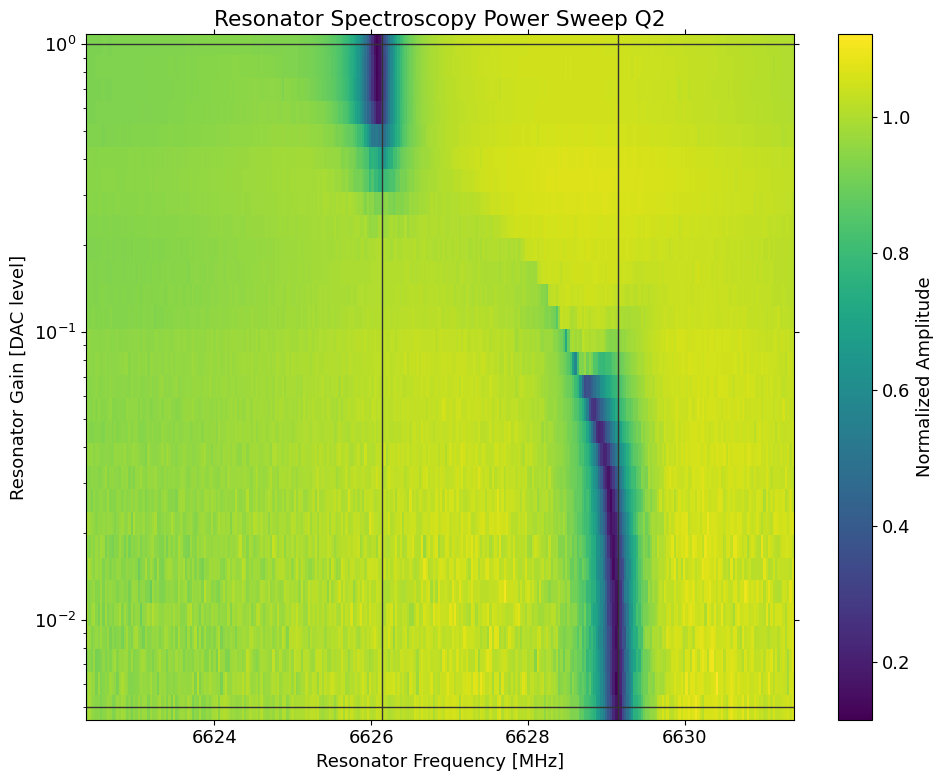

*Set cfg device.readout 2 lamb to -3.005 from 0*


In [17]:
update=True

qubit_list = np.arange(3)
#qubit_list= [2]

d=[]
for qi in qubit_list:
    #rpowspec=meas.ResSpecPower(cfg_dict, qi=qi)
    rpowspec=meas.ResSpecPower(cfg_dict, qi=qi, params={'rng':200,'max_gain':1, 'span':9,"f_off":2,'expts_gain':30,'live_plot': True})
    d.append(rpowspec)
    if update:
        auto_cfg = config.update_readout(cfg_path, 'lamb', rpowspec.data['lamb_shift'], qi)

### Get low power kappa (for Purcell)

  0%|          | 0/33000 [00:00<?, ?it/s]

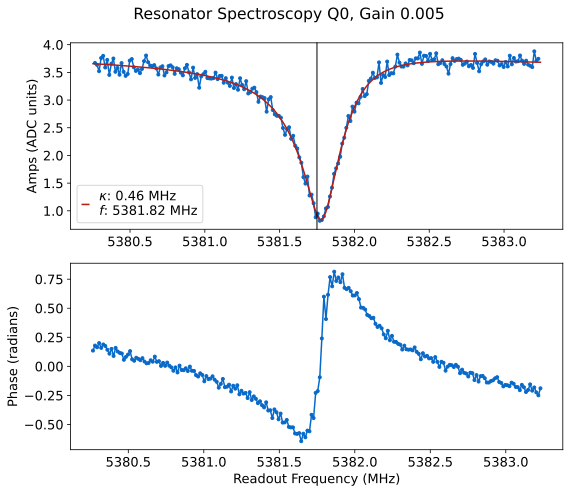

*Set cfg None 0 kappa_low to 0.4583 from None*


  0%|          | 0/33000 [00:00<?, ?it/s]

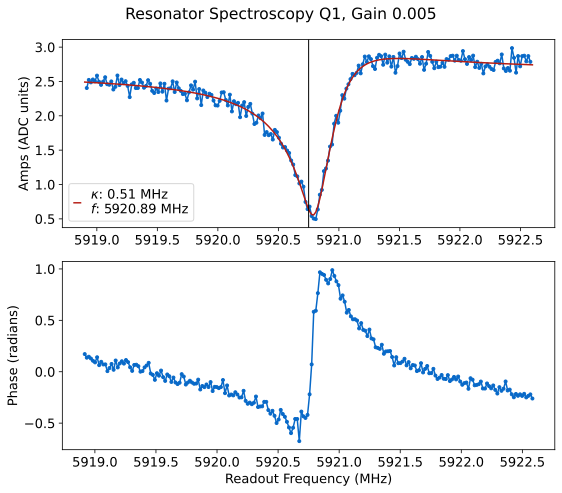

*Set cfg None 1 kappa_low to 0.5063 from None*


  0%|          | 0/33000 [00:00<?, ?it/s]

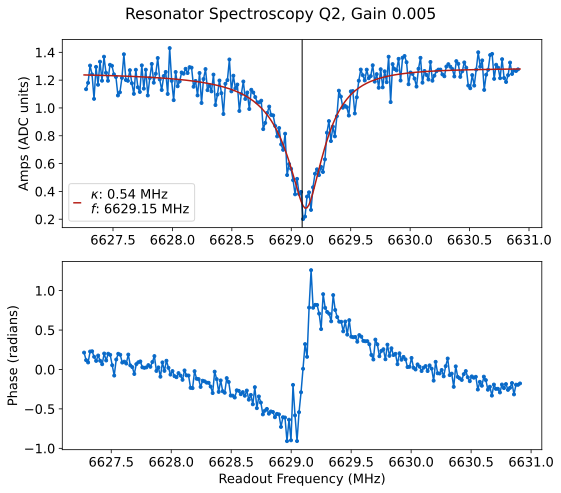

*Set cfg None 2 kappa_low to 0.5402 from None*


In [71]:
low_gain = [0.005, 0.005, 0.005]
model_name = cfg_path[0:-4] + '_model.yml'
qubit_list = [0,1,2]
for qi in qubit_list:    
    # Manually set the span and gain 
    #rspec = meas.ResSpec(cfg_dict, qi=qi, params={'span':5, 'gain':1})

    # Fully automated, using previous fit to kappa to set span
    rspec = meas.ResSpec(cfg_dict, qi=qi, params={'span':'kappa', 'gain':low_gain[qi]})
    config.update_config(model_name, None, 'kappa_low', rspec.data['kappa'], index=qi)
    

### Example of plotting 2D scans for a bunch of qubits together
Can also use for varying a parameter on one qubit and plotting the results together

In [ ]:
auto_cfg = config.load(cfg_path)
horz_line = auto_cfg.device.readout.gain
handy.plot_many(d, title='Resonator Power', save_path=cfg_dict['expt_path'], chan='amps', yax='log', norm=True, horz_line=horz_line)

### Save gain values 

In [ ]:
# assign the resonator gain to the results config file
gain_values = [0.1,0.01]
for i, qi in enumerate(qubit_list):
    auto_cfg = config.update_readout(cfg_file, 'gain', gain_values[i], qi)

# Qubit Spectroscopy

## Find qubits
More automated, zooms out and adds power if no peak visible. Best to use if you're feeling confident, otherwise use more manual stuff in next cell. 

In [10]:
qubit_list = np.arange(3)
qubit_list= [2]

bad_qubits=[]
for qi in qubit_list:
    status, ntries = qubit_tuning.find_spec(qi, cfg_dict, start='medium')
    if not status:
        bad_qubits.append(qi)

NameError: name 'cfg_dict' is not defined

## General search, specify width 

style options: fine, medium, coarse, huge (will change scan width and power)

Uses config values of low_gain (gain to use for finest scan), which sets overall gain for device and spec_gain (set indepedently for each qubit) to decide how much power to apply

You may also just want to do this fully manually by specifiying params. 

  0%|          | 0/150000 [00:00<?, ?it/s]

R2:0.200	Fit par error:1.064	 Best fit:b'avgq'


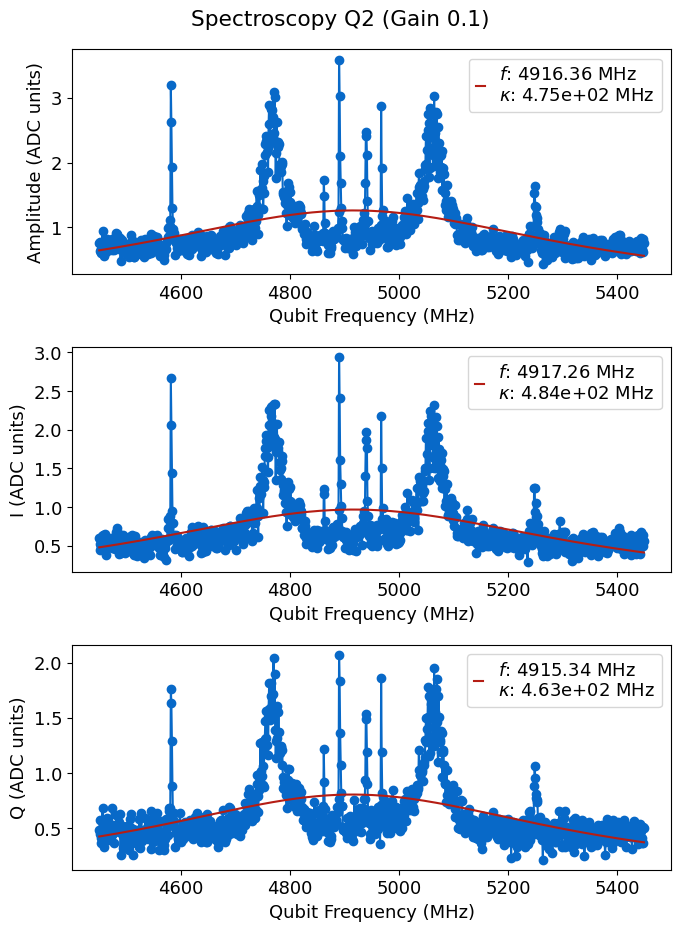

Bad qubit! qi=2


In [48]:
update=True

qubit_list = np.arange(3)
qubit_list = [2]

for qi in qubit_list: 
    # Default params, just specify style 
    #qspec=meas.QubitSpec(cfg_dict, qi=qi, style='coarse')

    # Different examples of params you might give; frequency can be specified as start and span or if no start given, center is f_ge from config
    #qspec=meas.QubitSpec(cfg_dict, qi=qi, style='coarse', params={'gain':0.05})
    qspec=meas.QubitSpec(cfg_dict, qi=qi, style='coarse', params={'start':4450,'span':1000,'expts':1000,'gain':0.1})
    if update and qspec.status: 
        auto_cfg = config.update_qubit(cfg_path, 'f_ge', qspec.data["best_fit"][2], qi)
        auto_cfg = config.update_qubit(cfg_path, 'kappa',2*qspec.data["best_fit"][3], qi)
    elif update:
        print(f'Bad qubit! qi={qi}')

## Stark (still getting it working)

Unexpected parameters found in params: {'stark_freq'}


  0%|          | 0/1000000 [00:00<?, ?it/s]

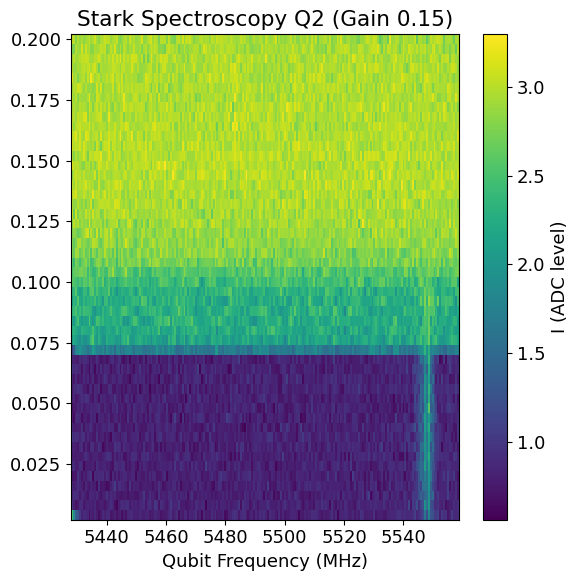

In [49]:
qi=2
qspec=meas.StarkSpec(cfg_dict, qi=qi, style='medium', params={'df_stark':0, 'max_stark_gain':0.2, 'df':-55,'span':130, 'stark_expts':50,'stark_rng':50})

## Power sweep

In [170]:
qubit_list=[2]

for qi in qubit_list:
    #qspec_pow = meas.QubitSpecPower(cfg_dict, qi=qi, style='', params={'start':5320,'span':100,'reps':1000,'expts':200})
    qspec_pow = meas.QubitSpecPower(cfg_dict, qi=qi, style='coarse')
    #qspec_pow = meas.QubitSpecPower(cfg_dict, qi=qi, style='', params={'start':3700,'span':600,'reps':1500,'expts':1200, 'max_gain':0.4, 'length':1,'sep_readout':True})

Unexpected parameters found in params: {'log', 'max_gain', 'expts_gain', 'rng'}


  0%|          | 0/10 [00:00<?, ?it/s]

KeyboardInterrupt: 

### Sweep pulse length 
Useful when t1 low

sep_readout = False measures at same time as probe pulse (default is True)

Unexpected parameters found in params: {'max_gain', 'log', 'expts_gain', 'rng'}


  0%|          | 0/10 [00:00<?, ?it/s]

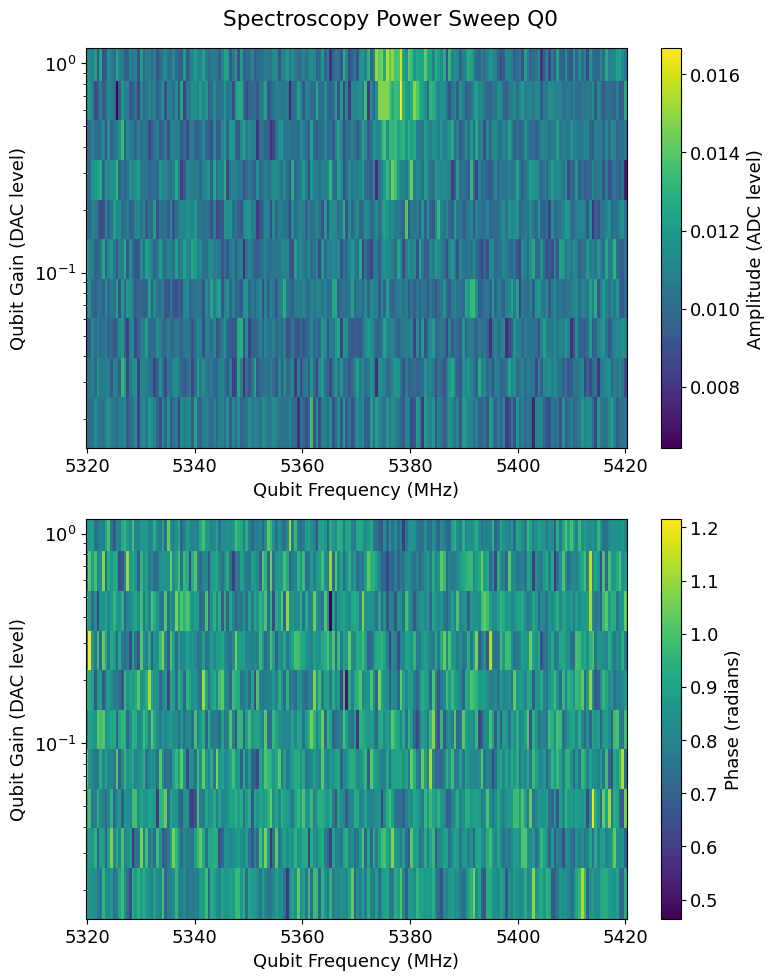

Unexpected parameters found in params: {'max_gain', 'log', 'expts_gain', 'rng'}


  0%|          | 0/10 [00:00<?, ?it/s]

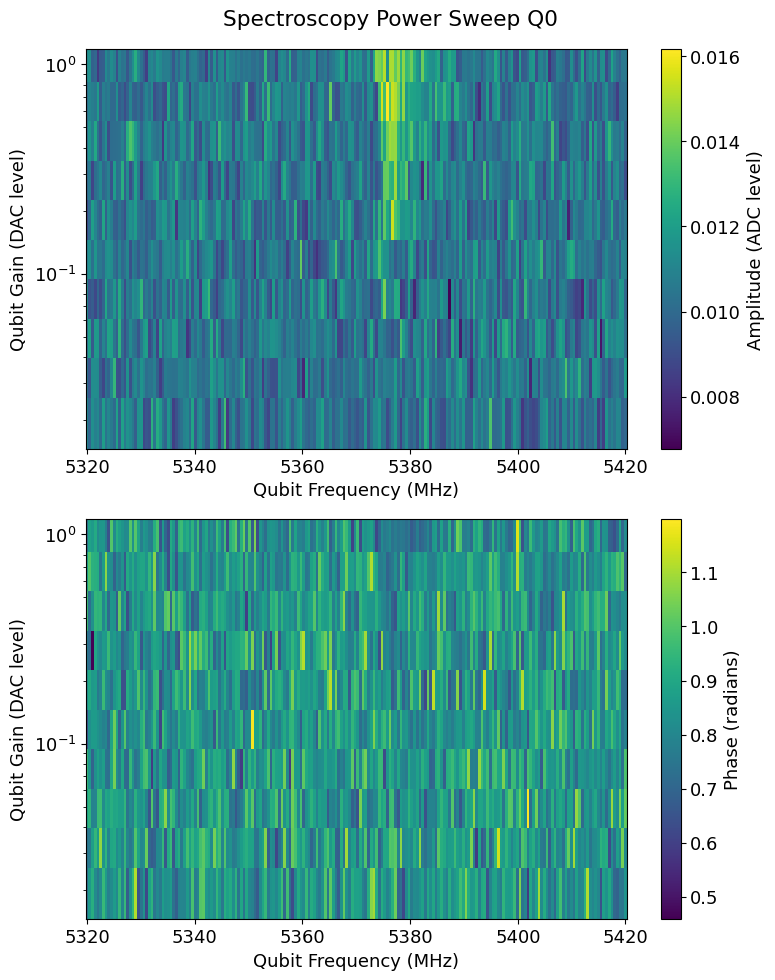

Unexpected parameters found in params: {'max_gain', 'log', 'expts_gain', 'rng'}


  0%|          | 0/10 [00:00<?, ?it/s]

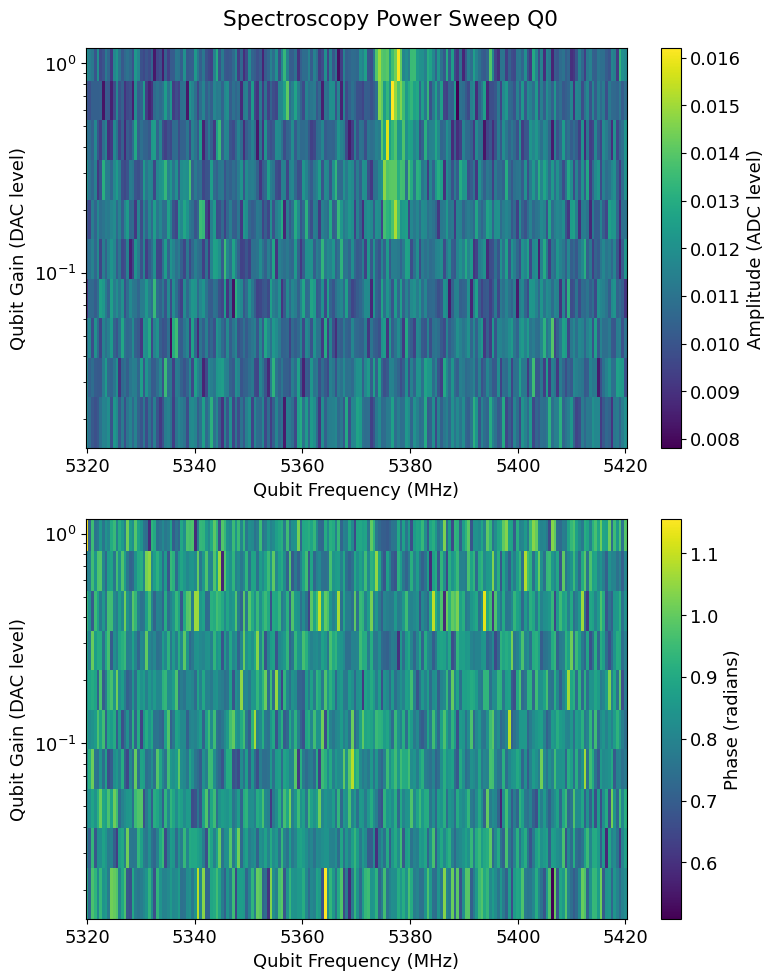

Unexpected parameters found in params: {'max_gain', 'log', 'expts_gain', 'rng'}


  0%|          | 0/10 [00:00<?, ?it/s]

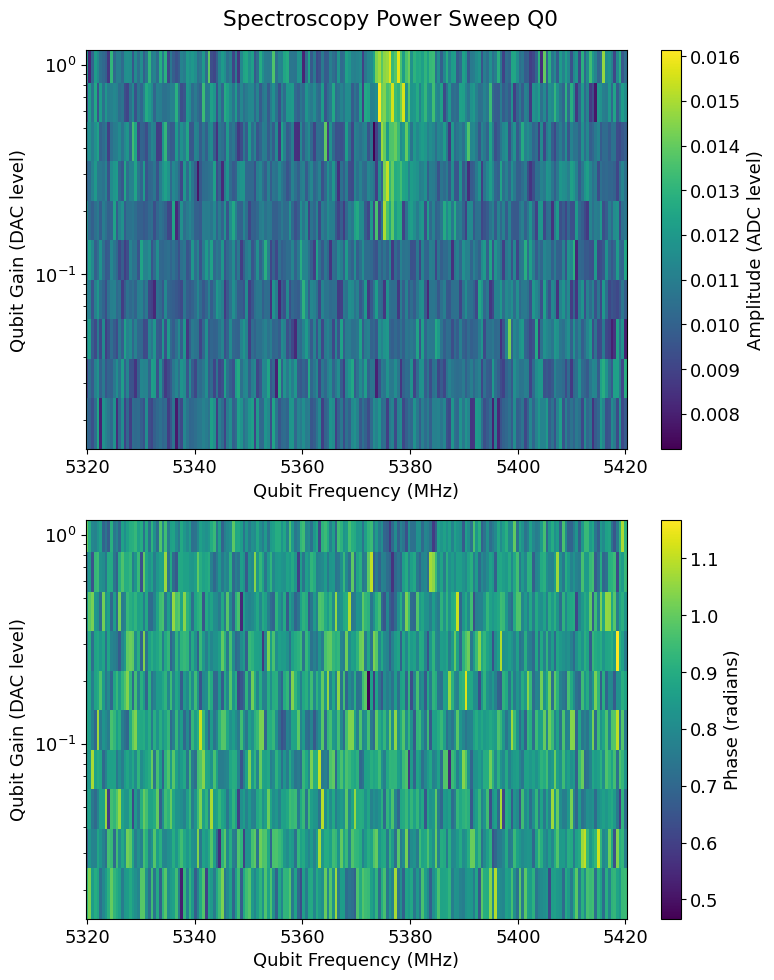

In [160]:
length = [1,3,5,10]
for l in length:
    for qi in qubit_list:
        qspec_pow = meas.QubitSpecPower(cfg_dict, qi=qi, style='', params={'start':5320,'span':100,'reps':1000,'expts':200,'length':l})
        #qspec_pow = meas.QubitSpecPower(cfg_dict, qi=qi, style='', params={'start':3700,'span':600,'reps':1500,'expts':1200, 'max_gain':0.4, 'length':1,'sep_readout':True})

### Narrow scan

Unexpected parameters found in params: {'max_gain', 'log', 'expts_gain', 'rng'}


  0%|          | 0/10 [00:00<?, ?it/s]

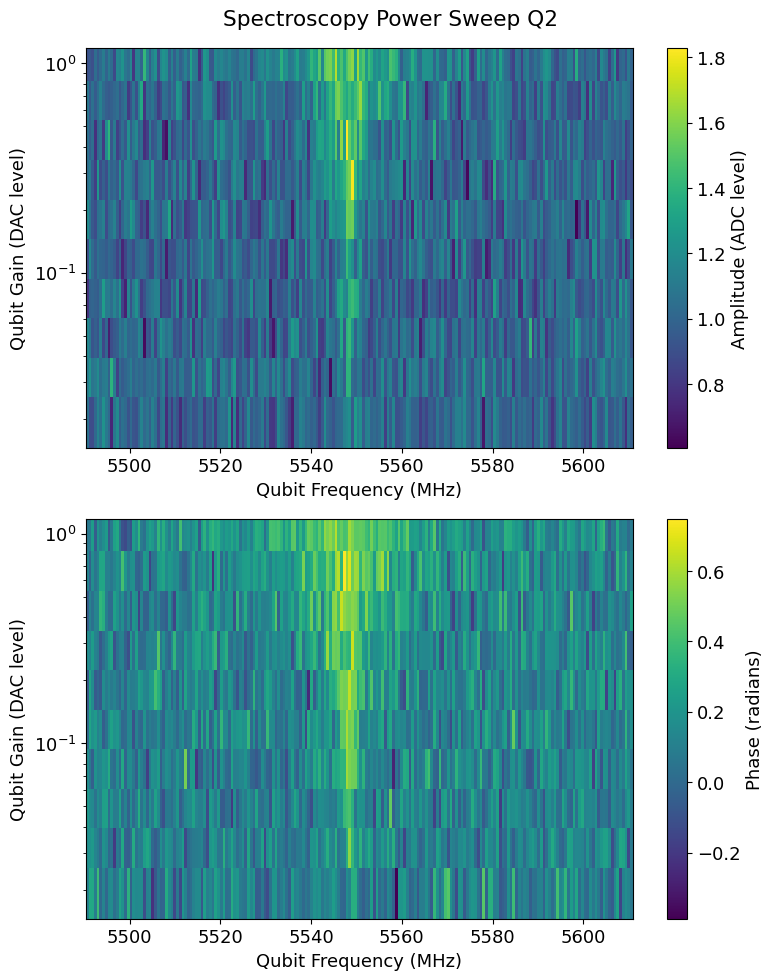

In [ ]:
qq=[]

# qubit_list = np.arange(3)
qubit_list=[2]
for qi in qubit_list:
    qspec_pow = meas.QubitSpecPower(cfg_dict, qi=qi, style='narrow')
    
    # Nice for pretty pics once you have T1 measurement. 
    #qspec_pow = meas.QubitSpecPower(cfg_dict, qi=qi, style='fine', params={'length':'t1','max_gain':1})
    qq.append(qspec_pow)

# When measuring many qubits, can do a bunch of color plots this way
#handy.plot_many(qq, title='Qubit Power Amps 0.6-0.2', save_path=cfg_dict['expt_path'], yax='log', chan='amps')
#handy.plot_many(qq, title='Qubit Power Phase 0.6-0.2', save_path=cfg_dict['expt_path'], yax='log', chan='phases')

### Multiple wide scans looking for qubit

In [ ]:
qubit_list = np.arange(20)
qubit_list=[1]

span = 250
start_all = [2000, 3100, 3400]
end_all = [4780, 3700, 4250]
sensitivities = [0.8, 0.4, 0.2]

d = []
for qi in tqdm(qubit_list, desc='Qubit Number'):
    starts = np.arange(start_all[qi], end_all[qi], span)
    qresults = []
    for start in tqdm(starts, desc=f'Start Frequency Sweep'):
        q_res = meas.QubitSpecPower(
            cfg_dict, 
            qi=qi, 
            style='coarse', 
            params={
                'max_gain':0.8,
                'start':start,
                'span':span,
                'rng':100,
                'reps':800}
        )#,'start':3000,'span':300'})
        qresults.append(q_res)
    
    # Handy plot
    handy.plot_many_limited(
        qresults, 
        title=f'Qubit Power for qubit {qi}', 
        save_path=cfg_dict['expt_path'],
        yax='log', 
        chan='amps', 
        individial_fig_size= (6,6), 
        xlabel='Frequency (MHz)',
        sensitivity =  sensitivities[qi],
        save = False,
    )
    d.append(q_res)
    plt.show()

# Coherent scans

## Fast tuneup

Options are: 

first_time: assume we don't know t1 time,don't have single shot working

single: do single shot readout optimization 

readout: set readout frequency based on resonator fit

  0%|          | 0/33000 [00:00<?, ?it/s]

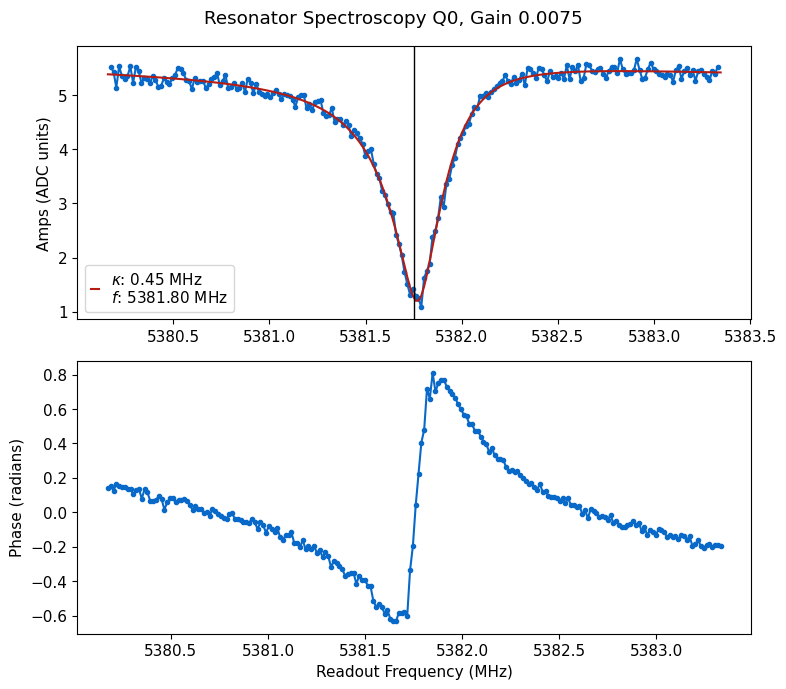

*Set cfg device.readout 0 frequency to 5381.7898 from 5381.7545*
*Set cfg device.readout 0 kappa to 0.45 from 0.4553*
*Set cfg device.readout 0 qi to 5.8042 from 5.9669*
*Set cfg device.readout 0 qe to 1.5064 from 1.4742*


  0%|          | 0/20000 [00:00<?, ?it/s]

  0%|          | 0/20000 [00:00<?, ?it/s]

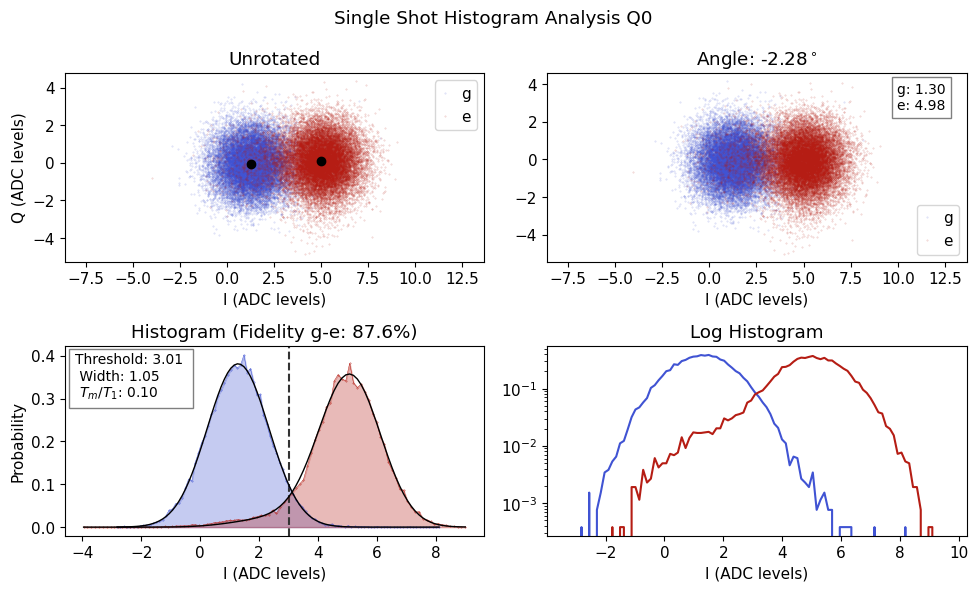

*Set cfg device.readout 0 phase to -2.28 from -179.3948*
*Set cfg device.readout 0 threshold to 3.0066 from 2.7318*
*Set cfg device.readout 0 fidelity to 0.876 from 0.8947*
*Set cfg device.readout 0 sigma to 1.0463 from 1.0487*
*Set cfg device.readout 0 tm to 0.0992 from 0.1103*
*Set cfg device.qubit 0 tuned_up to True from True*


  0%|          | 0/2 [00:00<?, ?it/s]

R2:0.979	Fit par error:0.015	 Best fit:b'amps'


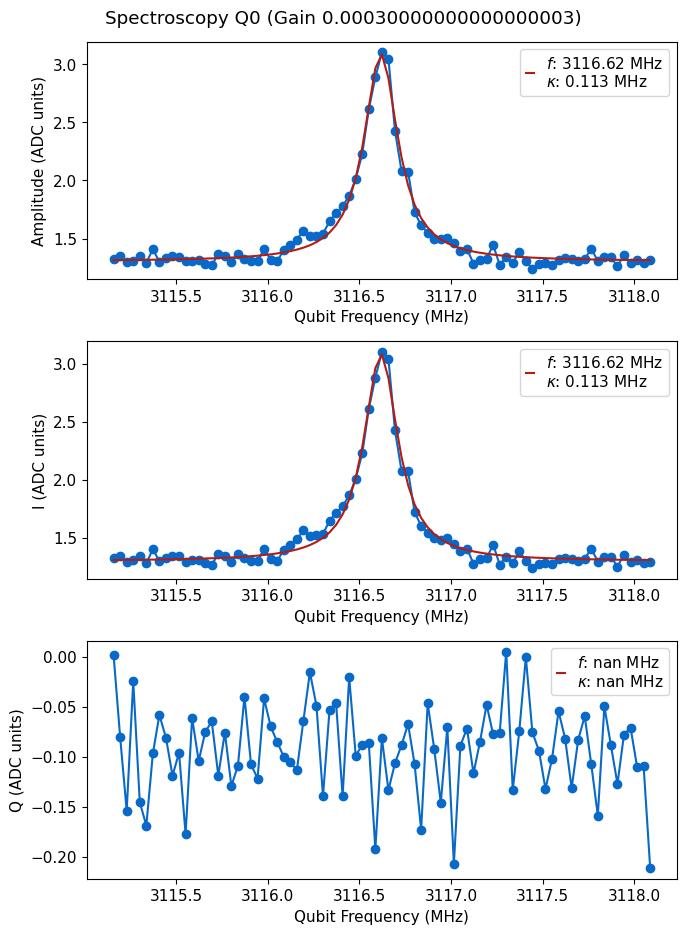

  0%|          | 0/9000 [00:00<?, ?it/s]

R2:0.989	Fit par error:0.010	 Best fit:b'avgi'


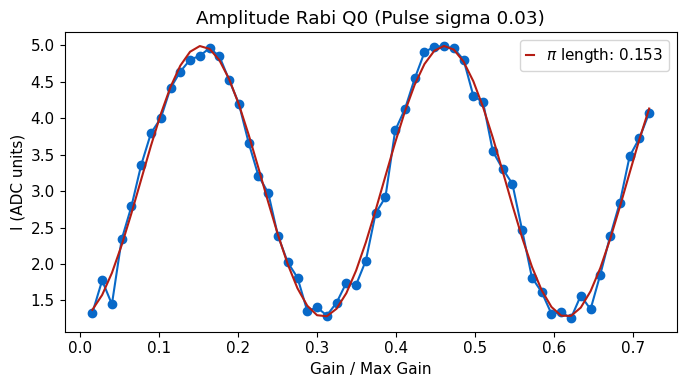

*Set cfg device.qubit 0 ('pulses', 'pi_ge', 'gain') to 0.1534 from 0.1465*
Try 0


  0%|          | 0/30000 [00:00<?, ?it/s]

R2:0.950	Fit par error:0.023	 Best fit:b'avgi'


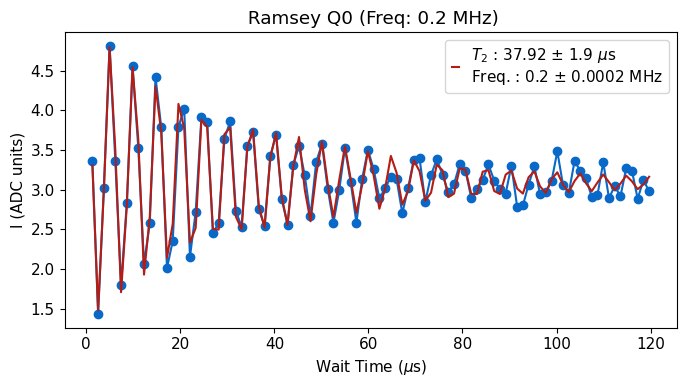

Scan successful. New frequency error is -0.000 MHz
*Set cfg device.qubit 0 f_ge to 3116.6222 from 3116.6224*
*Set cfg device.qubit 0 T2r to 37.9237 from 40.3214*
Total Change in frequency: -0.000 MHz
[-0.0002487283438984411]
Qubit 0 recentered from 3116.6224 to 3116.6222


  0%|          | 0/9000 [00:00<?, ?it/s]

R2:0.984	Fit par error:0.013	 Best fit:b'avgi'


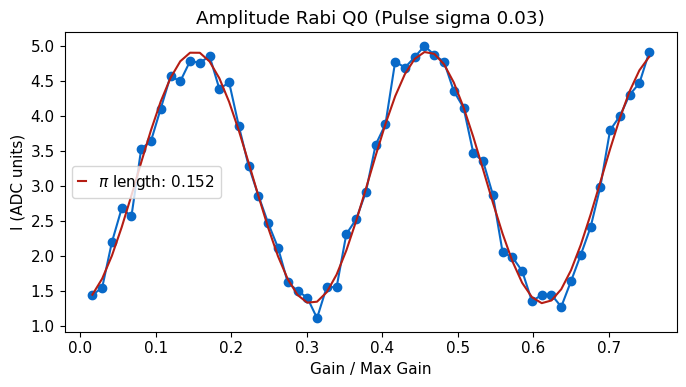

*Set cfg device.qubit 0 ('pulses', 'pi_ge', 'gain') to 0.1517 from 0.1534*


  0%|          | 0/20000 [00:00<?, ?it/s]

  0%|          | 0/20000 [00:00<?, ?it/s]

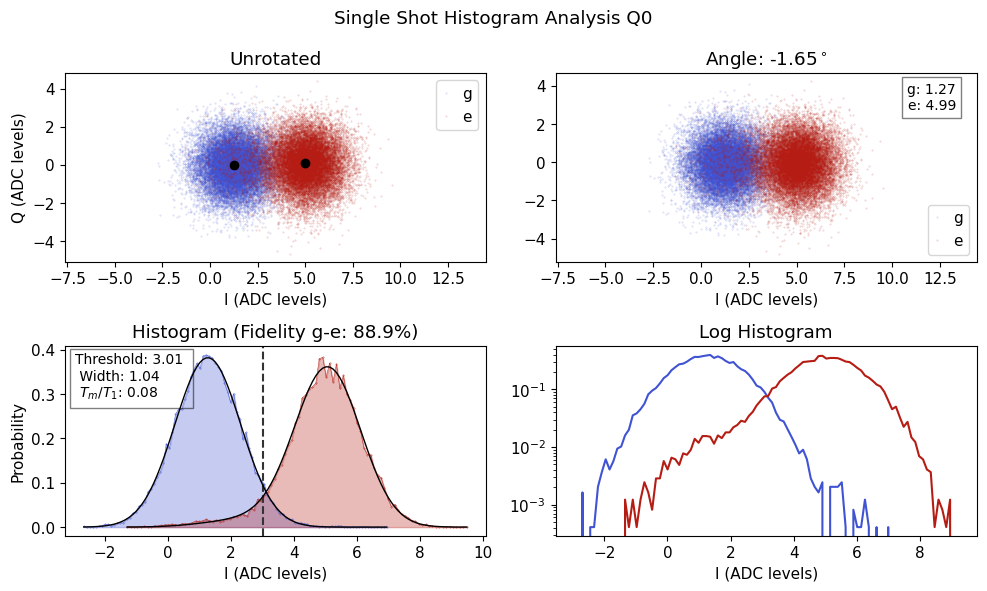

*Set cfg device.readout 0 phase to -1.649 from -2.28*
*Set cfg device.readout 0 threshold to 3.0082 from 3.0066*
*Set cfg device.readout 0 fidelity to 0.8892 from 0.876*
*Set cfg device.readout 0 sigma to 1.0444 from 1.0463*
*Set cfg device.readout 0 tm to 0.0833 from 0.0992*
*Set cfg device.qubit 0 tuned_up to True from True*


  0%|          | 0/30000 [00:00<?, ?it/s]

R2:0.951	Fit par error:0.025	 Best fit:b'avgi'


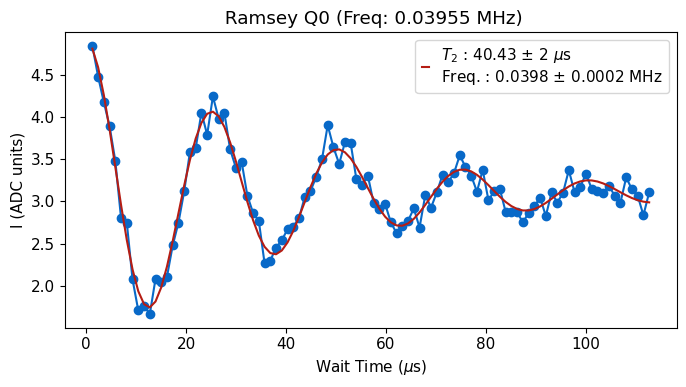

*Set cfg device.qubit 0 T2r to 40.43 from 37.9237*


  0%|          | 0/18000 [00:00<?, ?it/s]

R2:0.984	Fit par error:0.038	 Best fit:b'avgi'


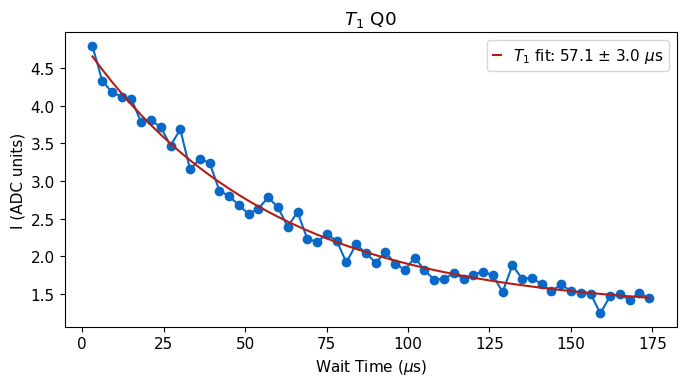

*Set cfg device.qubit 0 T1 to 57.07 from 47.83*
*Set cfg device.readout 0 final_delay to 342.44 from 287.0*


  0%|          | 0/30000 [00:00<?, ?it/s]

R2:0.963	Fit par error:0.024	 Best fit:b'avgi'


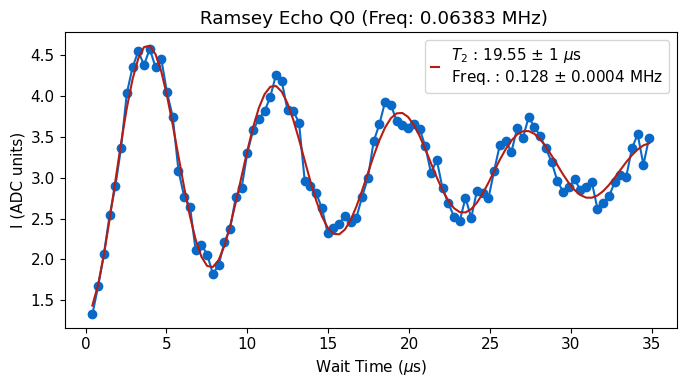

*Set cfg device.qubit 0 T2e to 19.55 from 23.5*


  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/2 [00:00<?, ?it/s]

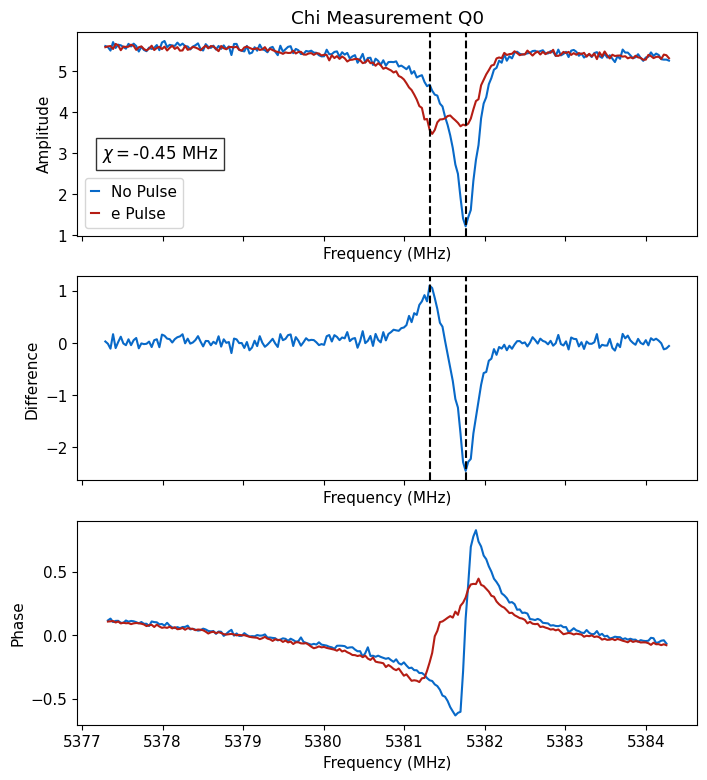

*Set cfg device.readout 0 chi to -0.4473 from -0.4792*


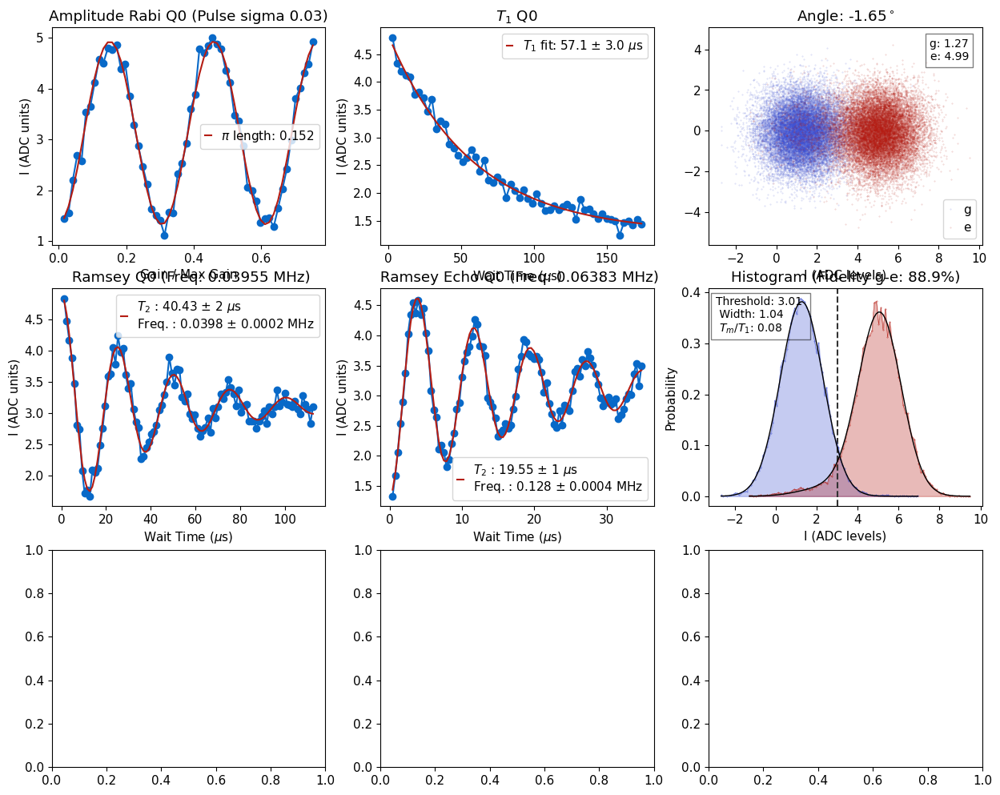

<Figure size 800x400 with 0 Axes>

C:\_Data\Aggron\2025_06_16\images\summary\qubit0_tuneup_20250729_0646.png


  0%|          | 0/33000 [00:00<?, ?it/s]

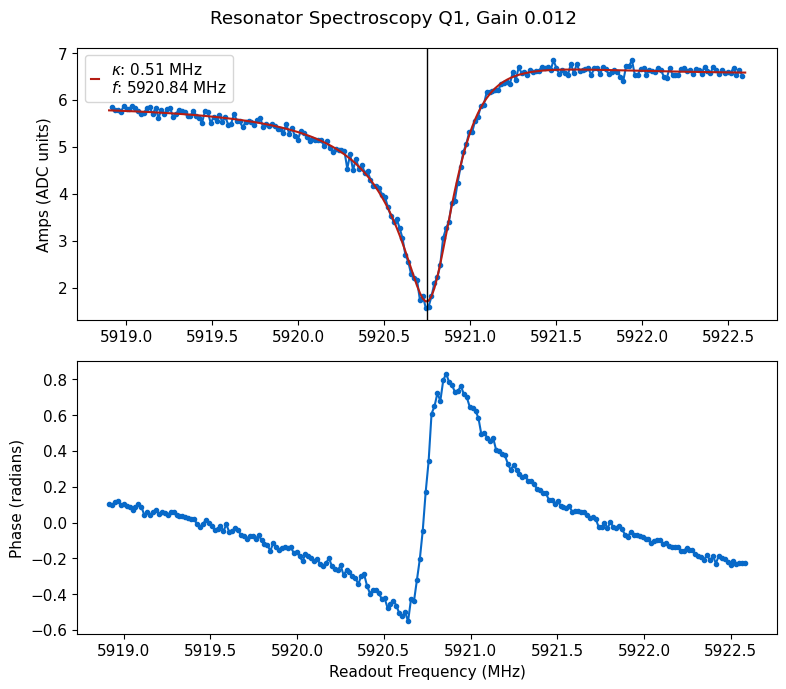

*Set cfg device.readout 1 frequency to 5920.7411 from 5920.75*
*Set cfg device.readout 1 kappa to 0.5131 from 0.5286*
*Set cfg device.readout 1 qi to 5.3908 from 5.9912*
*Set cfg device.readout 1 qe to 1.4682 from 1.3778*


  0%|          | 0/20000 [00:00<?, ?it/s]

  0%|          | 0/20000 [00:00<?, ?it/s]

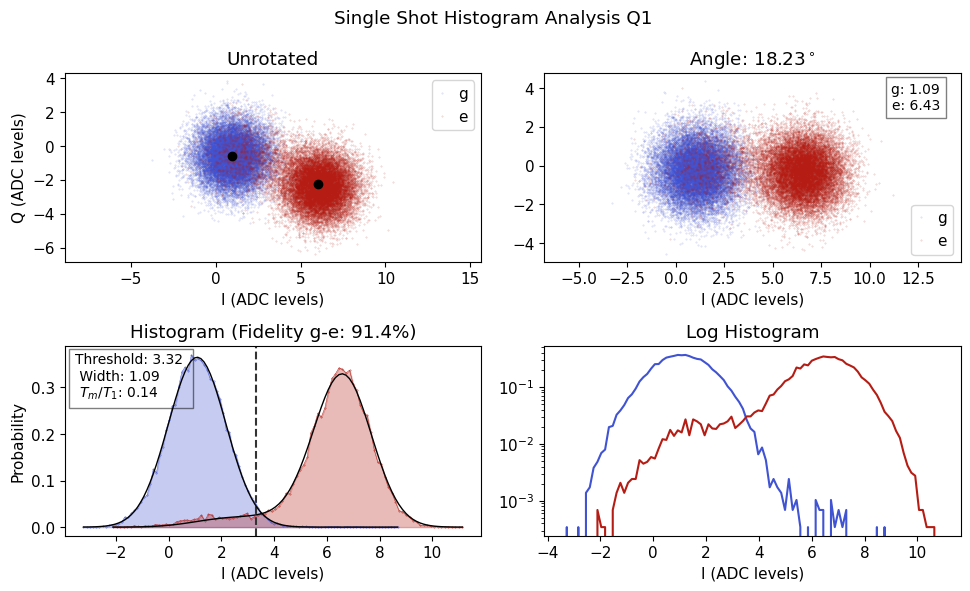

*Set cfg device.readout 1 phase to 18.2327 from -137.039*
*Set cfg device.readout 1 threshold to 3.323 from 3.407*
*Set cfg device.readout 1 fidelity to 0.9144 from 0.8836*
*Set cfg device.readout 1 sigma to 1.0931 from 1.0697*
*Set cfg device.readout 1 tm to 0.137 from 0.164*
*Set cfg device.qubit 1 tuned_up to True from True*


  0%|          | 0/2 [00:00<?, ?it/s]

R2:0.990	Fit par error:0.014	 Best fit:b'amps'


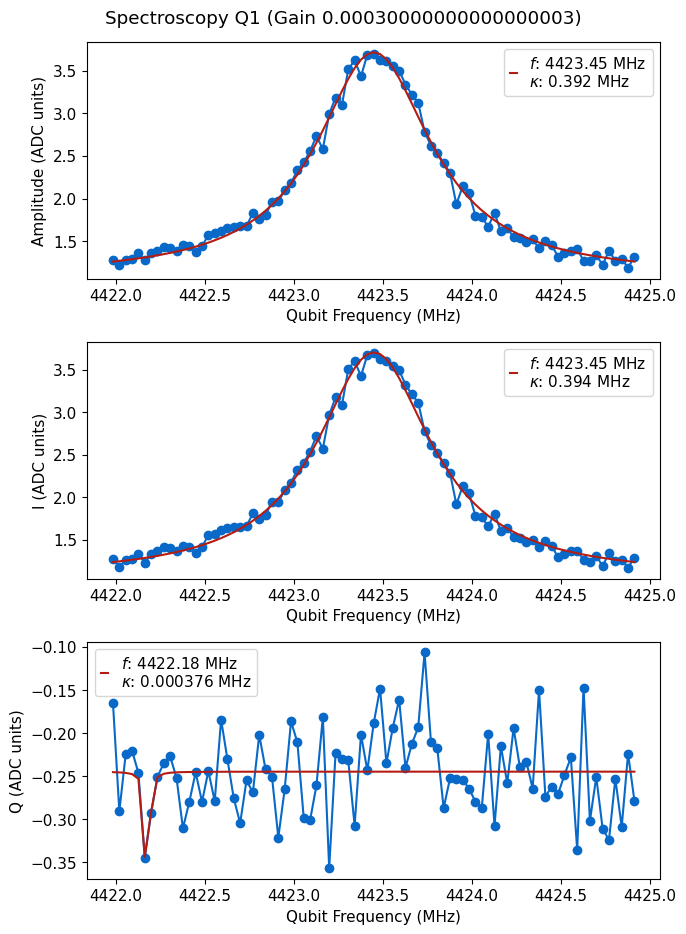

  0%|          | 0/9000 [00:00<?, ?it/s]

R2:0.989	Fit par error:0.008	 Best fit:b'avgi'


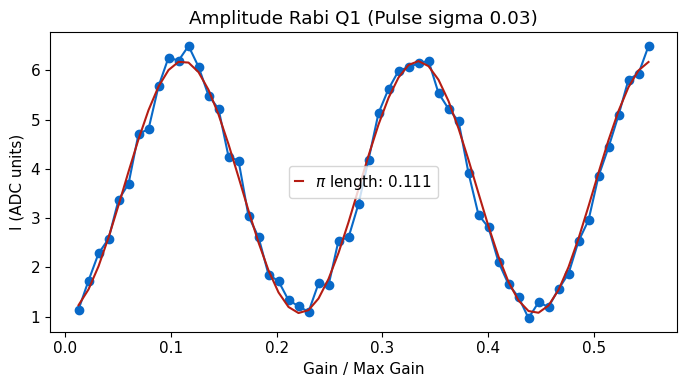

*Set cfg device.qubit 1 ('pulses', 'pi_ge', 'gain') to 0.111 from 0.1126*
Try 0


  0%|          | 0/30000 [00:00<?, ?it/s]

R2:0.609	Fit par error:0.100	 Best fit:b'avgi'


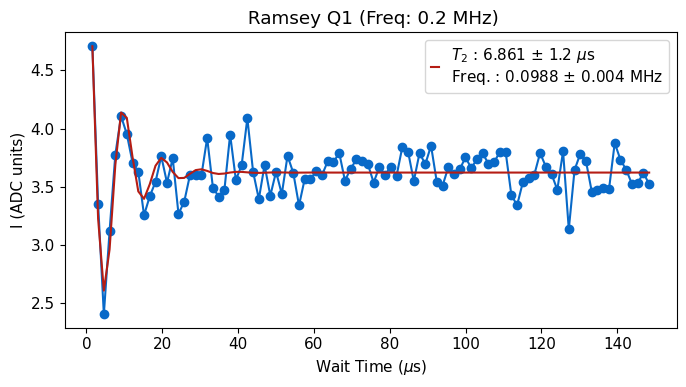

Scan successful. New frequency error is 0.101 MHz
*Set cfg device.qubit 1 f_ge to 4423.55 from 4423.4488*
*Set cfg device.qubit 1 T2r to 6.8615 from 50*
Try 1


  0%|          | 0/30000 [00:00<?, ?it/s]

R2:0.867	Fit par error:0.065	 Best fit:b'avgi'


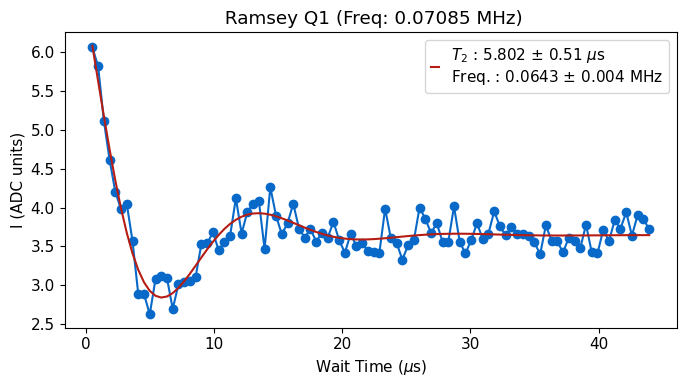

Scan successful. New frequency error is 0.007 MHz
*Set cfg device.qubit 1 f_ge to 4423.5566 from 4423.55*
*Set cfg device.qubit 1 T2r to 5.8023 from 6.8615*
Total Change in frequency: 0.108 MHz
[0.1012101003684522, 0.006570821895527948]
Qubit 1 recentered from 4423.4488 to 4423.5566


  0%|          | 0/9000 [00:00<?, ?it/s]

R2:0.991	Fit par error:0.009	 Best fit:b'avgi'


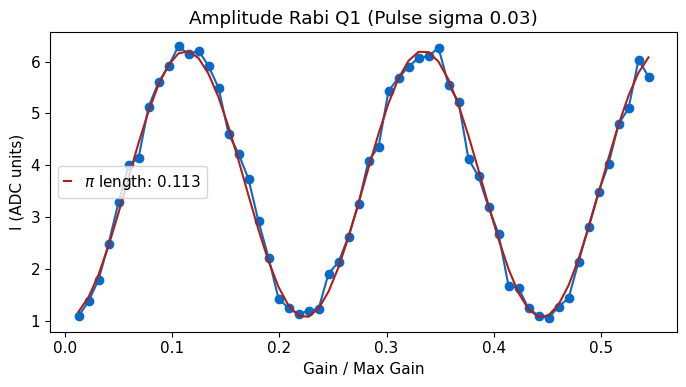

*Set cfg device.qubit 1 ('pulses', 'pi_ge', 'gain') to 0.1127 from 0.111*


  0%|          | 0/20000 [00:00<?, ?it/s]

  0%|          | 0/20000 [00:00<?, ?it/s]

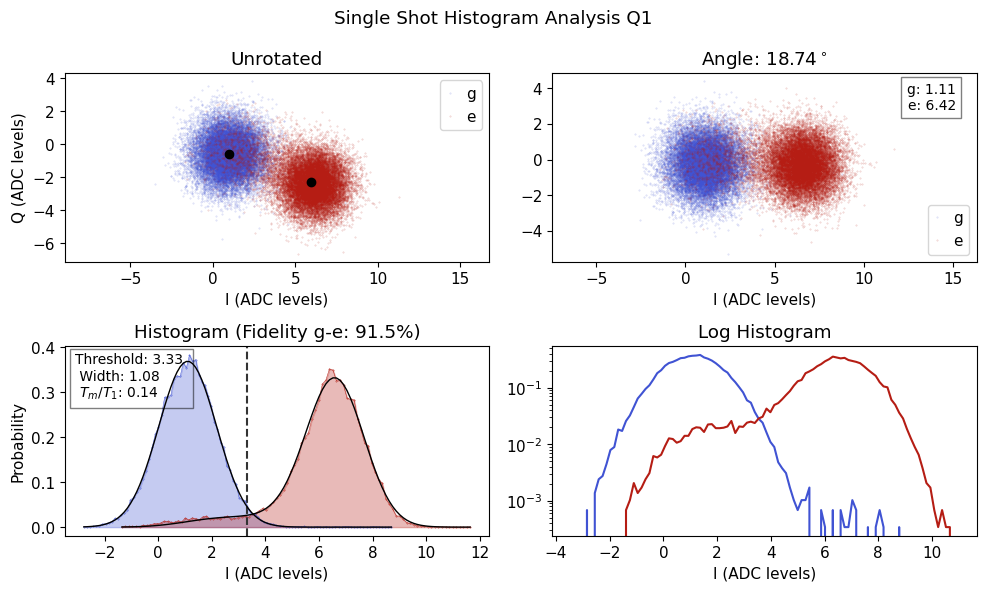

*Set cfg device.readout 1 phase to 18.7392 from 18.2327*
*Set cfg device.readout 1 threshold to 3.328 from 3.323*
*Set cfg device.readout 1 fidelity to 0.9151 from 0.9144*
*Set cfg device.readout 1 sigma to 1.0808 from 1.0931*
*Set cfg device.readout 1 tm to 0.1385 from 0.137*
*Set cfg device.qubit 1 tuned_up to True from True*


  0%|          | 0/30000 [00:00<?, ?it/s]

R2:0.937	Fit par error:0.029	 Best fit:b'avgi'


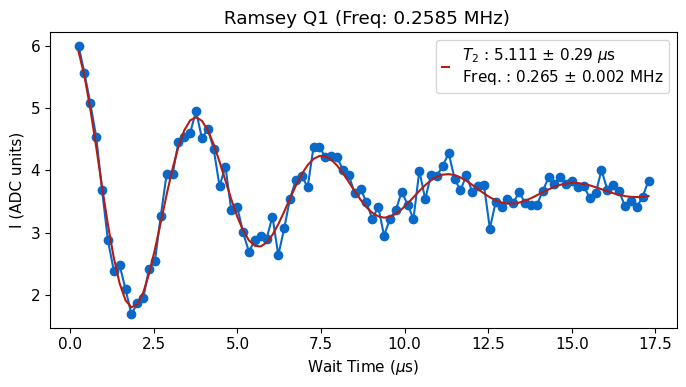

*Set cfg device.qubit 1 T2r to 5.11 from 5.8023*


  0%|          | 0/18000 [00:00<?, ?it/s]

R2:0.988	Fit par error:0.024	 Best fit:b'avgi'


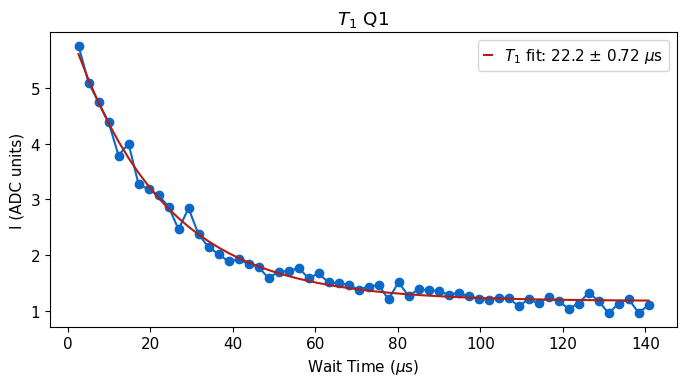

*Set cfg device.qubit 1 T1 to 22.23 from 38.69*


  0%|          | 0/18000 [00:00<?, ?it/s]

R2:0.988	Fit par error:0.033	 Best fit:b'avgi'


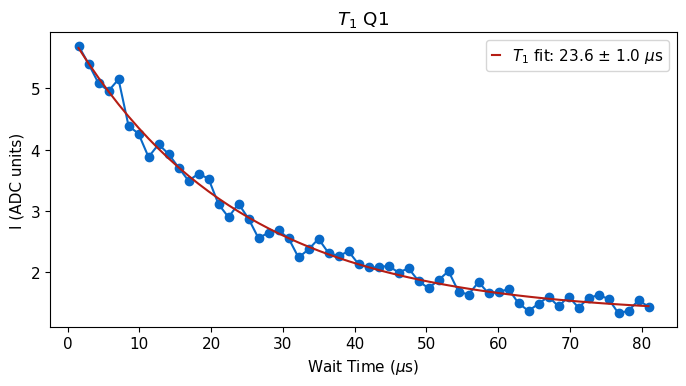

*Set cfg device.qubit 1 T1 to 23.57 from 22.23*
*Set cfg device.readout 1 final_delay to 141.43 from 232.15*


  0%|          | 0/30000 [00:00<?, ?it/s]

R2:0.973	Fit par error:0.022	 Best fit:b'avgi'


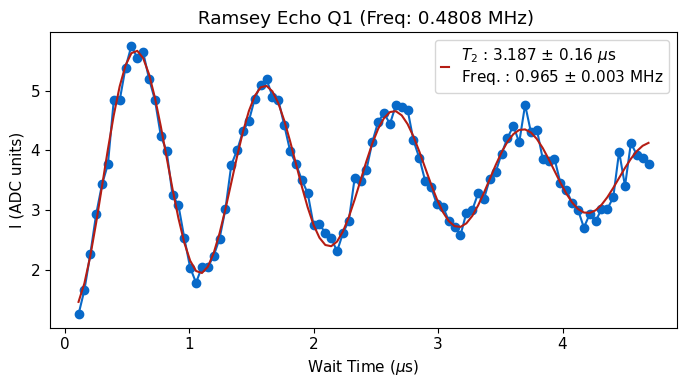

*Set cfg device.qubit 1 T2e to 3.19 from 3.12*


  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/2 [00:00<?, ?it/s]

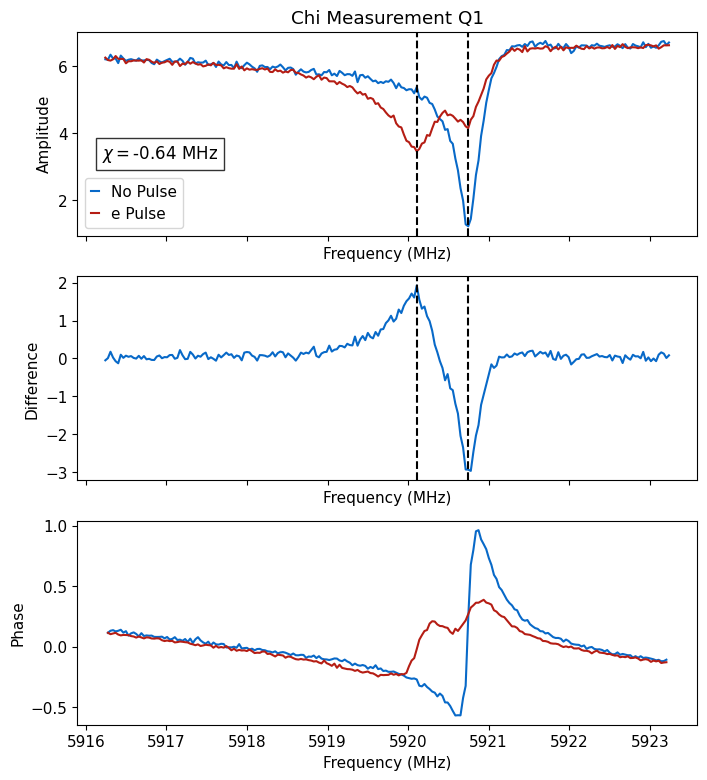

*Set cfg device.readout 1 chi to -0.639 from -0.639*


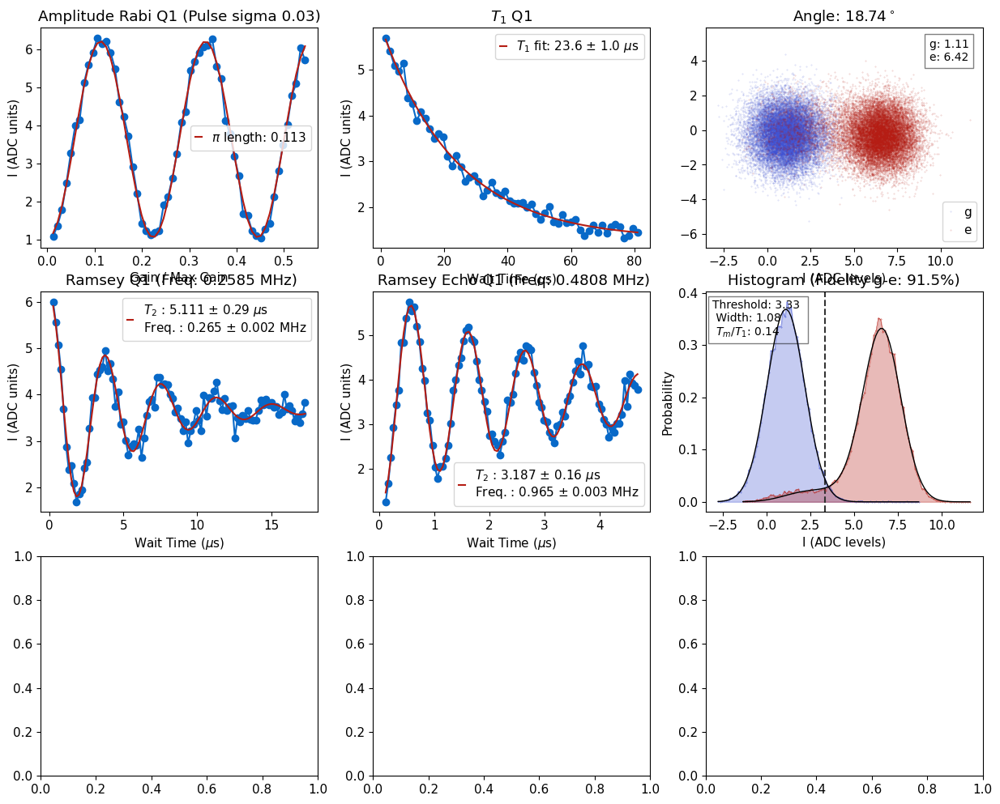

<Figure size 800x400 with 0 Axes>

C:\_Data\Aggron\2025_06_16\images\summary\qubit1_tuneup_20250729_0648.png


  0%|          | 0/33000 [00:00<?, ?it/s]

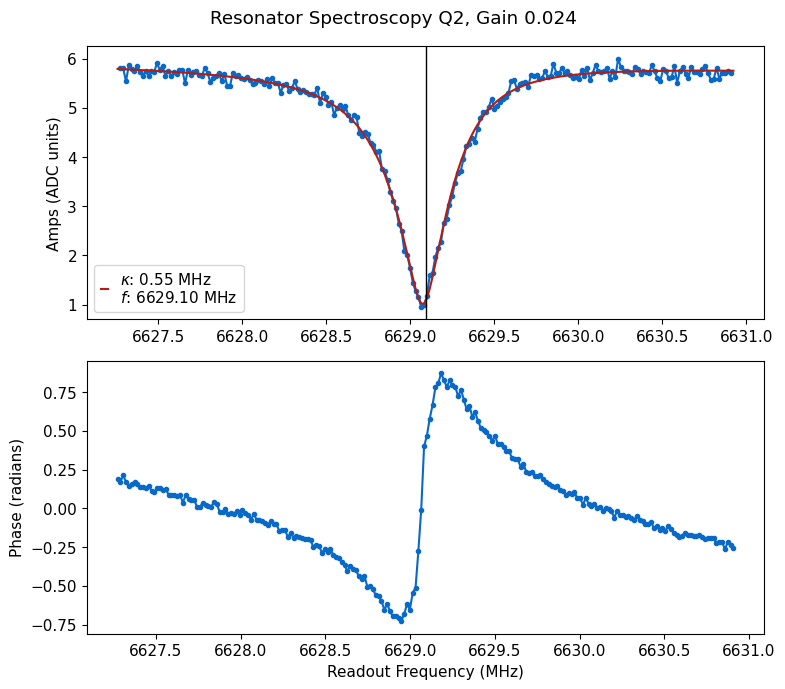

*Set cfg device.readout 2 frequency to 6629.0655 from 6629.0915*
*Set cfg device.readout 2 kappa to 0.555 from 0.5242*
*Set cfg device.readout 2 qi to 7.0546 from 9.443*
*Set cfg device.readout 2 qe to 1.4379 from 1.46*


  0%|          | 0/20000 [00:00<?, ?it/s]

  0%|          | 0/20000 [00:00<?, ?it/s]

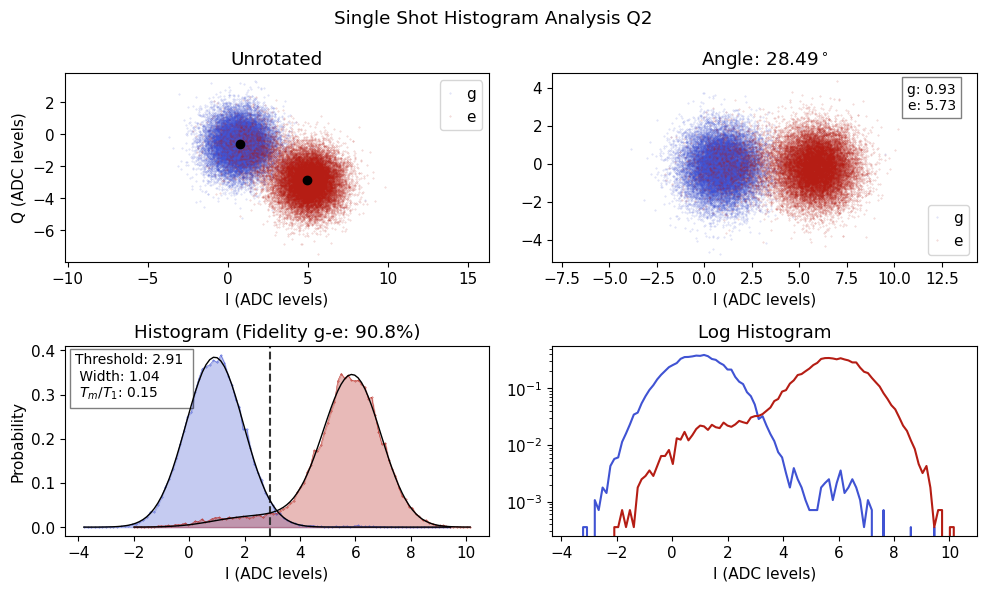

*Set cfg device.readout 2 phase to 28.4898 from -35.7895*
*Set cfg device.readout 2 threshold to 2.9072 from 3.0357*
*Set cfg device.readout 2 fidelity to 0.9077 from 0.9066*
*Set cfg device.readout 2 sigma to 1.0373 from 1.0208*
*Set cfg device.readout 2 tm to 0.1463 from 0.1379*
*Set cfg device.qubit 2 tuned_up to True from True*


  0%|          | 0/2 [00:00<?, ?it/s]

R2:0.912	Fit par error:0.037	 Best fit:b'amps'


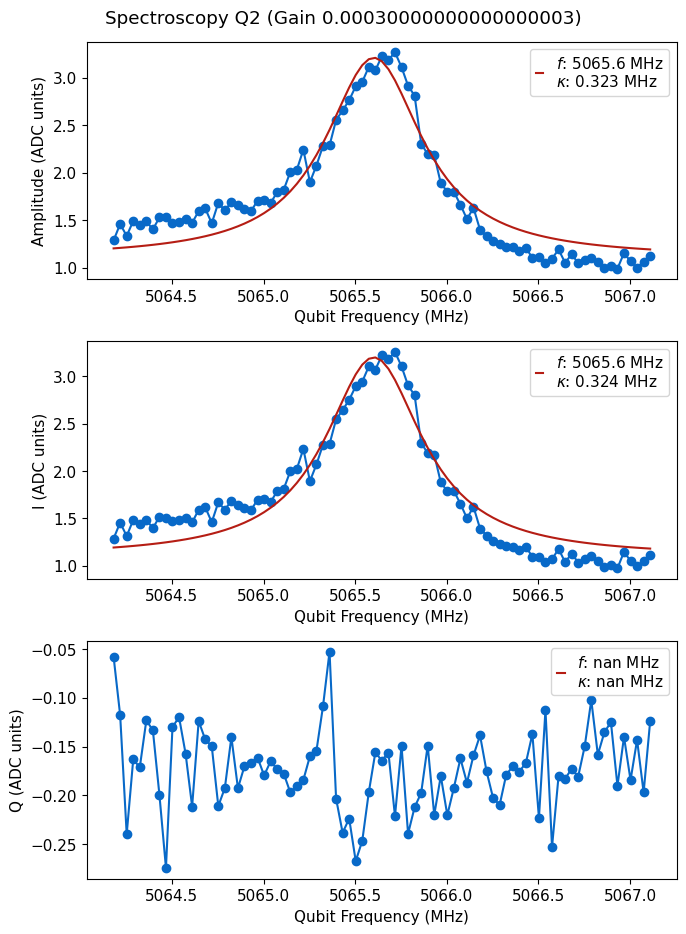

  0%|          | 0/9000 [00:00<?, ?it/s]

R2:0.985	Fit par error:0.013	 Best fit:b'avgi'


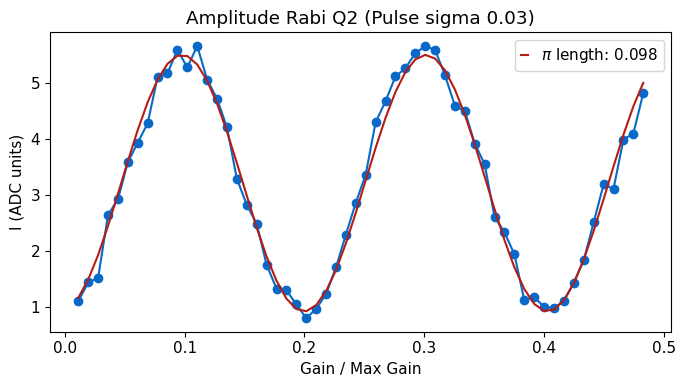

*Set cfg device.qubit 2 ('pulses', 'pi_ge', 'gain') to 0.0979 from 0.0984*
Try 0


  0%|          | 0/30000 [00:00<?, ?it/s]

R2:0.859	Fit par error:0.035	 Best fit:b'avgi'


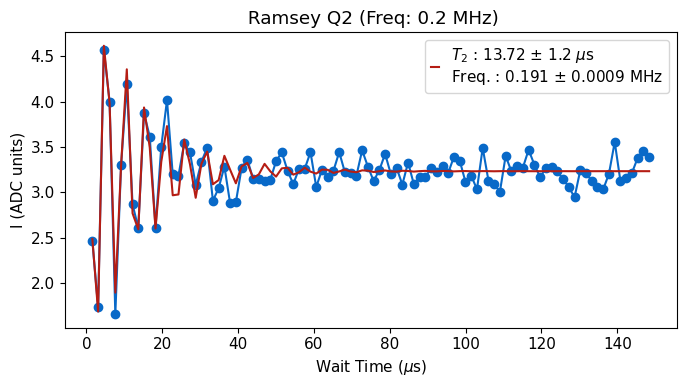

Scan successful. New frequency error is 0.009 MHz
*Set cfg device.qubit 2 f_ge to 5065.6553 from 5065.646*
*Set cfg device.qubit 2 T2r to 13.7219 from 50*
Total Change in frequency: 0.009 MHz
[0.009294499046611476]
Qubit 2 recentered from 5065.646 to 5065.6553


  0%|          | 0/9000 [00:00<?, ?it/s]

R2:0.990	Fit par error:0.010	 Best fit:b'avgi'


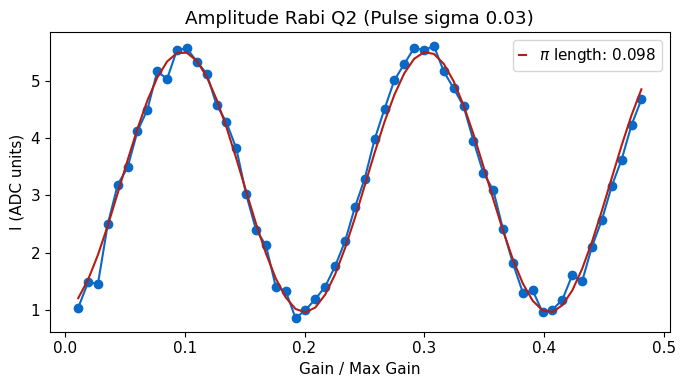

*Set cfg device.qubit 2 ('pulses', 'pi_ge', 'gain') to 0.098 from 0.0979*


  0%|          | 0/20000 [00:00<?, ?it/s]

  0%|          | 0/20000 [00:00<?, ?it/s]

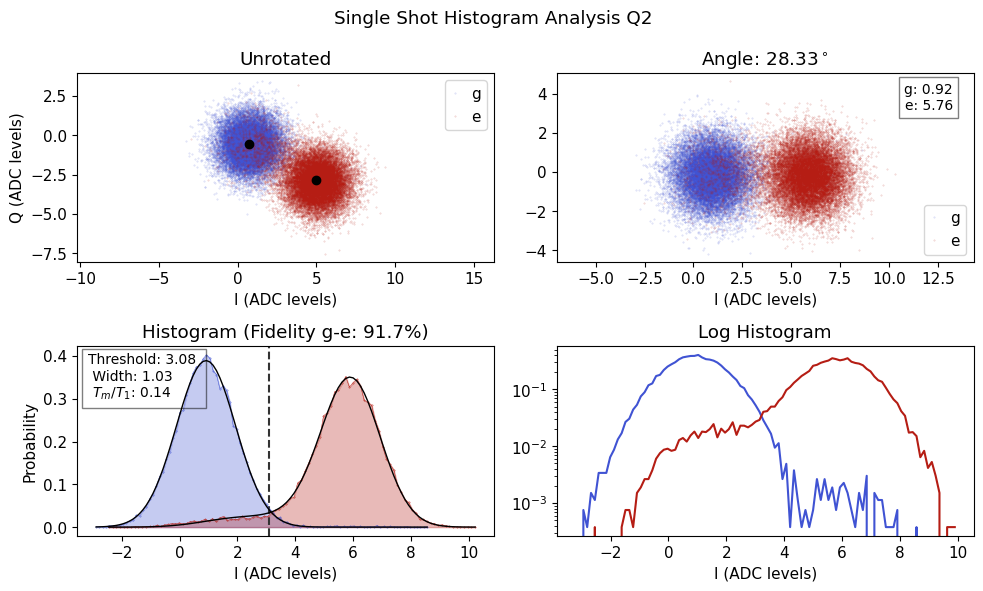

*Set cfg device.readout 2 phase to 28.3293 from 28.4898*
*Set cfg device.readout 2 threshold to 3.078 from 2.9072*
*Set cfg device.readout 2 fidelity to 0.9174 from 0.9077*
*Set cfg device.readout 2 sigma to 1.0253 from 1.0373*
*Set cfg device.readout 2 tm to 0.1409 from 0.1463*
*Set cfg device.qubit 2 tuned_up to True from True*


  0%|          | 0/30000 [00:00<?, ?it/s]

R2:0.960	Fit par error:0.022	 Best fit:b'avgi'


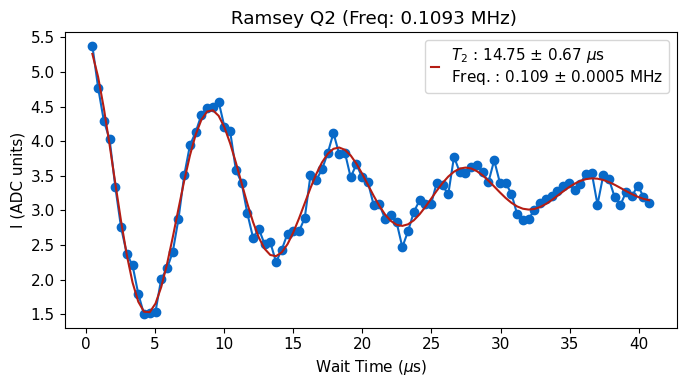

*Set cfg device.qubit 2 T2r to 14.75 from 13.7219*


  0%|          | 0/18000 [00:00<?, ?it/s]

R2:0.992	Fit par error:0.025	 Best fit:b'avgi'


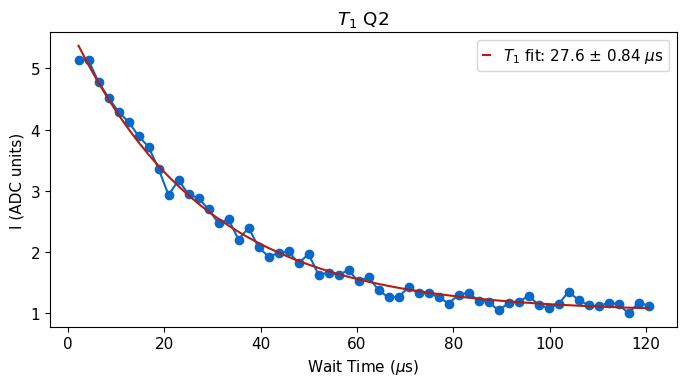

*Set cfg device.qubit 2 T1 to 27.65 from 33.1*
*Set cfg device.readout 2 final_delay to 165.88 from 198.58*


  0%|          | 0/30000 [00:00<?, ?it/s]

R2:0.977	Fit par error:0.020	 Best fit:b'avgi'


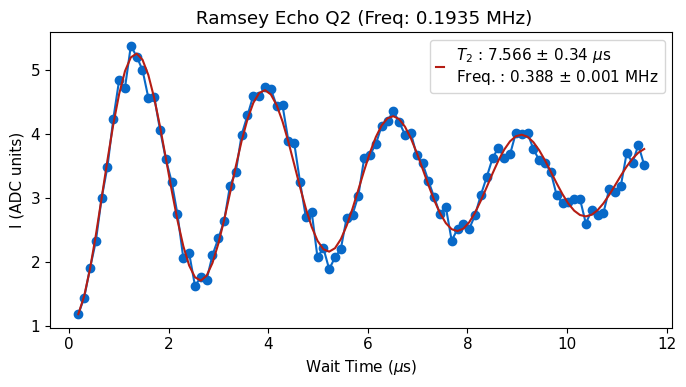

*Set cfg device.qubit 2 T2e to 7.57 from 7.75*


  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/2 [00:00<?, ?it/s]

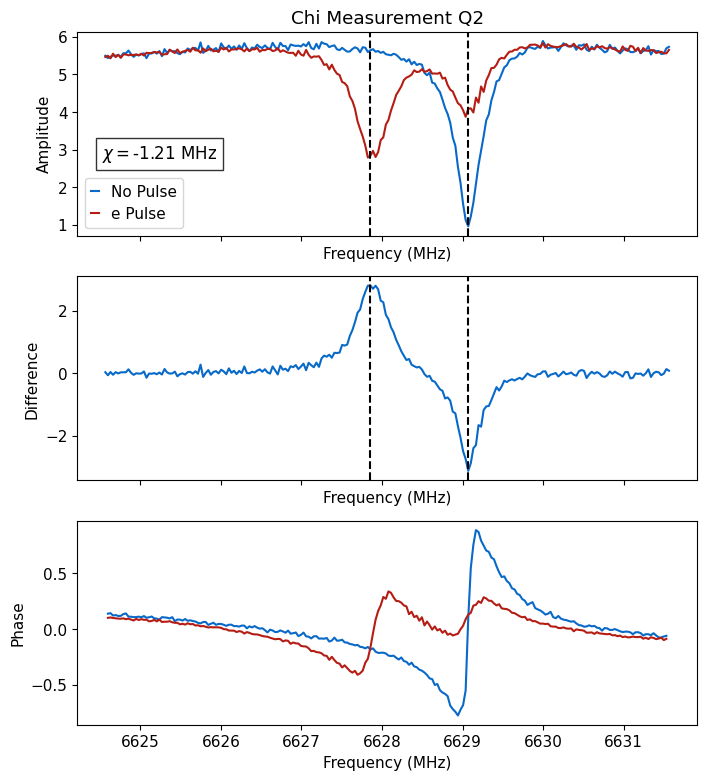

*Set cfg device.readout 2 chi to -1.2141 from -1.1502*


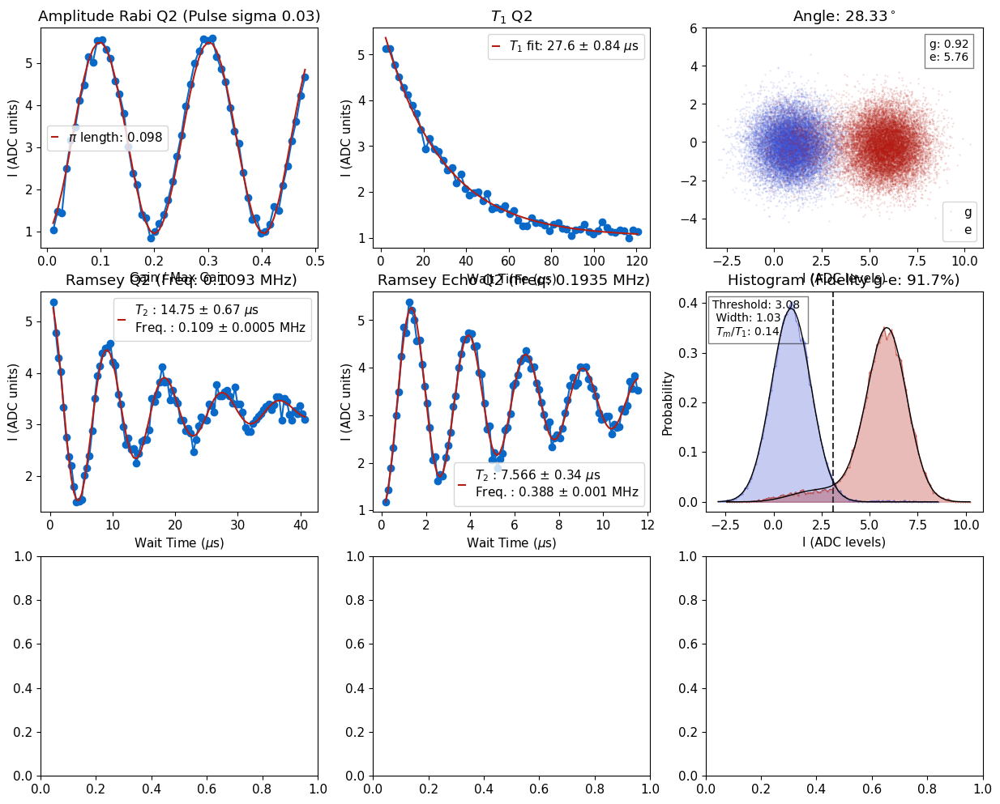

<Figure size 800x400 with 0 Axes>

C:\_Data\Aggron\2025_06_16\images\summary\qubit2_tuneup_20250729_0649.png


In [23]:
qubit_list = np.arange(3)
qubit_list=[0,1,2]

#qubit_list=np.delete(qubit_list, [5,13])
# Worst issue with this right now is when the qubit frequency is not correct and readout is bad; gets stuck doing ramsey/spectroscopy forever. In this case, cancel it and go back to find qubits, try changing readout gain. 
plt.rcParams.update({'font.size': 11})
for qi in qubit_list: 
    qubit_tuning.tune_up_qubit(qi, cfg_dict, first_time=False, single=False, readout=True)

## Time tracking
fast = True only measures T2r and T1, otherwise does full set of scans.

In [ ]:
scan_length = 24 #  hours 

qubit_list = [0,1,2]
tt=time_tracking(qubit_list, cfg_dict,display=False,total_time=scan_length, fast=True)

Starting run 0, for qubit 0. Time elapsed 0.00 hrs
R2:0.989	Fit par error:0.050	 Best fit:b'avgi'
R2:0.944	Fit par error:0.039	 Best fit:b'avgi'
Starting run 0, for qubit 1. Time elapsed 0.00 hrs
R2:0.991	Fit par error:0.043	 Best fit:b'avgi'
R2:0.531	Fit par error:0.132	 Best fit:b'avgi'
Starting run 0, for qubit 2. Time elapsed 0.00 hrs
R2:0.990	Fit par error:0.045	 Best fit:b'avgi'
R2:0.749	Fit par error:0.331	 Best fit:b'avgi'
Starting run 1, for qubit 0. Time elapsed 0.01 hrs
R2:0.982	Fit par error:0.119	 Best fit:b'avgi'
R2:0.980	Fit par error:0.033	 Best fit:b'avgi'
Starting run 1, for qubit 1. Time elapsed 0.01 hrs
R2:0.994	Fit par error:0.026	 Best fit:b'avgi'
R2:0.526	Fit par error:0.154	 Best fit:b'avgi'
Starting run 1, for qubit 2. Time elapsed 0.01 hrs
R2:0.990	Fit par error:0.038	 Best fit:b'avgi'
R2:nan	Fit par error:nan	 Best fit:b'avgi'
R2:0.975	Fit par error:0.400	 Best fit:b'avgi'
Starting run 2, for qubit 0. Time elapsed 0.01 hrs
R2:0.985	Fit par error:0.069	 Best f

 C:\_Lib\python\slab_qick_calib\fitting.py: 593

R2:0.459	Fit par error:0.731	 Best fit:b'avgi'
Starting run 30, for qubit 2. Time elapsed 0.31 hrs
R2:0.993	Fit par error:0.034	 Best fit:b'avgi'
R2:nan	Fit par error:nan	 Best fit:b'avgi'
R2:0.967	Fit par error:5.722	 Best fit:b'avgi'
Starting run 31, for qubit 0. Time elapsed 0.31 hrs
R2:0.986	Fit par error:0.079	 Best fit:b'avgi'
R2:0.982	Fit par error:0.029	 Best fit:b'avgi'
Starting run 31, for qubit 1. Time elapsed 0.31 hrs
R2:0.988	Fit par error:0.043	 Best fit:b'avgi'
R2:0.513	Fit par error:0.235	 Best fit:b'avgi'
Starting run 31, for qubit 2. Time elapsed 0.32 hrs
R2:0.993	Fit par error:0.034	 Best fit:b'avgi'
R2:0.975	Fit par error:2.014	 Best fit:b'avgi'
R2:0.975	Fit par error:4.056	 Best fit:b'avgi'
Starting run 32, for qubit 0. Time elapsed 0.32 hrs
R2:0.987	Fit par error:0.065	 Best fit:b'avgi'
R2:0.938	Fit par error:0.042	 Best fit:b'avgi'
Starting run 32, for qubit 1. Time elapsed 0.32 hrs
R2:0.993	Fit par error:0.034	 Best fit:b'avgi'
R2:nan	Fit par error:nan	 Best fit

## Rabi

### Amplitude

Uses gain/sigma set in pulses part of config

  0%|          | 0/9000 [00:00<?, ?it/s]

R2:0.986	Fit par error:0.012	 Best fit:b'avgi'


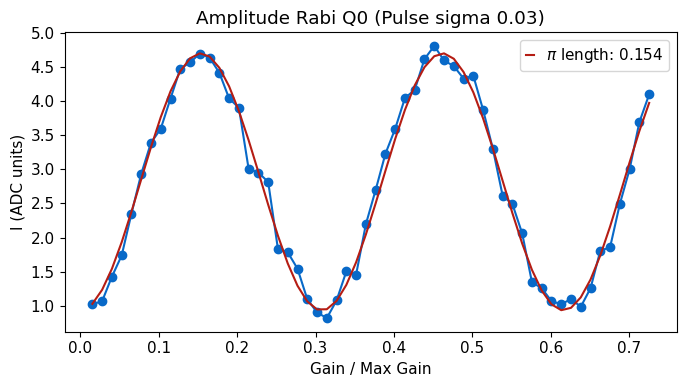

*Set cfg device.qubit 0 ('pulses', 'pi_ge', 'gain') to 0.1538 from 0.1477*


In [21]:
qubit_list = np.arange(3)
qubit_list=[0]

update=True

for qi in qubit_list: 
    amp_rabi = meas.RabiExperiment(cfg_dict,qi=qi)
    
    # Fully customized version
    #amp_rabi = meas.RabiExperiment(cfg_dict,qi=qi, params={'expts':500,'max_gain':0.1})
    #amp_rabi = meas.RabiExperiment(cfg_dict,qi=qi, params={'pulse_type':'flat_top'})

    if update and amp_rabi.status:
        config.update_qubit(cfg_path, ('pulses','pi_ge','gain'), amp_rabi.data['pi_length'], qi)
        

### Multiple pulses

  0%|          | 0/9000 [00:00<?, ?it/s]

R2:0.991	Fit par error:0.022	 Best fit:b'avgi'


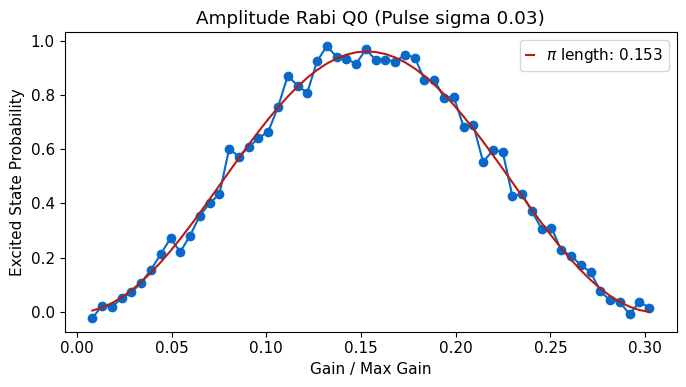

*Set cfg device.qubit 0 ('pulses', 'pi_ge', 'gain') to 0.1532 from 0.1538*


  0%|          | 0/9000 [00:00<?, ?it/s]

R2:0.988	Fit par error:0.029	 Best fit:b'avgi'


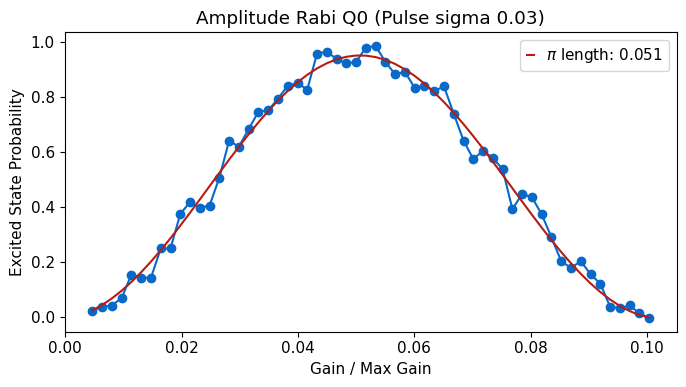

*Set cfg device.qubit 0 ('pulses', 'pi_ge', 'gain') to 0.1521 from 0.1532*


  0%|          | 0/9000 [00:00<?, ?it/s]

R2:0.986	Fit par error:0.031	 Best fit:b'avgi'


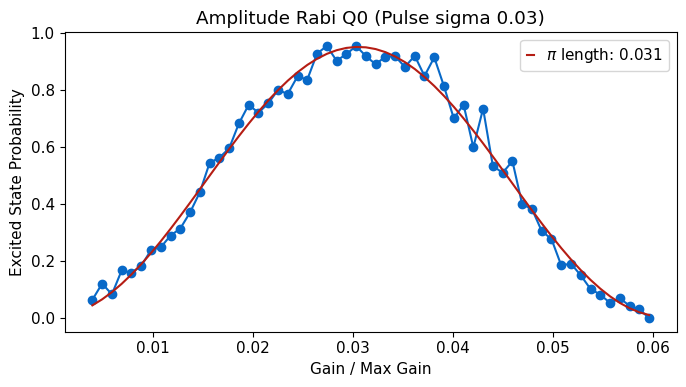

*Set cfg device.qubit 0 ('pulses', 'pi_ge', 'gain') to 0.1527 from 0.1521*


  0%|          | 0/9000 [00:00<?, ?it/s]

R2:0.990	Fit par error:0.032	 Best fit:b'avgi'


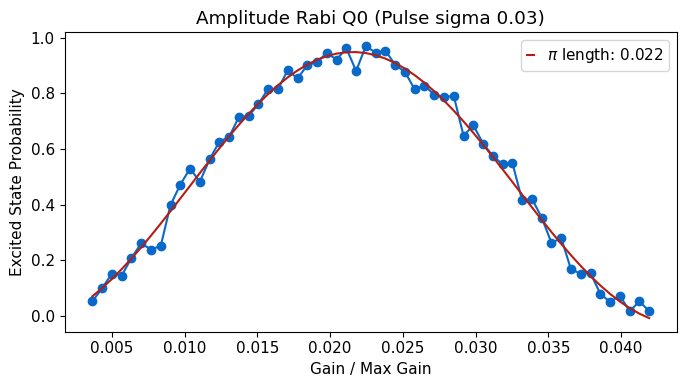

*Set cfg device.qubit 0 ('pulses', 'pi_ge', 'gain') to 0.1509 from 0.1527*


  0%|          | 0/9000 [00:00<?, ?it/s]

R2:0.983	Fit par error:0.059	 Best fit:b'avgi'


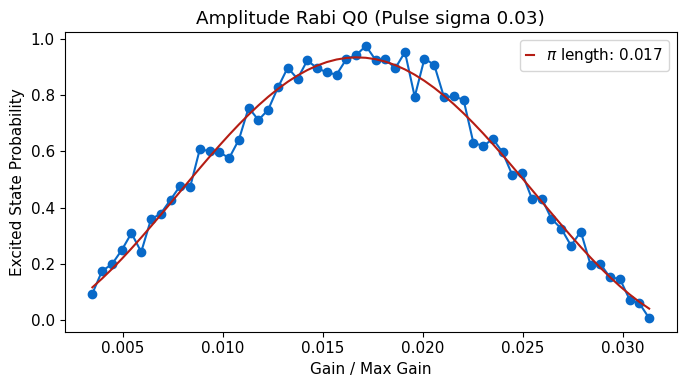

*Set cfg device.qubit 0 ('pulses', 'pi_ge', 'gain') to 0.1503 from 0.1509*


  0%|          | 0/9000 [00:00<?, ?it/s]

R2:0.984	Fit par error:0.044	 Best fit:b'avgi'


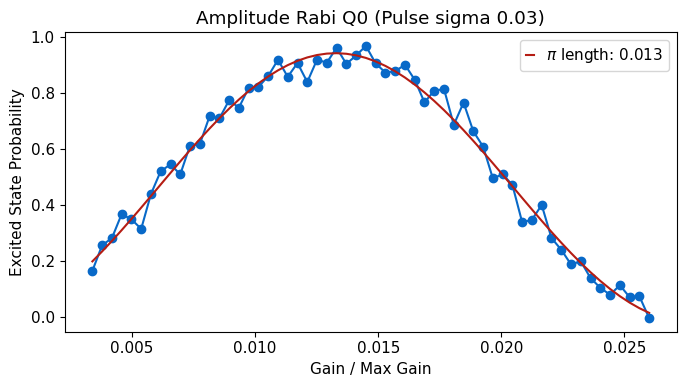

*Set cfg device.qubit 0 ('pulses', 'pi_ge', 'gain') to 0.146 from 0.1503*


  0%|          | 0/9000 [00:00<?, ?it/s]

Attempted to init fitparam 1 to 1186.355172413793, which is out of bounds 0.001 to 1000. Instead init to 500.0005
R2:0.971	Fit par error:0.104	 Best fit:b'avgi'


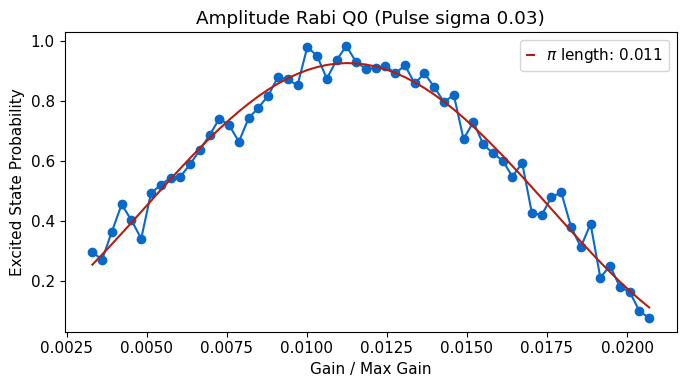

*Set cfg device.qubit 0 ('pulses', 'pi_ge', 'gain') to 0.1465 from 0.146*


In [22]:
qubit_list = np.arange(3)
qubit_list=[0]

update=True
n_pulse_list = [1,3,5,7,9,11,13]
for n_pulses in n_pulse_list:
    for qi in qubit_list: 
        amp_rabi = meas.RabiExperiment(cfg_dict,qi=qi, params={'n_pulses':n_pulses, 'num_osc':1}, disp_kwargs={'rescale':True})
        
        # Fully customized version
        #amp_rabi = meas.RabiExperiment(cfg_dict,qi=qi, params={'expts':500,'max_gain':0.1})
        #amp_rabi = meas.RabiExperiment(cfg_dict,qi=qi, params={'pulse_type':'flat_top'})

        if update and amp_rabi.status:
            config.update_qubit(cfg_path, ('pulses','pi_ge','gain'), amp_rabi.data['pi_length']*n_pulses, qi)
            

#### Chevron

In [73]:
d2=[]
qubit_list = np.arange(9)
qubit_list=[2]
for qi in qubit_list: 
    #amp_rabi_chevron = meas.RabiChevronExperiment(cfg_dict,qi=qi, params={'span_f':200,'sigma':0.25,'expts_f':100,'expts':100})

    amp_rabi_chevron = meas.RabiChevronExperiment(cfg_dict,qi=qi, params={'span_f':10, 'expts_f':10})
    d2.append(amp_rabi_chevron)

#handy.plot_many(d2, title='Rabi Chevron Phase', save_path=cfg_dict['expt_path'], chan='phases')

Setting up a new session...


KeyboardInterrupt: 

In [ ]:
handy.plot_many(d2, title='Rabi Chevron 7864', save_path=cfg_dict['expt_path'])

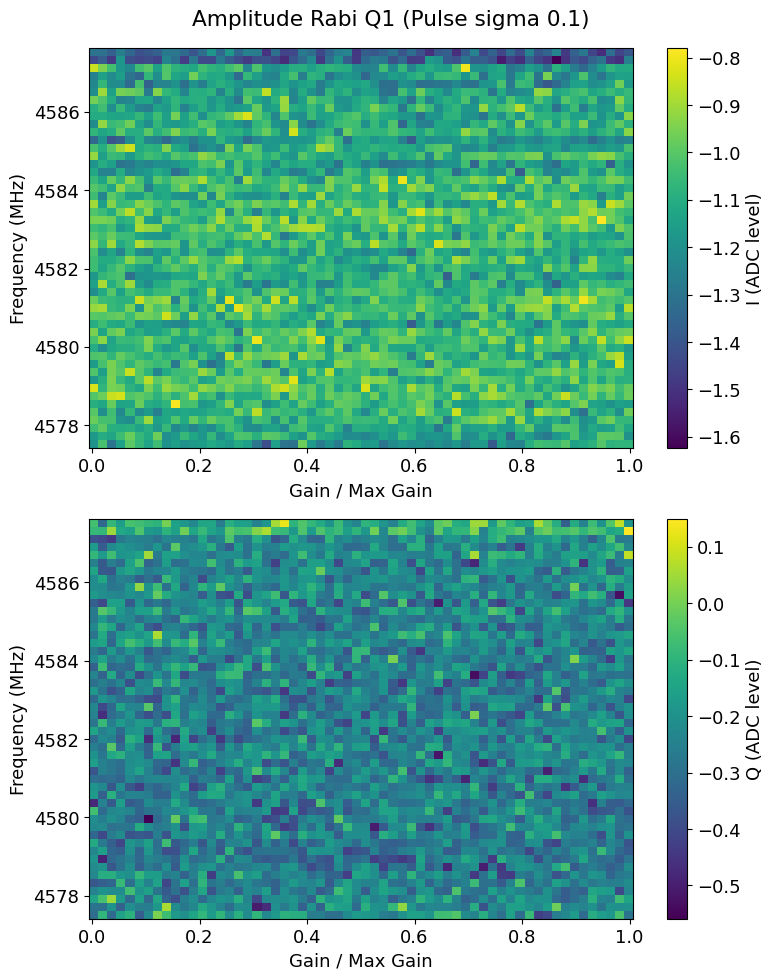

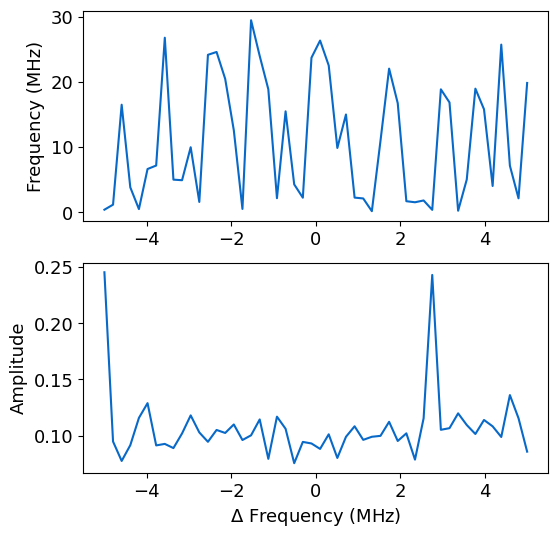

In [244]:
amp_rabi_chevron.display(plot_both=True)

#### 2 Qubit Rabi

In [ ]:
qi=[0,10]
amp_rabi = meas.Rabi_2Q(cfg_dict,qi=qi, params={'active_reset':False})

### Length -- Uses const pulses so do not use to set up pi pulses

Unexpected parameters found in params: {'pulse_type'}


  0%|          | 0/30000 [00:00<?, ?it/s]

R2:0.979	Fit par error:0.058	 Best fit:b'amps'


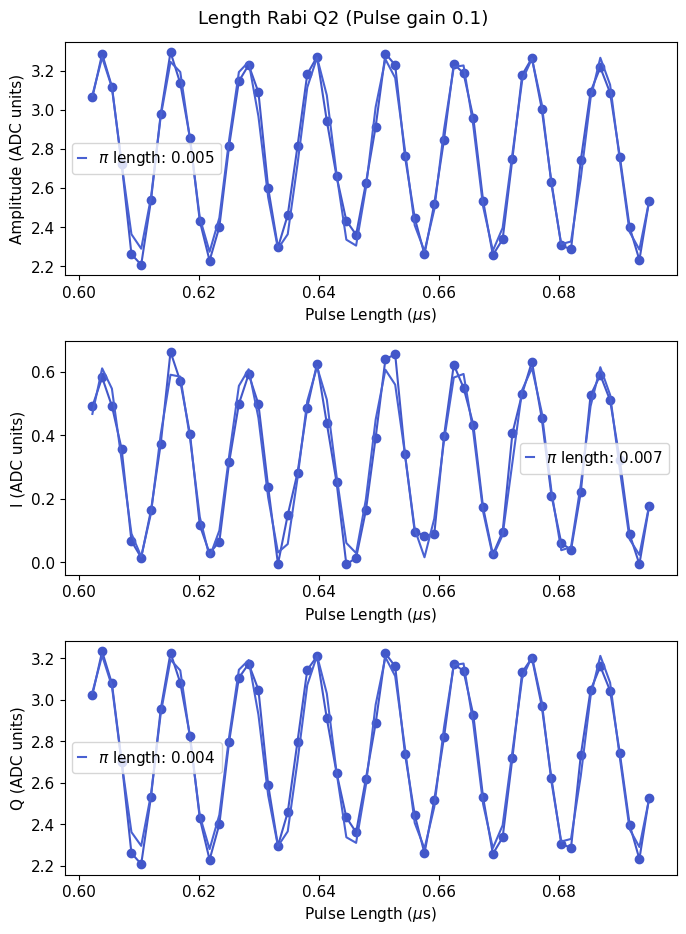

In [72]:
qubit_list = [2]
# This does not work with gaussian pulses due to multiplying qickparams issues -- need to fix
for qi in qubit_list: 
    # Needs to have params of sweep: length and type: con    len_rabi = meas.RabiExperiment(cfg_dict,qi=qi, params={'sweep':'length', 'pulse_type':'gaussian','max_length':5,'gain':0.1})})
    #len_rabi = meas.RabiExperiment(cfg_dict,qi=qi, params={'sweep':'length', 'pulse_type':'flat_top','start':0.50,'max_length':0.6,'gain':0.1, 'n_pulses':7,'reps':500})

#### Chevron

Unexpected parameters found in params: {'expts_f', 'span_f'}


  0%|          | 0/20 [00:00<?, ?it/s]

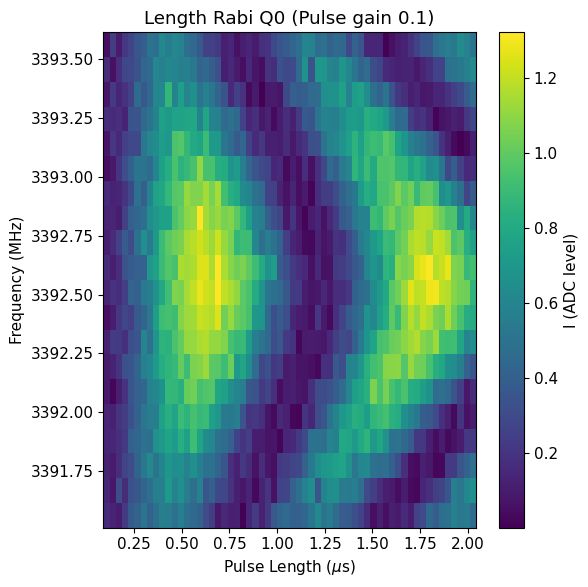

Unexpected parameters found in params: {'expts_f', 'span_f'}


  0%|          | 0/20 [00:00<?, ?it/s]

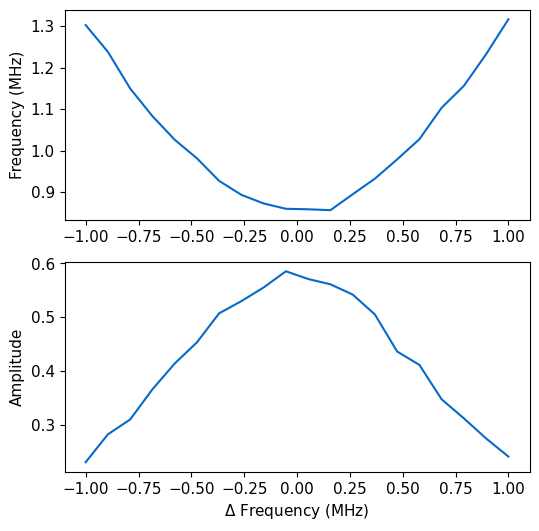

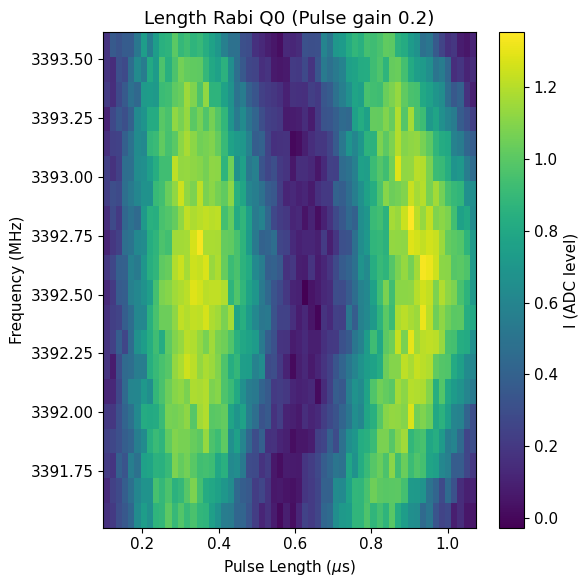

Unexpected parameters found in params: {'expts_f', 'span_f'}


  0%|          | 0/20 [00:00<?, ?it/s]

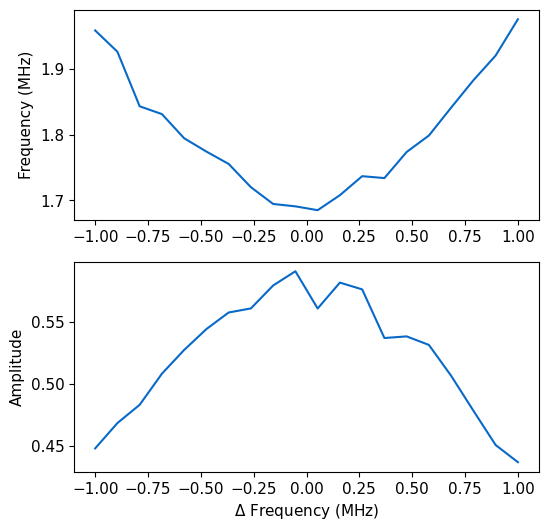

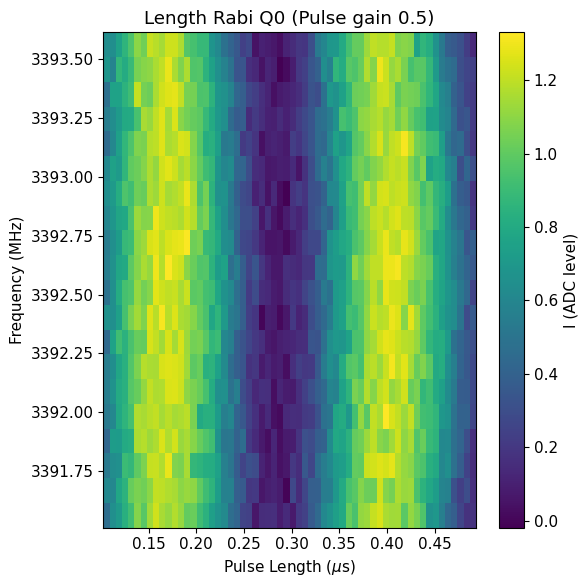

Unexpected parameters found in params: {'expts_f', 'span_f'}


  0%|          | 0/20 [00:00<?, ?it/s]

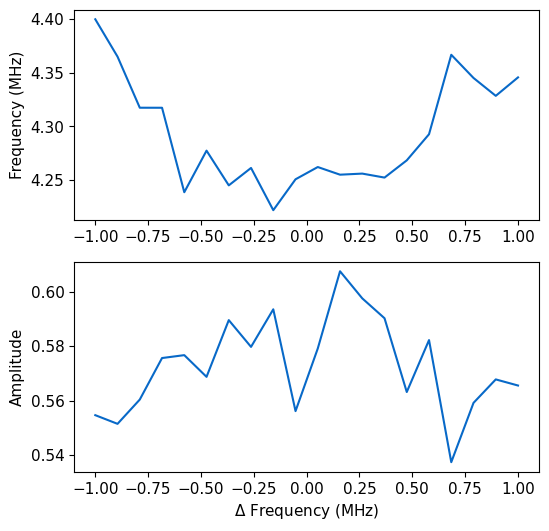

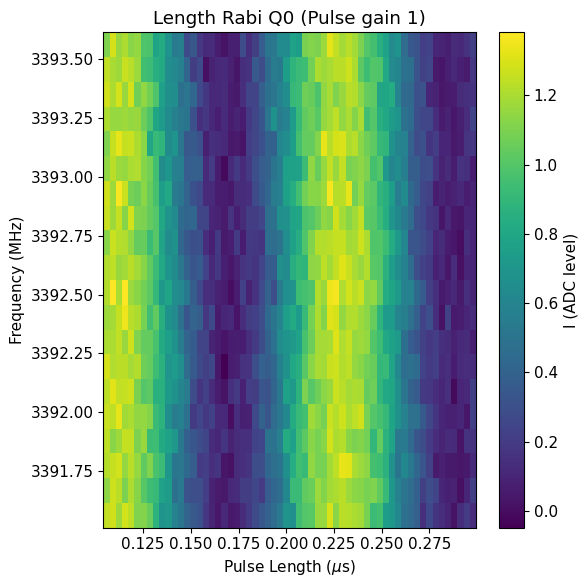

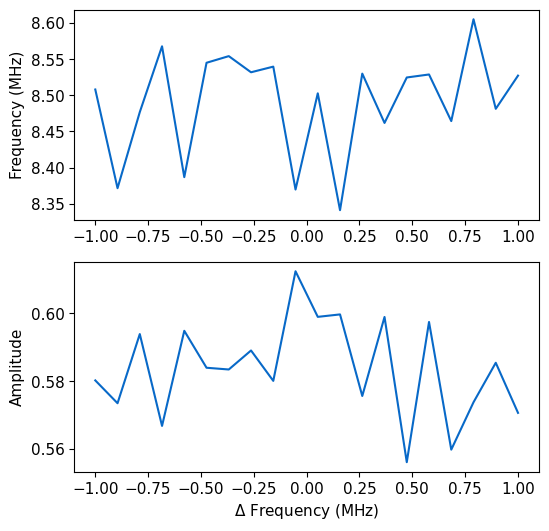

In [229]:
qubit_list = np.arange(3)
qubit_list=[0]
g_list = [0.1, 0.2, 0.5, 1]
for g in g_list:
    for qi in qubit_list: 
        len_rabi_chevron = meas.RabiChevronExperiment(cfg_dict,qi=qi, params={'sweep':'length',"type":"flat_top", 'max_length':0.2/g, 'expts_f':20,'span_f':2,'gain':g})
        #len_rabi_chevron = meas.RabiChevronExperiment(cfg_dict,qi=qi, params={'sweep':'length',"type":"const", 'sigma':0.605, 'span_f':20})
        #len_rabi_chevron = meas.RabiChevronExperiment(cfg_dict,qi=qi, params={'sweep':'length',"type":"const", 'sigma':0.205, 'expts_f':60, 'span_f':150, 'gain':0.4,'start_f':6280,'soft_avgs':4})



## Ramsey

  0%|          | 0/30000 [00:00<?, ?it/s]

R2:0.951	Fit par error:0.026	 Best fit:b'avgi'


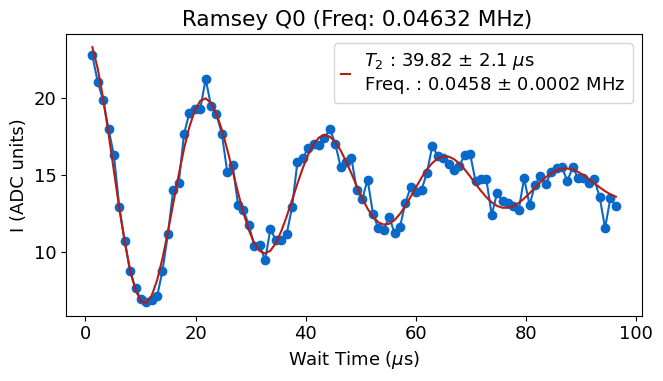

*Set cfg device.qubit 0 f_ge to 3116.6373 from 3116.6368*
*Set cfg device.qubit 0 T2r to 39.82 from 32.38*


In [34]:
qubit_list=[0]
update = True
for qi in qubit_list:
    t2r = meas.T2Experiment(cfg_dict, qi=qi, max_err=10)

    # Manually configured
    #t2r = meas.T2Experiment(cfg_dict, qi=qi, max_err=10, params = {'ramsey_freq':1,'expts':100, 'span':10,'start':0.01})
    if t2r.status and update:
        config.update_qubit(cfg_path, 'f_ge', t2r.data['new_freq'], qi)
        auto_cfg = config.update_qubit(cfg_path, 'T2r', t2r.data['best_fit'][3], qi, rng_vals=[1.5, max_t1], sig=2)
    else:
        print('T2 Ramsey fit failed')

In [45]:
t2r = meas.T2Experiment(cfg_dict, qi=qi, max_err=10,go=False)

### Use Ramsey to recenter

In [ ]:
qubit_list = [2]
for qi in qubit_list:
    status = qubit_tuning.recenter(qi,cfg_dict)            

### Ramsey coherence

In [ ]:
t1= qubit_tuning.get_coherence(meas.RamseyExperiment, qi, cfg_dict,par='T2r')

## T1

If it's the first time, also set T2r and T2e as guesses 


  0%|          | 0/18000 [00:00<?, ?it/s]

R2:0.987	Fit par error:0.032	 Best fit:b'avgi'


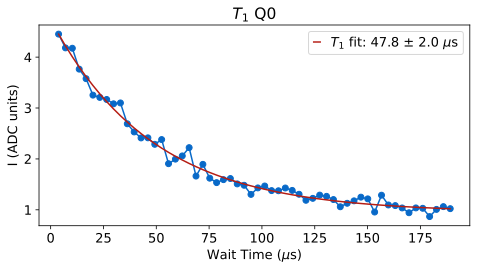

*Set cfg device.qubit 0 T1 to 47.83 from 51.86*
*Set cfg device.readout 0 final_delay to 287.0 from 311.16*


  0%|          | 0/18000 [00:00<?, ?it/s]

R2:0.986	Fit par error:0.031	 Best fit:b'avgi'


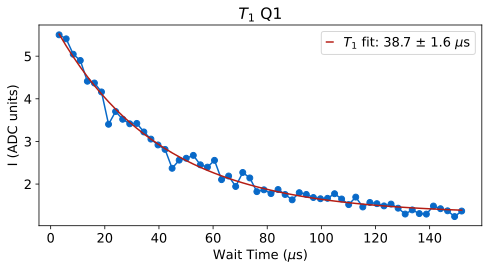

*Set cfg device.qubit 1 T1 to 38.69 from 41.61*
*Set cfg device.readout 1 final_delay to 232.15 from 249.63*


  0%|          | 0/18000 [00:00<?, ?it/s]

 C:\_Lib\python\slab_qick_calib\fitting.py: 337

R2:0.991	Fit par error:0.029	 Best fit:b'avgi'


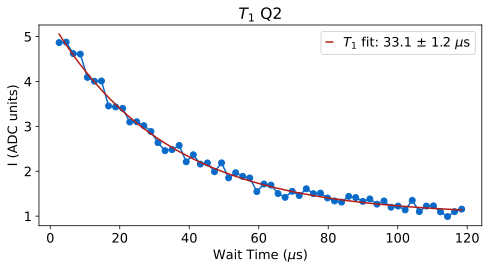

*Set cfg device.qubit 2 T1 to 33.1 from 32.44*
*Set cfg device.readout 2 final_delay to 198.58 from 194.66*


In [78]:
update=True
first_time=False

qubit_list = np.arange(3)
#qubit_list=[2]
for qi in qubit_list:
    t1 = meas.T1Experiment(cfg_dict, qi=qi)
    #t1 = meas.T1Experiment(cfg_dict, qi=qi, params={'reps':100000,'span':0, 'start':20})

    if update: t1.update(cfg_path, first_time=first_time)

### T1 coherence

Runs scan until scan is properly configured to be sensitive to T1

  0%|          | 0/12000 [00:00<?, ?it/s]

R2:0.979	Fit par error:0.041	 Best fit:b'avgi'


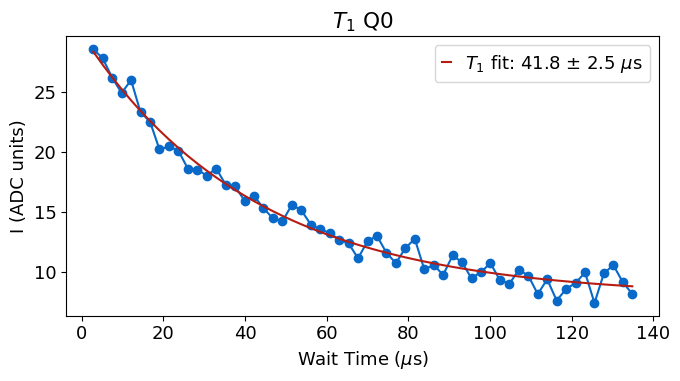

*Set cfg device.qubit 0 T1 to 41.78 from 36.95*


In [8]:
qi=0
qubit_tuning.get_coherence(meas.T1Experiment,qi=qi,cfg_dict=cfg_dict,par='T1')

### Continuous scan at single point
Times do not seem to be accurate right now 

  0%|          | 0/200000 [00:00<?, ?it/s]

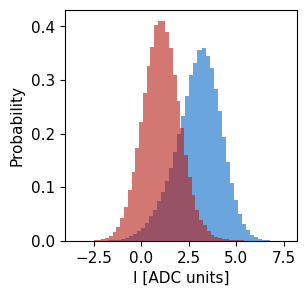

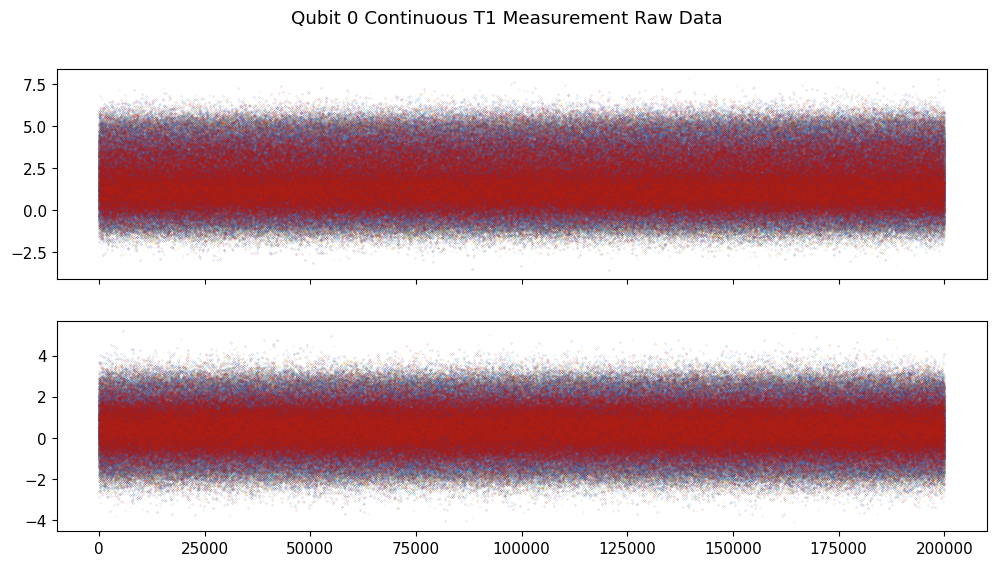

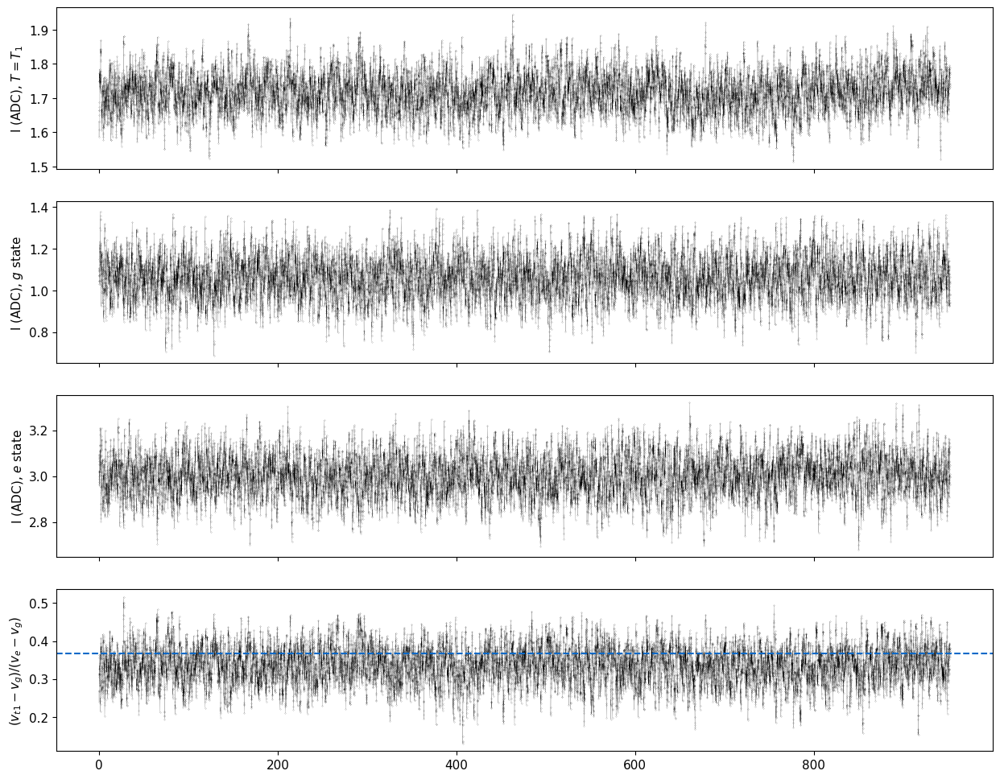

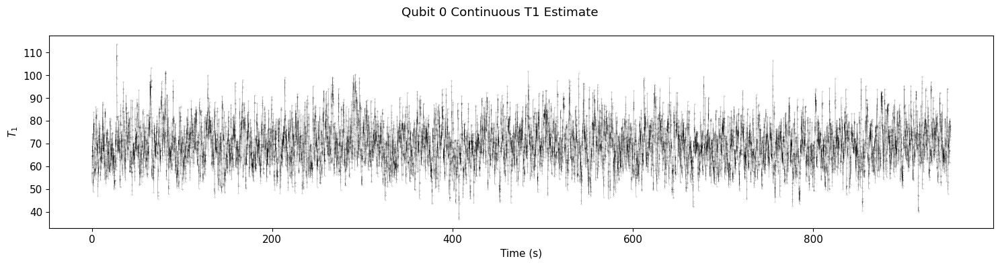

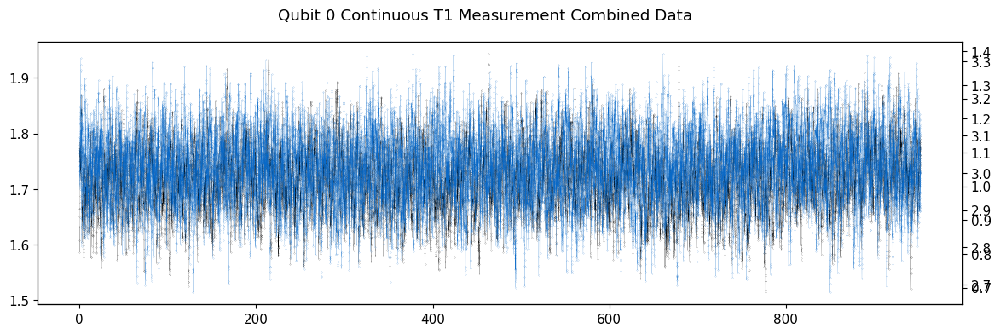

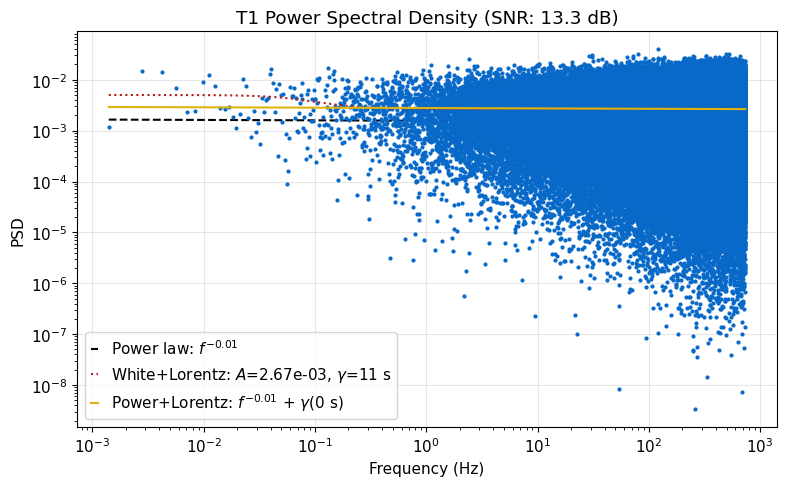

In [16]:
qi=0
t1cont = meas.T1ContExperiment(cfg_dict,qi=qi, params={'shots':200000})

### T1 continuous 2Q

In [ ]:
qi = [10,0]
meas.T1_2Q(cfg_dict,qi=qi, )

In [ ]:
qi=[0,10]
scan_time = 0.1 #hours
number_of_scans = 1
shots = int(100000*scan_time*60/4)
print(shots)
for i in range(number_of_scans):
    meas.T1Cont2QExperiment(cfg_dict,qi=qi, params={'shots':shots, 'active_reset':False})

## Echo

  0%|          | 0/30000 [00:00<?, ?it/s]

R2:0.983	Fit par error:0.019	 Best fit:b'avgi'


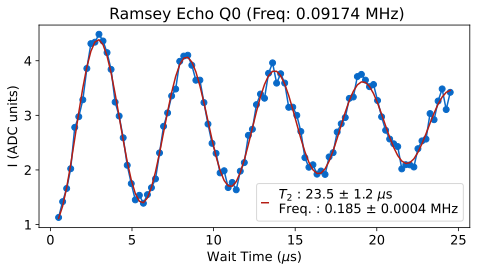

*Set cfg device.qubit 0 T2e to 23.5 from 16.35*


  0%|          | 0/30000 [00:00<?, ?it/s]

R2:0.914	Fit par error:0.033	 Best fit:b'avgi'


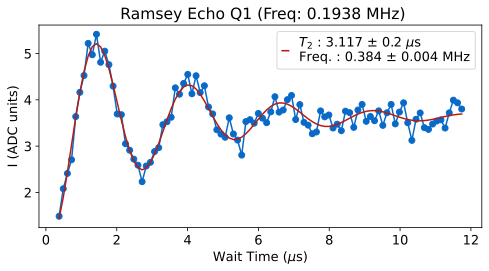

*Set cfg device.qubit 1 T2e to 3.12 from 7.74*


  0%|          | 0/30000 [00:00<?, ?it/s]

R2:0.984	Fit par error:0.019	 Best fit:b'avgi'


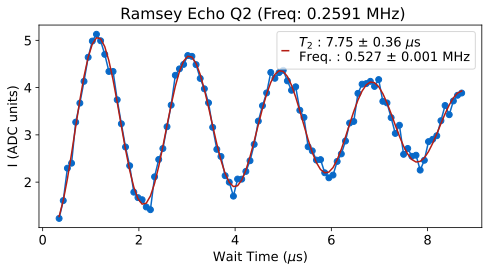

*Set cfg device.qubit 2 T2e to 7.75 from 5.79*


In [76]:
qubit_list = np.arange(20)
qubit_list=[0,1,2]
update=True
for qi in qubit_list:
    # Need to have experiment type set to echo
    t2e = meas.T2Experiment(cfg_dict, qi=qi, params={'experiment_type':'echo'})
    if t2e.status and update:
        auto_cfg = config.update_qubit(cfg_path, 'T2e', t2e.data['best_fit'][3], qi,sig=2, rng_vals=[1.5, max_t1*2])

### More pi
Breaks above 12 right now

  0%|          | 0/20000 [00:00<?, ?it/s]

R2:0.170	Fit par error:0.439	 Best fit:b'avgi'


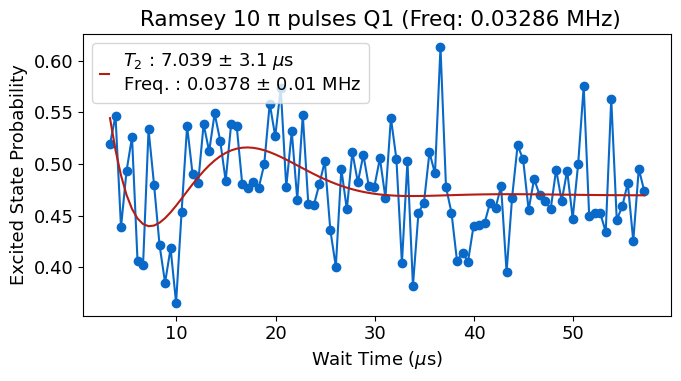

In [40]:
qubit_list = np.arange(20)
qubit_list=[1]
update=True
nums_pi = [10]
for qi in qubit_list:
    for pi in nums_pi:
        # Need to have experiment type set to echo
        t2e = meas.T2Experiment(cfg_dict, qi=qi, params={'experiment_type':'cpmg','num_pi':pi,'span':100})


### Get echo coherence

In [ ]:
qi=6
t2e = qubit_tuning.get_coherence(meas.RamseyEchoExperiment, qi, cfg_dict,'T2e')

## Feedback checks

In [ ]:
qi=10
reset = meas.MemoryExperiment(cfg_dict, qi=qi, params={'shots':1, 'expts':200})

In [ ]:
# Don't do the active reset, just do the repeated measurement 
qi=1
shot = meas.RepMeasExperiment(cfg_dict, qi=qi, params={'shots':30000,'active_reset':True, 'setup_reset':True})
shot.check_reset()

# Single Shot

  0%|          | 0/10000 [00:00<?, ?it/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

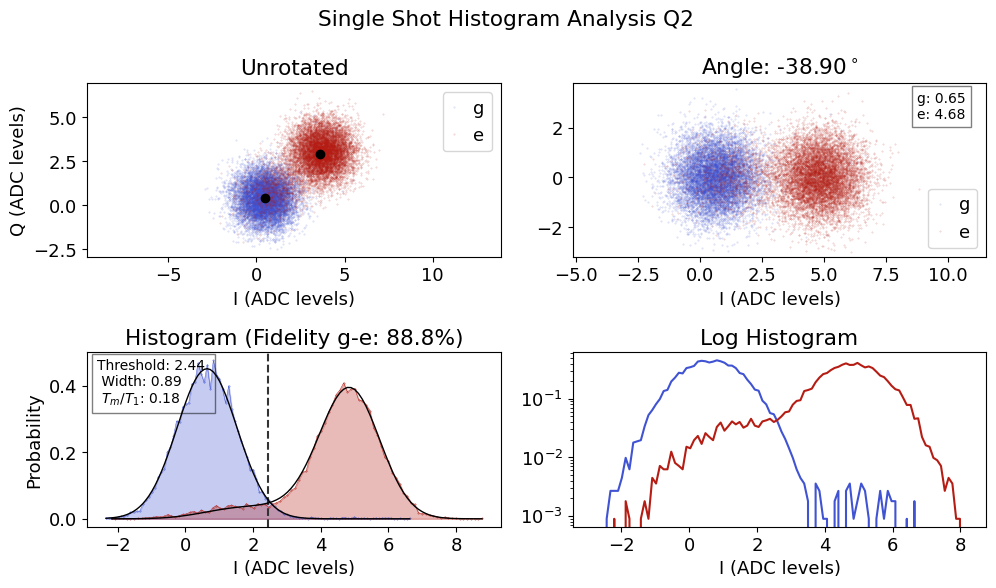

*Set cfg device.readout 2 phase to -38.8971 from 0*
*Set cfg device.readout 2 threshold to 2.4394 from 10*
*Set cfg device.readout 2 fidelity to 0.8881 from 0*
*Set cfg device.readout 2 sigma to 0.8855 from 0*
*Set cfg device.readout 2 tm to 0.1807 from 0*
*Set cfg device.qubit 2 tuned_up to True from False*


In [55]:
# Single shot 
qubit_list = np.arange(3)
qubit_list =[2]

for qi in qubit_list:
    shot=meas.HistogramExperiment(cfg_dict, qi=qi)

    # Configure number of shots
    #shot=meas.HistogramExperiment(cfg_dict, qi=qi, params={'shots':300000})
    shot.update(cfg_path)

### Adjust reps for fidelity 

In [ ]:
max_inc = 15 # dont' let it do more than 15x standard number of reps so that things don't take forever
qubit_list = [0]

auto_cfg = config.load(cfg_path)
for qi in qubit_list:
    config.update_readout(cfg_path, 'reps', 1/auto_cfg['device']['readout']['fidelity'][qi]**1.5, qi, rng_vals=[1,max_inc]);

## Readout opt

### General sweep

Runs single shot experiments for many readout lengths, frequencies, gains and compares fidelity

low_gain=True chooses lowest gain/readout length within a few percent of maximum gain (often readout fidelity fairly flat as a function of gain at higher gain values) 

style='fine' varies parameters by 20%, style='' varies by 2x

Unexpected parameters found in params: {'step_len', 'step_gain', 'step_f'}


  0%|          | 0/5 [00:00<?, ?it/s]

Max fidelity 89.329 %
Optimal params: 
 Freq (MHz) 5920.750 
 Gain (DAC units) 0.021 
 Readout length (us) 1.500
Set fidelity: 89.180 %
Set params: 
 Freq (MHz) 5920.750 
 Gain (DAC units) 0.012 
 Readout length (us) 3.750


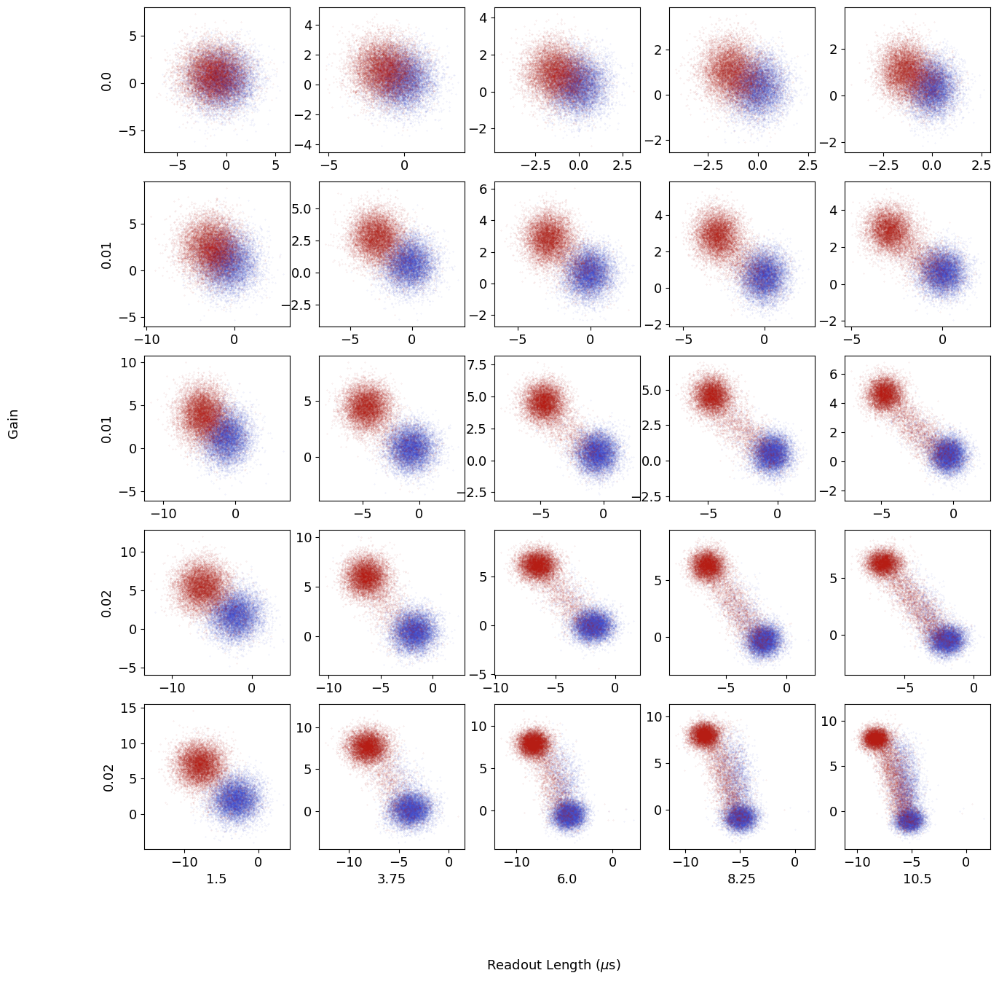

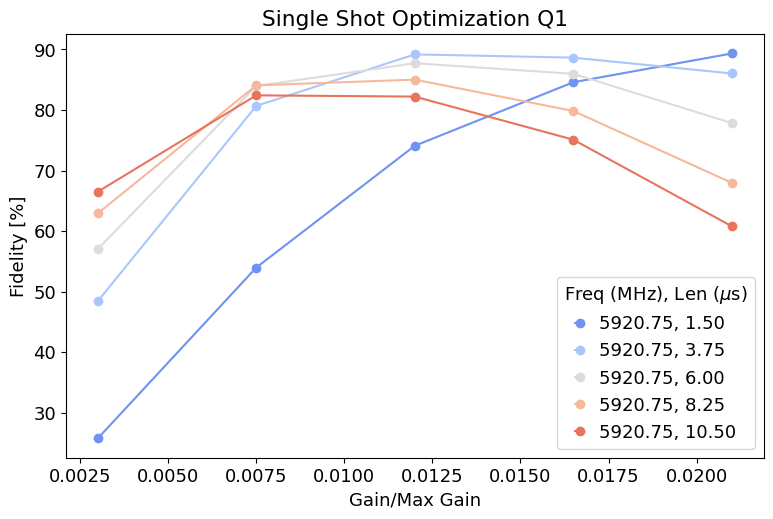

Max fidelity 89.329 %
Optimal params: 
 Freq (MHz) 5920.750 
 Gain (DAC units) 0.021 
 Readout length (us) 1.500
Set fidelity: 89.180 %
Set params: 
 Freq (MHz) 5920.750 
 Gain (DAC units) 0.012 
 Readout length (us) 3.750
*Set cfg device.readout 1 gain to 0.012 from 0.01*
*Set cfg device.readout 1 readout_length to 3.75 from 5*
*Set cfg device.readout 1 frequency to 5920.75 from 5920.75*


  0%|          | 0/10000 [00:00<?, ?it/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

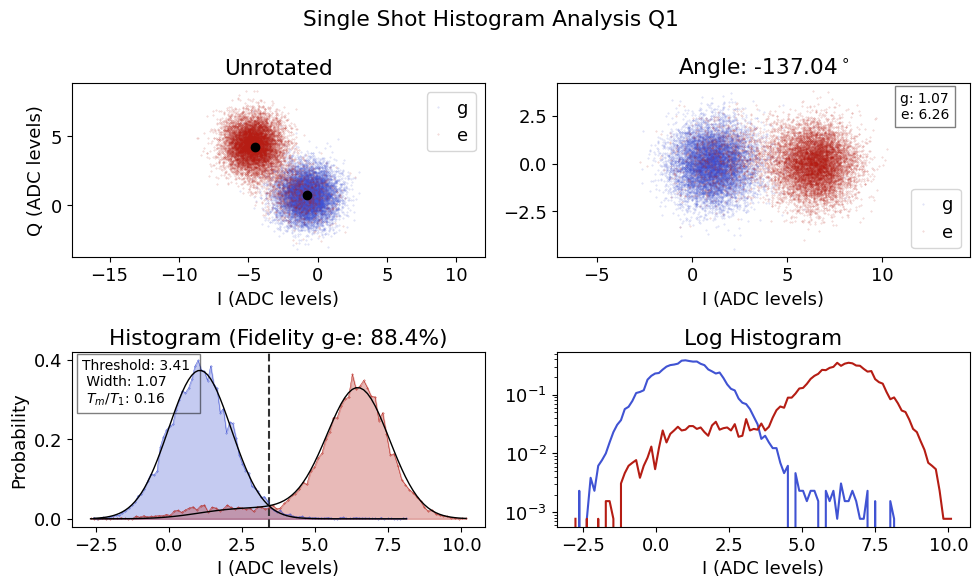

*Set cfg device.readout 1 phase to -137.039 from -140.3201*
*Set cfg device.readout 1 threshold to 3.407 from 2.7611*
*Set cfg device.readout 1 fidelity to 0.8836 from 0.8758*
*Set cfg device.readout 1 sigma to 1.0697 from 0.9212*
*Set cfg device.readout 1 tm to 0.164 from 0.1996*
*Set cfg device.qubit 1 tuned_up to True from True*
Unexpected parameters found in params: {'step_len', 'step_gain', 'step_f'}


  0%|          | 0/5 [00:00<?, ?it/s]

Max fidelity 92.020 %
Optimal params: 
 Freq (MHz) 6629.092 
 Gain (DAC units) 0.033 
 Readout length (us) 3.750
Set fidelity: 90.659 %
Set params: 
 Freq (MHz) 6629.092 
 Gain (DAC units) 0.024 
 Readout length (us) 3.750


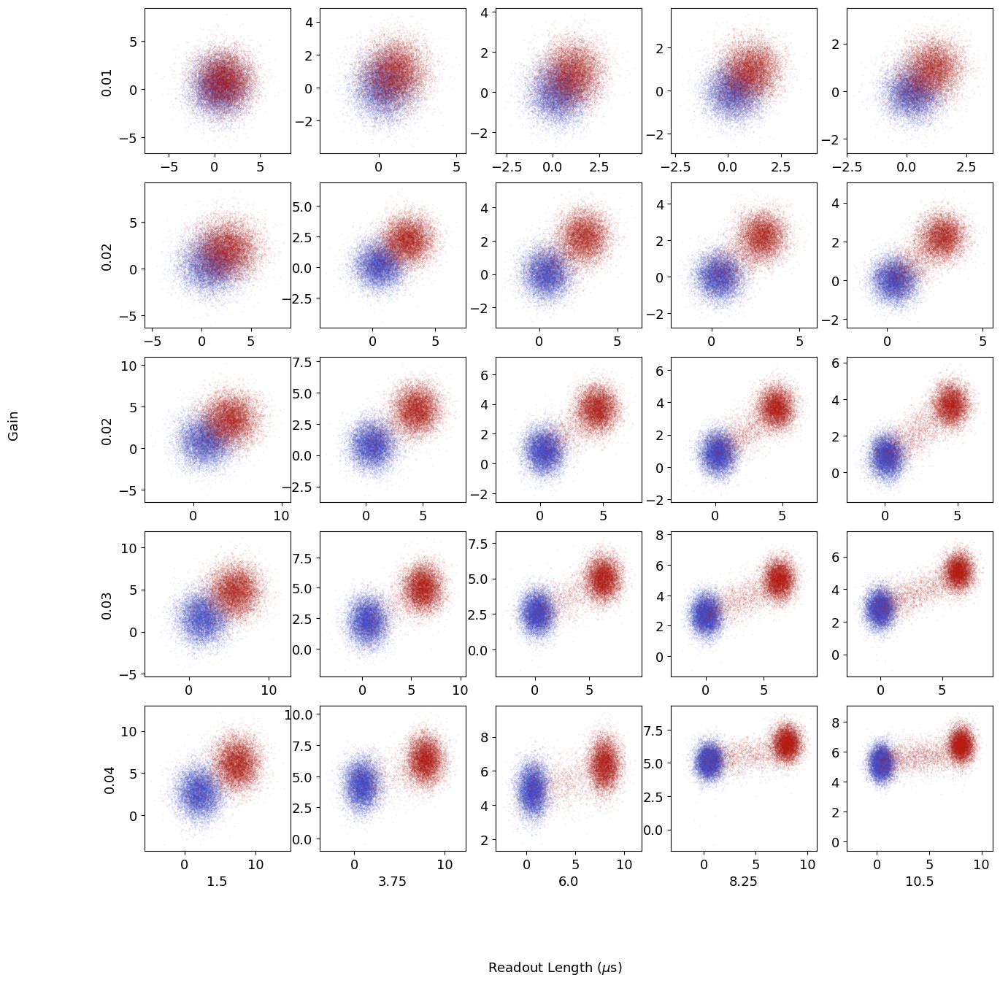

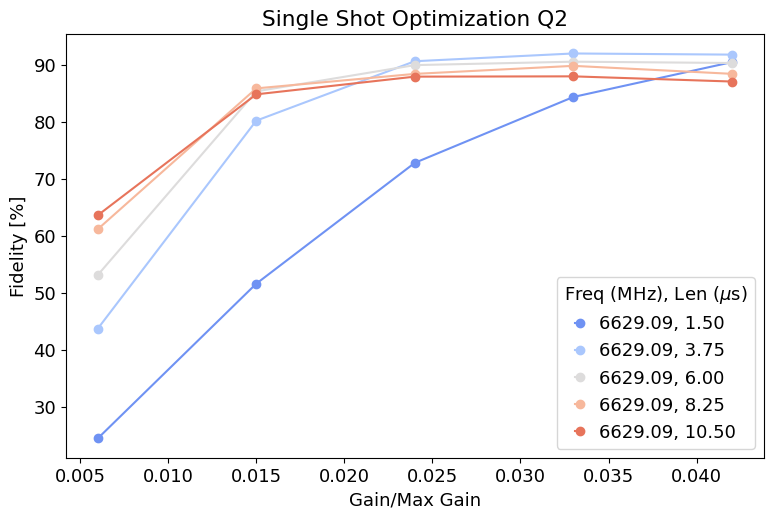

Max fidelity 92.020 %
Optimal params: 
 Freq (MHz) 6629.092 
 Gain (DAC units) 0.033 
 Readout length (us) 3.750
Set fidelity: 90.659 %
Set params: 
 Freq (MHz) 6629.092 
 Gain (DAC units) 0.024 
 Readout length (us) 3.750
*Set cfg device.readout 2 gain to 0.024 from 0.02*
*Set cfg device.readout 2 readout_length to 3.75 from 5*
*Set cfg device.readout 2 frequency to 6629.0915 from 6629.0915*


  0%|          | 0/10000 [00:00<?, ?it/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

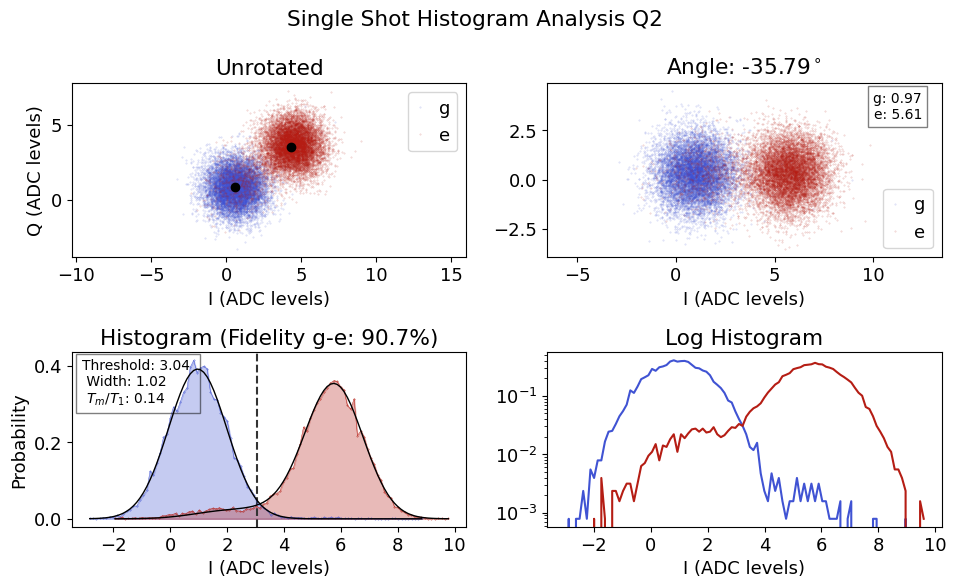

*Set cfg device.readout 2 phase to -35.7895 from -38.8971*
*Set cfg device.readout 2 threshold to 3.0357 from 2.4394*
*Set cfg device.readout 2 fidelity to 0.9066 from 0.8881*
*Set cfg device.readout 2 sigma to 1.0208 from 0.8855*
*Set cfg device.readout 2 tm to 0.1379 from 0.1807*
*Set cfg device.qubit 2 tuned_up to True from True*


In [56]:
update=True
low_gain=True


qubit_list=np.arange(14,20)
qubit_list=[1,2]

params = {'expts_f':1, 'expts_gain':5, 'expts_len':5}
#params = {'expts_f':10, 'expts_gain':1, 'expts_len':1}

# Specify exact ranges to use  
#params = {'expts_f':1, 'expts_gain':9, 'expts_len':9,'start_gain':0.45, 'span_gain':0.05,'start_len':2, 'span_len':5}

for qi in qubit_list: 
    shotopt=meas.SingleShotOptExperiment(cfg_dict, qi=qi,params=params)#, style='fine')
    shotopt.analyze(low_gain=low_gain)
    if update: 
        shotopt.update(cfg_dict['cfg_file'])
        shot=meas.HistogramExperiment(cfg_dict, qi=qi)
        shot.update(cfg_path)

### Run optimization until it converges

Unexpected parameters found in params: {'step_f', 'step_len', 'step_gain'}


  0%|          | 0/5 [00:00<?, ?it/s]

c:\Users\slab\anaconda3\envs\slab\lib\site-packages\scipy\optimize\_minpack_py.py:881: OptimizeWarning: Covariance of the parameters could not be estimated
  warnings.warn('Covariance of the parameters could not be estimated',


Max fidelity 61.998 %
Optimal params: 
 Freq (MHz) 5375.806 
 Gain (DAC units) 0.025 
 Readout length (us) 35.192
Set fidelity: 61.998 %
Set params: 
 Freq (MHz) 5375.806 
 Gain (DAC units) 0.025 
 Readout length (us) 35.192


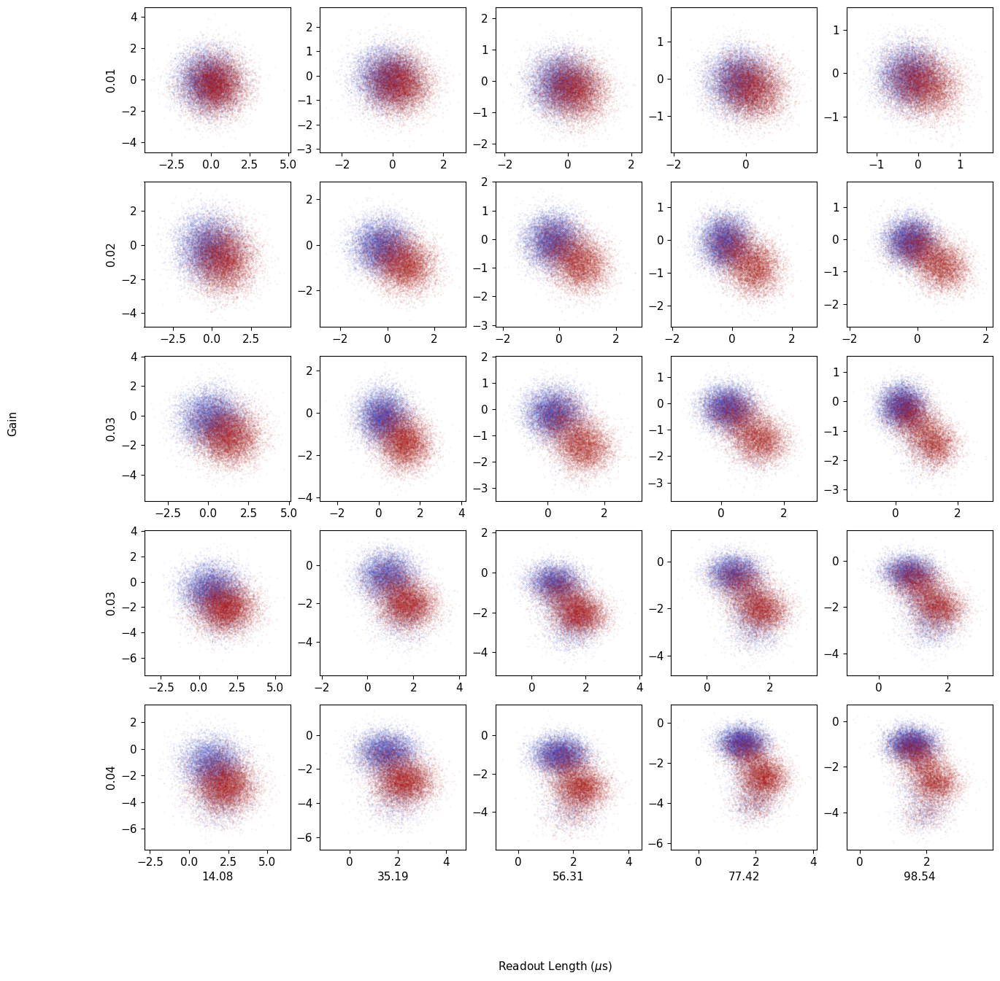

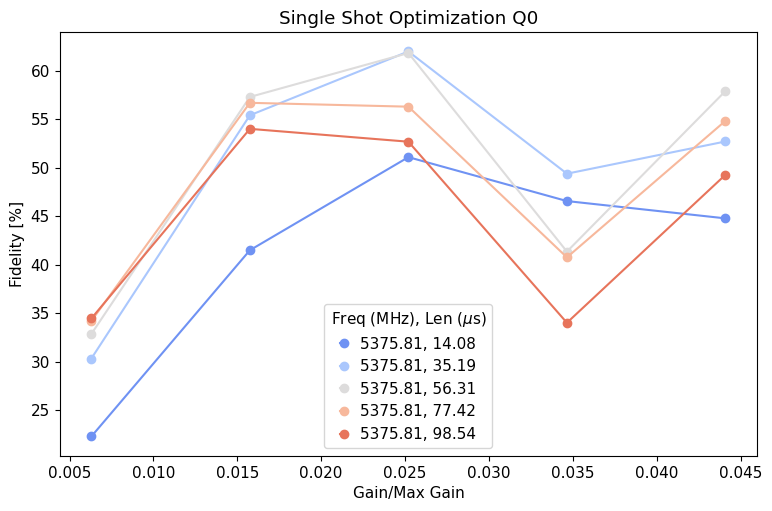

*Set cfg device.readout 0 gain to 0.0252 from 0.021*
*Set cfg device.readout 0 readout_length to 35.1918 from 46.9224*


  0%|          | 0/44000 [00:00<?, ?it/s]

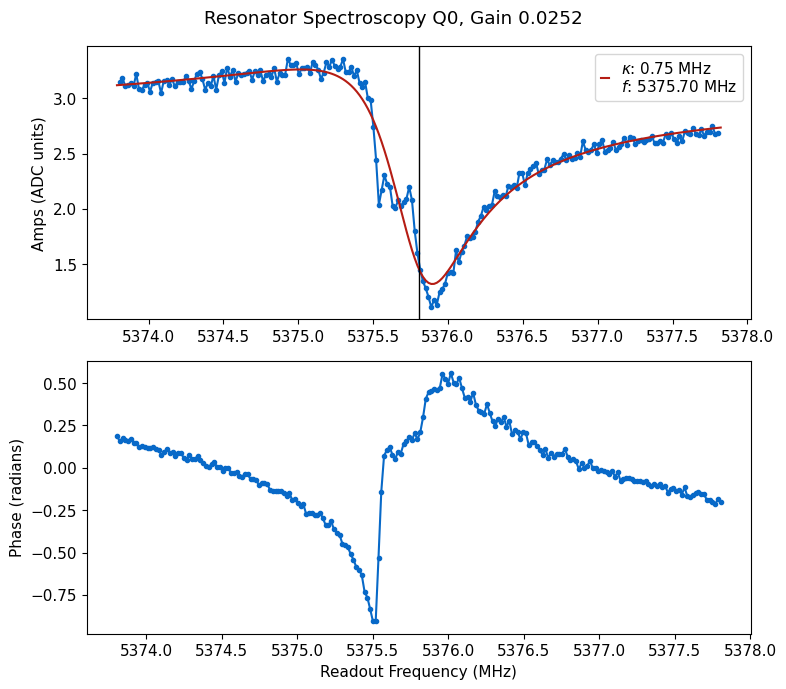

*Set cfg device.readout 0 frequency to 5375.8883 from 5375.8056*
*Set cfg device.readout 0 kappa to 0.7468 from 0.5762*
*Set cfg device.readout 0 qi to 2.1324 from 330570883.1552*
*Set cfg device.readout 0 qe to 1.0867 from 0.9329*
Unexpected parameters found in params: {'step_f', 'step_len', 'step_gain'}


  0%|          | 0/5 [00:00<?, ?it/s]

Max fidelity 59.947 %
Optimal params: 
 Freq (MHz) 5375.888 
 Gain (DAC units) 0.028 
 Readout length (us) 42.230
Set fidelity: 56.958 %
Set params: 
 Freq (MHz) 5375.888 
 Gain (DAC units) 0.028 
 Readout length (us) 28.153


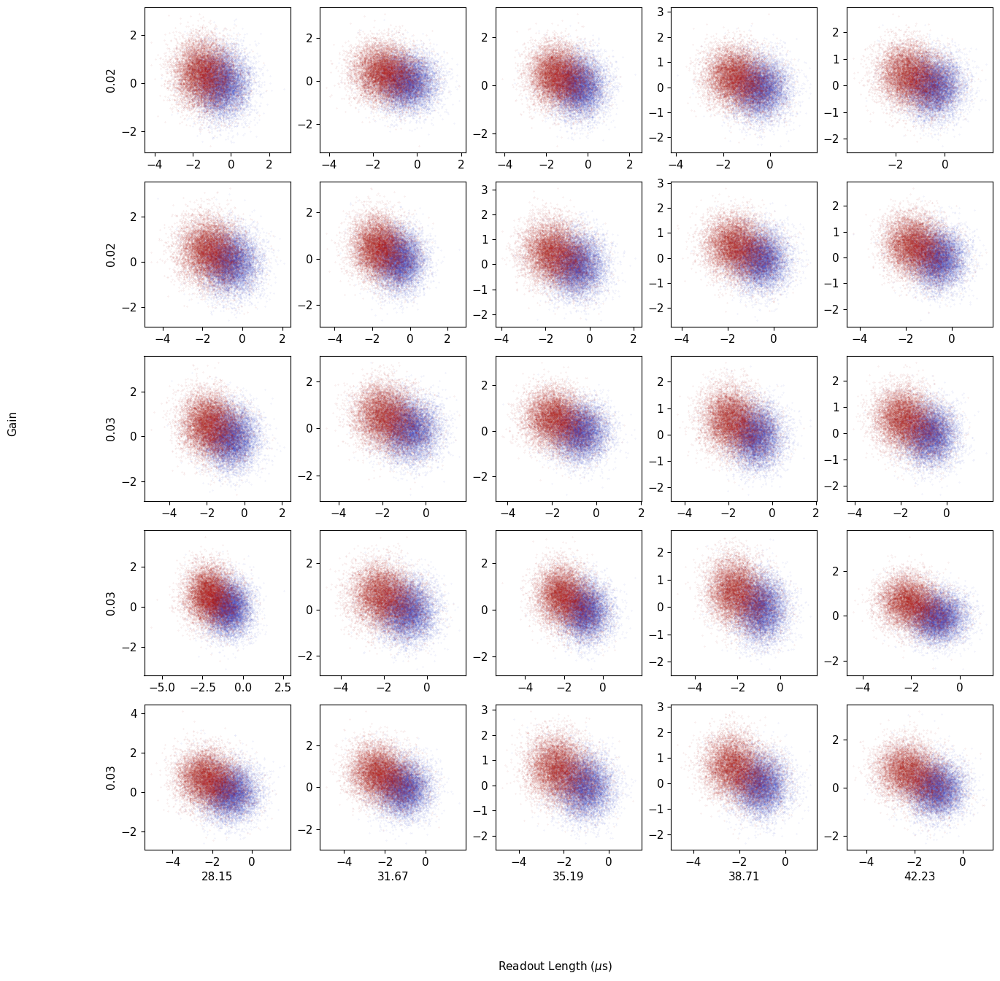

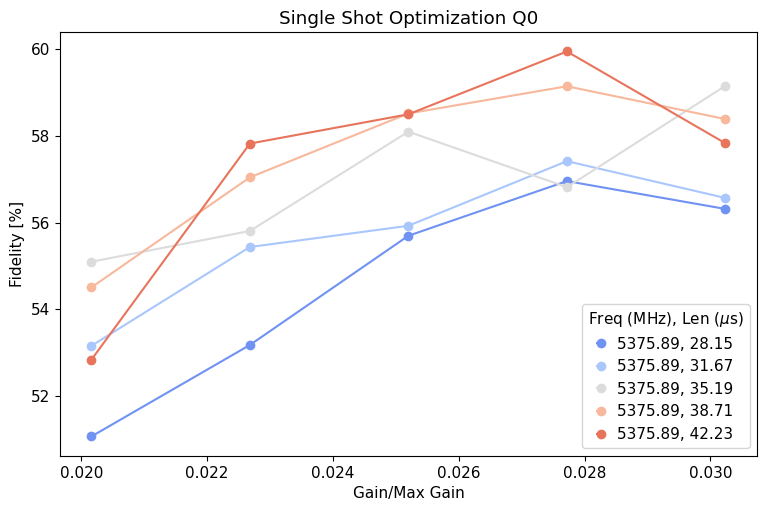

*Set cfg device.readout 0 gain to 0.0277 from 0.0252*
*Set cfg device.readout 0 readout_length to 28.1534 from 35.1918*


  0%|          | 0/10000 [00:00<?, ?it/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

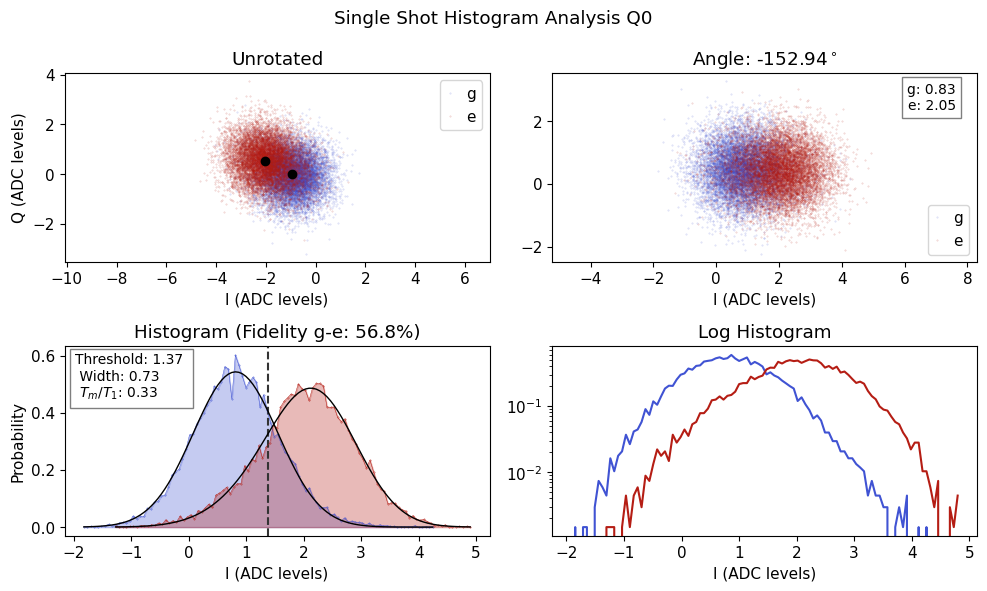

*Set cfg device.readout 0 phase to -152.9386 from 42.9442*
*Set cfg device.readout 0 threshold to 1.3739 from 0.6693*
*Set cfg device.readout 0 fidelity to 0.5682 from 0.6249*
*Set cfg device.readout 0 sigma to 0.7346 from 0.5568*
*Set cfg device.readout 0 tm to 0.3251 from 0.6314*
*Set cfg device.qubit 0 tuned_up to True from True*
Unexpected parameters found in params: {'step_f', 'step_len', 'step_gain'}


  0%|          | 0/5 [00:00<?, ?it/s]

Max fidelity 70.538 %
Optimal params: 
 Freq (MHz) 5915.713 
 Gain (DAC units) 0.035 
 Readout length (us) 15.876
Fidelity is not maximized at the center of the sweep.
Max fidelity found at indices: (0, 3, 1)
Set fidelity: 70.538 %
Set params: 
 Freq (MHz) 5915.713 
 Gain (DAC units) 0.035 
 Readout length (us) 15.876


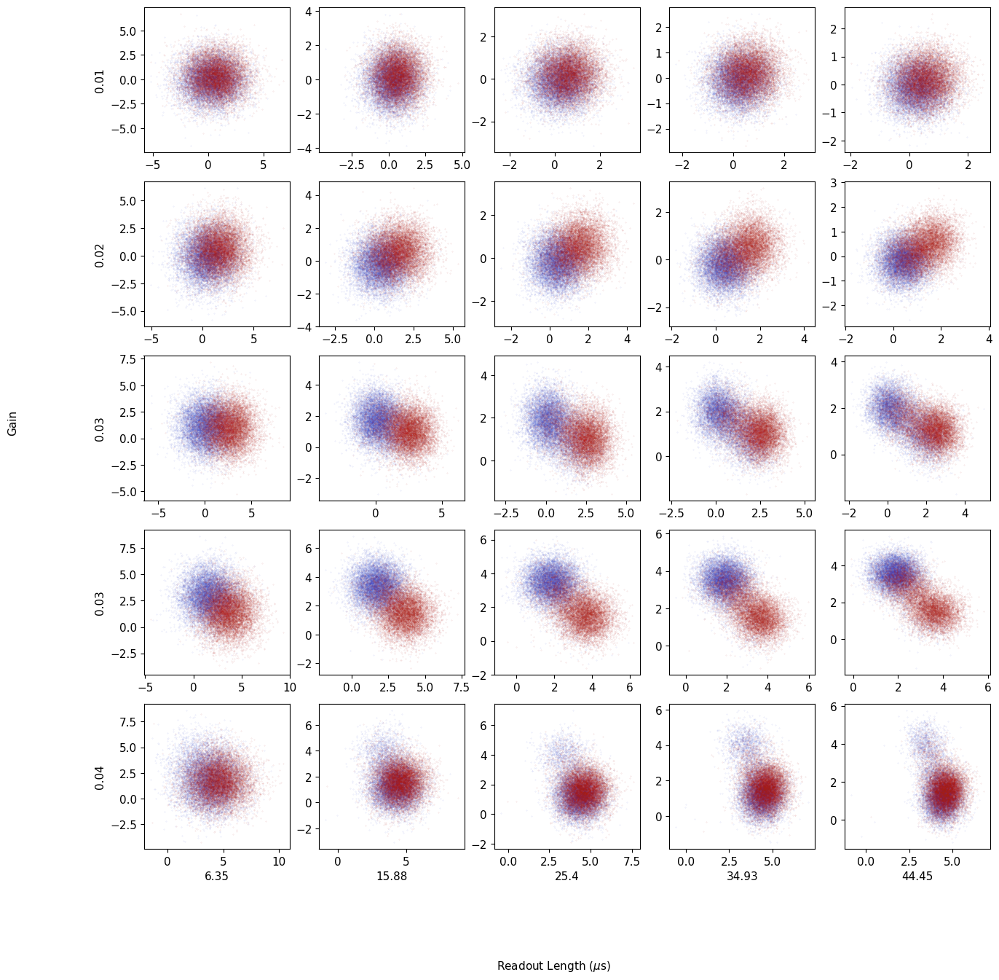

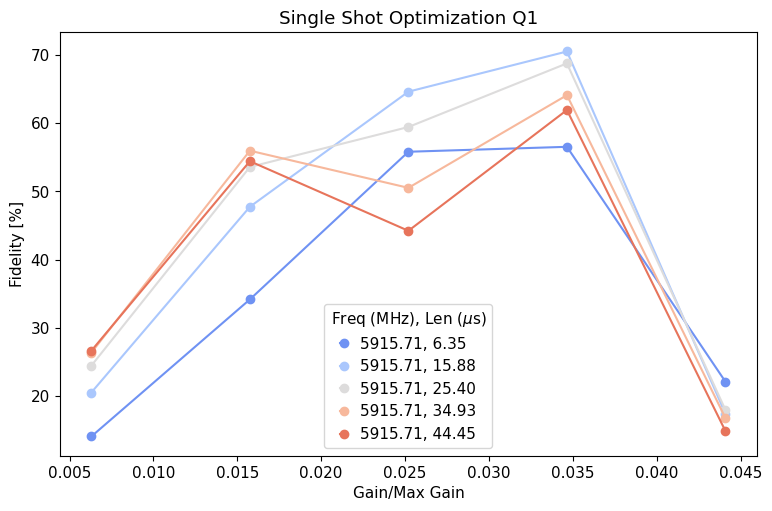

*Set cfg device.readout 1 gain to 0.0346 from 0.021*
*Set cfg device.readout 1 readout_length to 15.876 from 21.168*


  0%|          | 0/44000 [00:00<?, ?it/s]

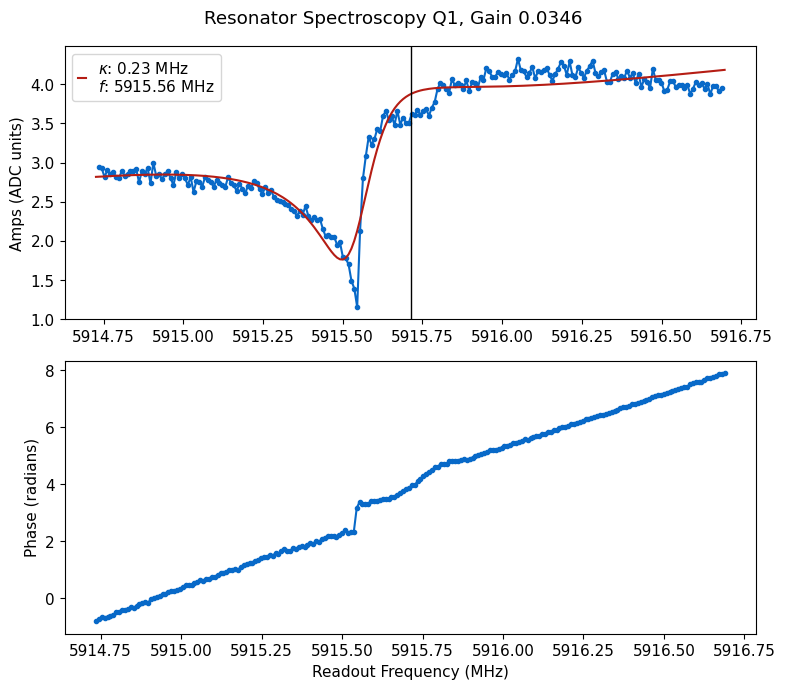

*Set cfg device.readout 1 frequency to 5915.5455 from 5915.7133*
*Set cfg device.readout 1 kappa to 0.2337 from 0.282*
*Set cfg device.readout 1 qi to 6.1452 from 30.345*
*Set cfg device.readout 1 qe to 4.3029 from 2.2534*
Unexpected parameters found in params: {'step_f', 'step_len', 'step_gain'}


  0%|          | 0/5 [00:00<?, ?it/s]

Max fidelity 77.649 %
Optimal params: 
 Freq (MHz) 5915.546 
 Gain (DAC units) 0.035 
 Readout length (us) 15.876
Set fidelity: 77.029 %
Set params: 
 Freq (MHz) 5915.546 
 Gain (DAC units) 0.035 
 Readout length (us) 12.701


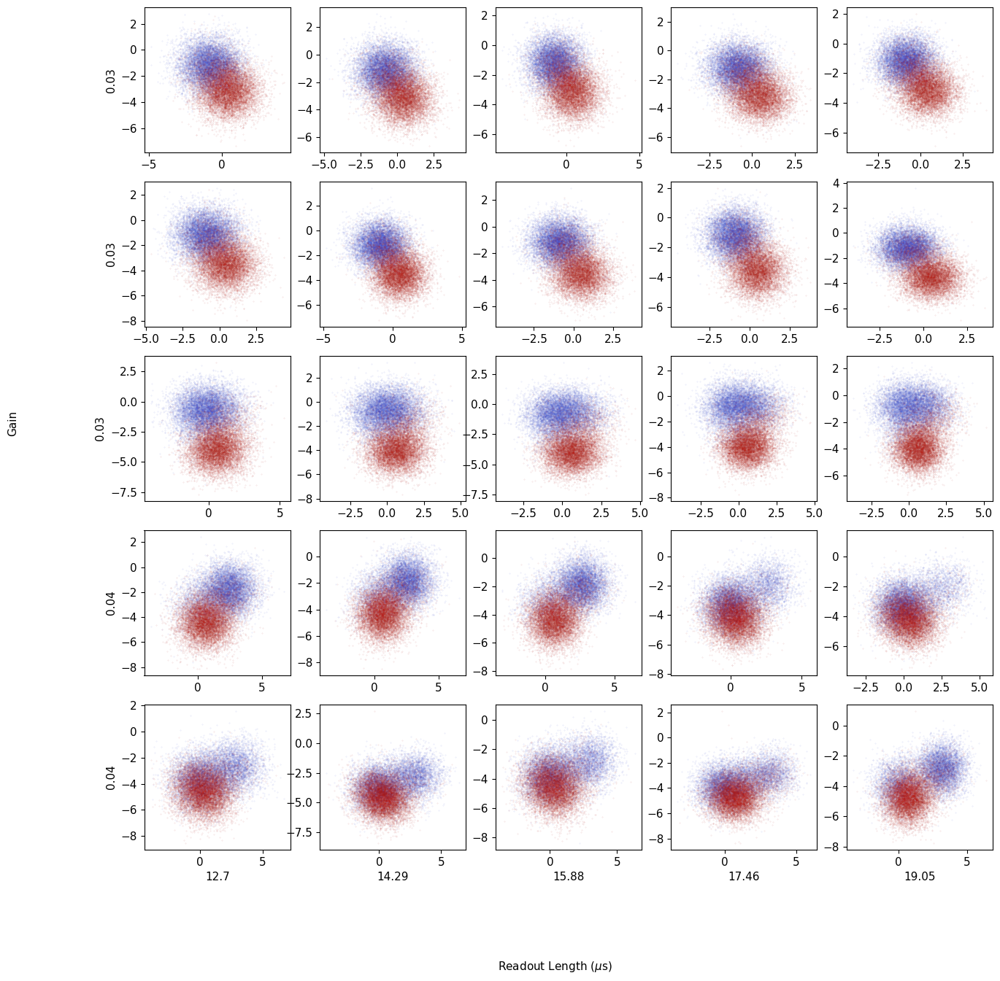

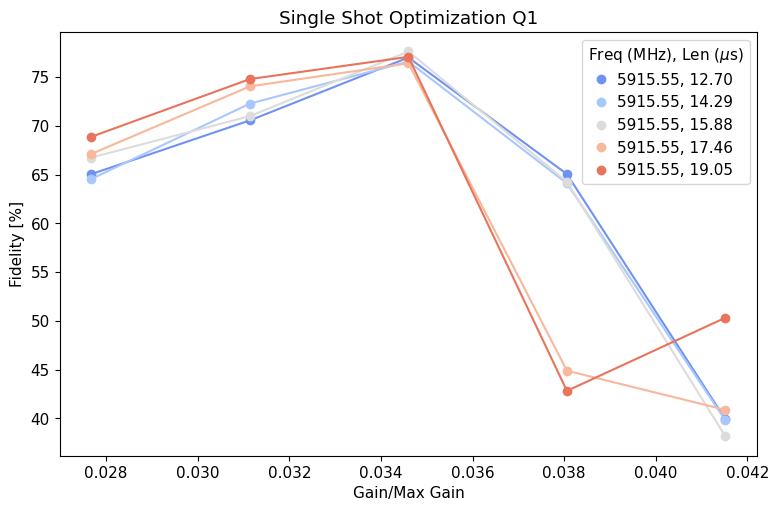

*Set cfg device.readout 1 gain to 0.0346 from 0.0346*
*Set cfg device.readout 1 readout_length to 12.7008 from 15.876*


  0%|          | 0/10000 [00:00<?, ?it/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

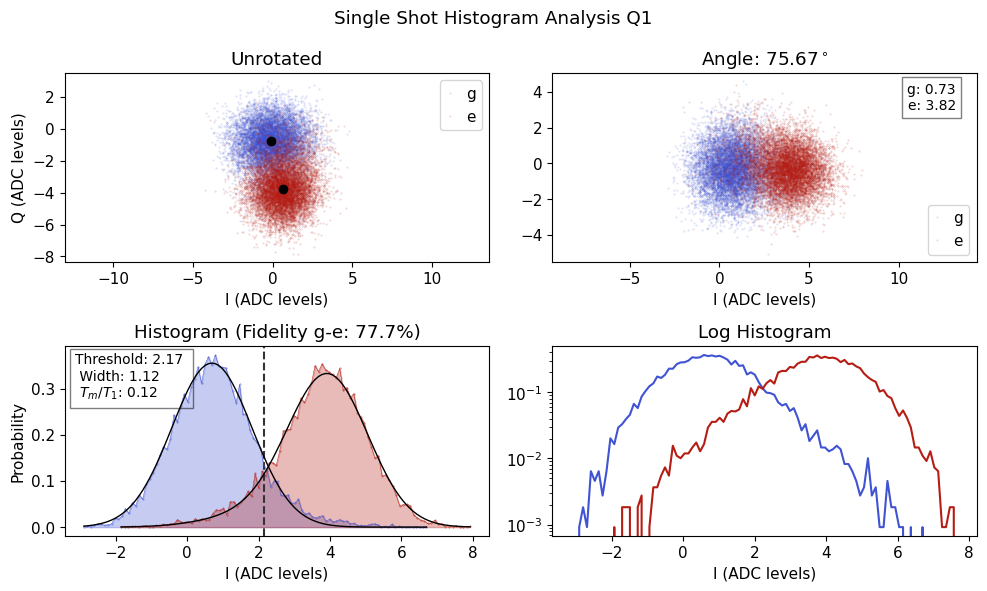

*Set cfg device.readout 1 phase to 75.6662 from -24.3327*
*Set cfg device.readout 1 threshold to 2.1654 from 1.0485*
*Set cfg device.readout 1 fidelity to 0.7774 from 0.6778*
*Set cfg device.readout 1 sigma to 1.1219 from 0.844*
*Set cfg device.readout 1 tm to 0.1161 from 0.4187*
*Set cfg device.qubit 1 tuned_up to True from True*


In [233]:
qubit_list=np.arange(3)
qubit_list=[0,1]
params = {'expts_f':1, 'expts_gain':5, 'expts_len':5}

# do_res also runs res spec and resets readout frequency that way each round. 
qubit_tuning.meas_opt(cfg_dict, qubit_list, params, do_res=True)

### Vary trig_offset to see if it changes fidelity. 

In [ ]:
# Single shot 
qubit_list = np.arange(13,20)
qubit_list =[11]
trig_list = np.linspace(0.2,1,12)
fids =[]
for qi in qubit_list:
    for trig in trig_list: 
        config.update_readout(cfg_path, 'trig_offset', trig, qi);
        shot=meas.HistogramExperiment(cfg_dict, qi=qi, params={'shots':20000, 'trigger':trig})
        fids.append(shot.data['fids'][0])
    

### Play with LO freq (when using qick for LO)

In [ ]:
auto_cfg = config.load(cfg_path)
start_freq = auto_cfg.device.readout.frequency[qi]
start_mixer = auto_cfg.hw.soc.lo.mixer_freq[qi]
rng = np.linspace(-1000,1000,11)
fids=[]
for qi in qubit_list: 
    for r in rng: 
        config.update_lo(cfg_path, 'mixer_freq', start_mixer+r, qi)
        config.update_readout(cfg_path, 'frequency', start_freq-r, qi)
        shot=meas.HistogramExperiment(cfg_dict, qi=qi, params={'shots':20000})
        fids.append(shot.data['fids'][0])

config.update_lo(cfg_path, 'mixer_freq', start_mixer, qi)
config.update_readout(cfg_path, 'frequency', start_freq, qi)

#### Play with LO power

In [ ]:
qi = 0
gain_vals = [0.0375,0.05] 
fids = []
for gain in gain_vals:
    config.update_lo(cfg_path, 'gain', gain, qi)
    shotopt=meas.SingleShotOptExperiment(cfg_dict, qi=qi,params={'npts_f':5, 'npts_gain':5, 'npts_len':5})
    fids.append(shot.data['fids'][0])

## Active reset

### Check active reset at standard threshold

Setup reset uses the calibrated angle and runs active reset process at end, but also uses usual final_delay so that it's ok if reset not working

  0%|          | 0/30000 [00:00<?, ?it/s]

  0%|          | 0/30000 [00:00<?, ?it/s]

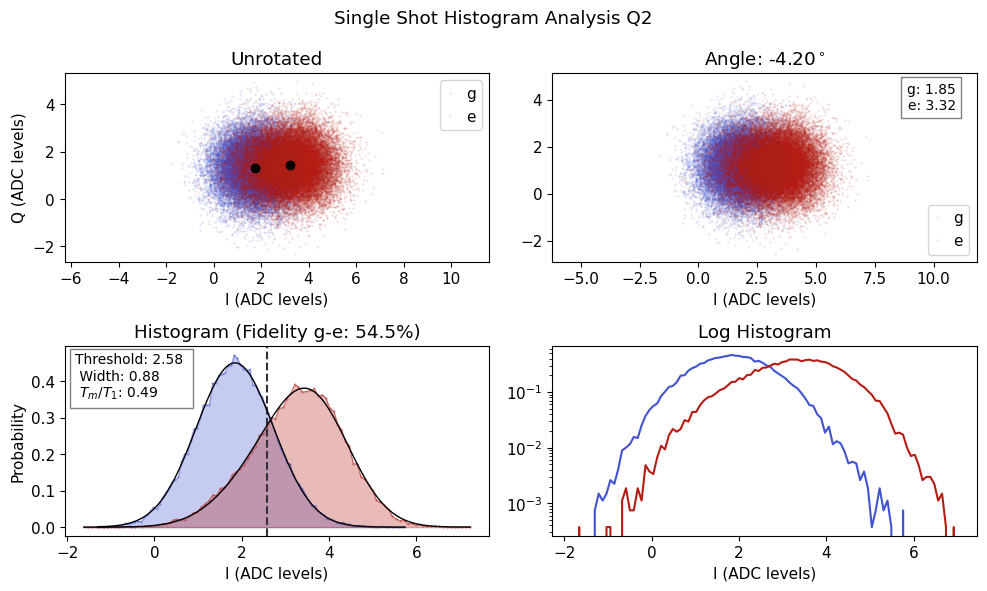

Reset is 0.184674 of e and 0.62559 of g


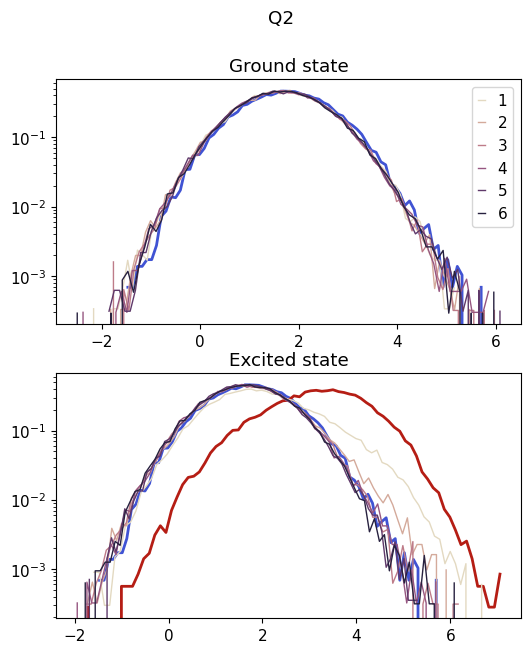

In [32]:
qubit_list = np.arange(15,20)
qubit_list=[2]
d=[]
for qi in qubit_list:
    shot = meas.HistogramExperiment(cfg_dict, qi=qi, params={'shots':30000,'active_reset':True, 'setup_reset':True})
    shot.check_reset()
    #config.update_readout(cfg_path, 'reset_e', shot.data['reset_e'], qi)
    #config.update_readout(cfg_path, 'reset_g', shot.data['reset_g'], qi)
    d.append(shot)

### Sweep threshold

In [ ]:
d = []
qi=10
auto_cfg = config.load(cfg_path)
threshold = auto_cfg['device']['readout']['threshold'][qi]
thresh = np.linspace(threshold-25,threshold+25,16)
#thresh = np.linspace(threshold-10,threshold+10,6)
for t in thresh:
    shot=meas.HistogramExperiment(cfg_dict, qi=qi, params={'shots':100000,'threshold_v':t, 'active_reset':True,'setup_reset':True}, display=False, progress=False)
    d.append(shot)
    #shot.check_reset()
tuneup.plot_reset(d)

### Turn off active reset for all config chans

In [ ]:
for qi in range(20):
    config.update_readout(cfg_path, 'active_reset',False, qi)

### Turn on active reset for channels where it seems to be working

In [ ]:
e_success = 0.15 # Ratio of e proportion after active reset compared to before
g_vs_e = 2 # Ratio of g proportion to e proportion after active reset

auto_cfg = config.load(cfg_path)
reset_e = auto_cfg['device']['readout']['reset_e']
reset_g = auto_cfg['device']['readout']['reset_g']
result = np.array(reset_e)< e_success | np.array(reset_g)/np.array(reset_e)<g_vs_e
for qi in range(20):
    config.update_readout(cfg_path, 'active_reset',bool(result[qi]), qi)

### Check reset (plotting result of reset)

In [ ]:
qubit_list = np.arange(11,20)
qubit_list =[17]
for qi in qubit_list:
    shot = meas.HistogramExperiment(cfg_dict, qi=qi, params={'shots':50000,'active_reset':True})
    shot.check_reset()

# Chi

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/2 [00:00<?, ?it/s]

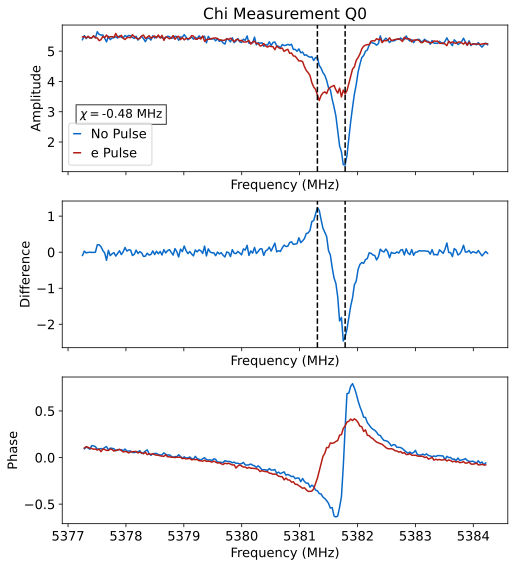

*Set cfg device.readout 0 chi to -0.4792 from 0*


  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/2 [00:00<?, ?it/s]

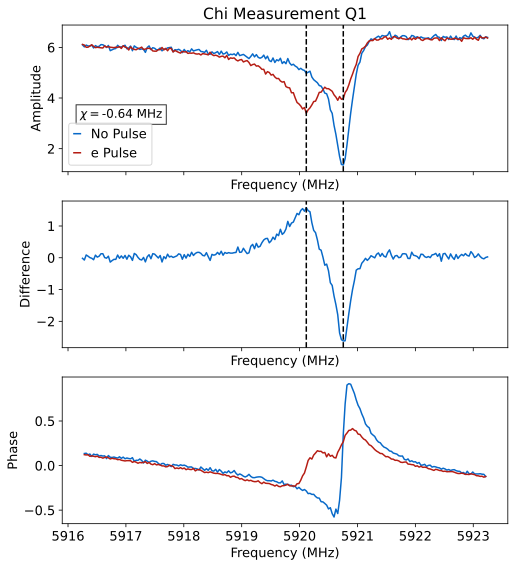

*Set cfg device.readout 1 chi to -0.639 from 0*


  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/2 [00:00<?, ?it/s]

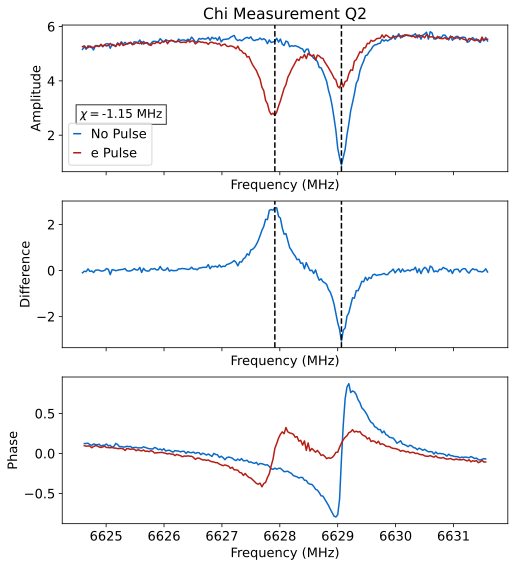

*Set cfg device.readout 2 chi to -1.1502 from 0*


In [73]:
# Need a tuned up pi pulse for this

qubit_list = [0,1,2]
for qi in qubit_list: 
    chi, chi_val=tuneup.check_chi(cfg_dict, qi)
    auto_cfg = config.update_readout(cfg_path, 'chi', chi_val, qi)

# 2 Qubit

In [ ]:
t12q = meas.T1_2Q(cfg_dict, qi=[10,0], params={'active_reset':False, })

In [ ]:
rabi2q = meas.Rabi_2Q(cfg_dict, qi=[10,0], params={'active_reset':True})

# EF 

### Initial setting of frequencies based on guess for alpha

In [58]:
# Initial set of the frequencyies based on guess for alpha 
alpha = -150
qubit_list = np.arange(3)
#qubit_list = [1,2,0]
auto_cfg = config.load(cfg_path)
for i in qubit_list: 
    f_ge = auto_cfg['device']['qubit']['f_ge'][i]
    auto_cfg = config.update_qubit(cfg_path, 'f_ef', f_ge+alpha, i)

*Set cfg device.qubit 0 f_ef to 2966.6373 from 3800*
*Set cfg device.qubit 1 f_ef to 4273.4488 from 4273.4488*
*Set cfg device.qubit 2 f_ef to 4915.646 from 4915.646*


## Spectroscopy EF

### General search

Performing medium scan


  0%|          | 0/150000 [00:00<?, ?it/s]

R2:0.822	Fit par error:0.028	 Best fit:b'avgi'


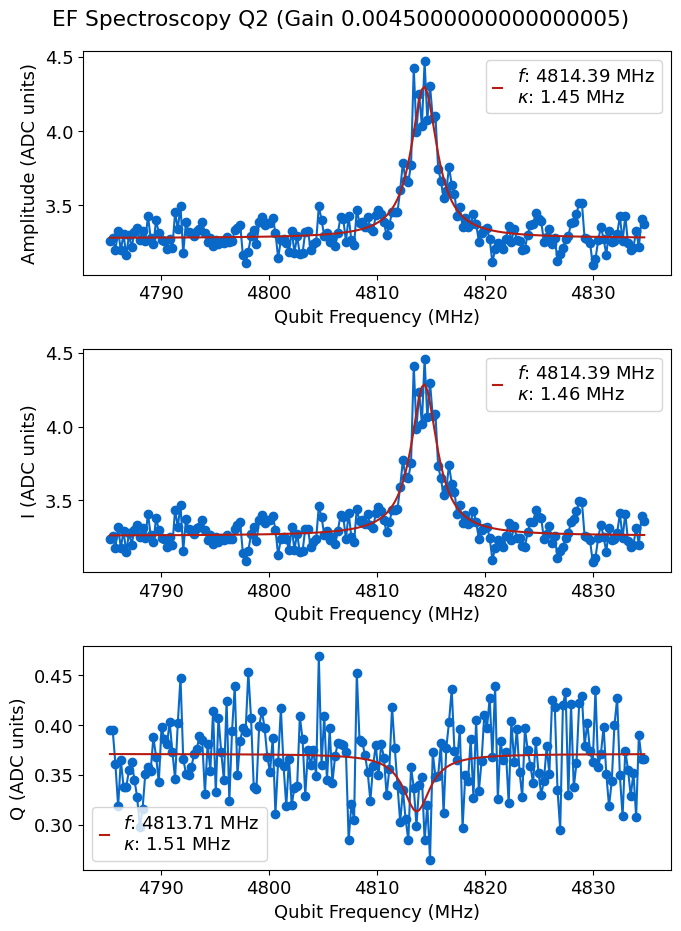

*Set cfg device.qubit 2 f_ef to 4814.3905 from 4810.0416*
Performing fine scan


  0%|          | 0/150000 [00:00<?, ?it/s]

R2:0.907	Fit par error:0.028	 Best fit:b'avgi'


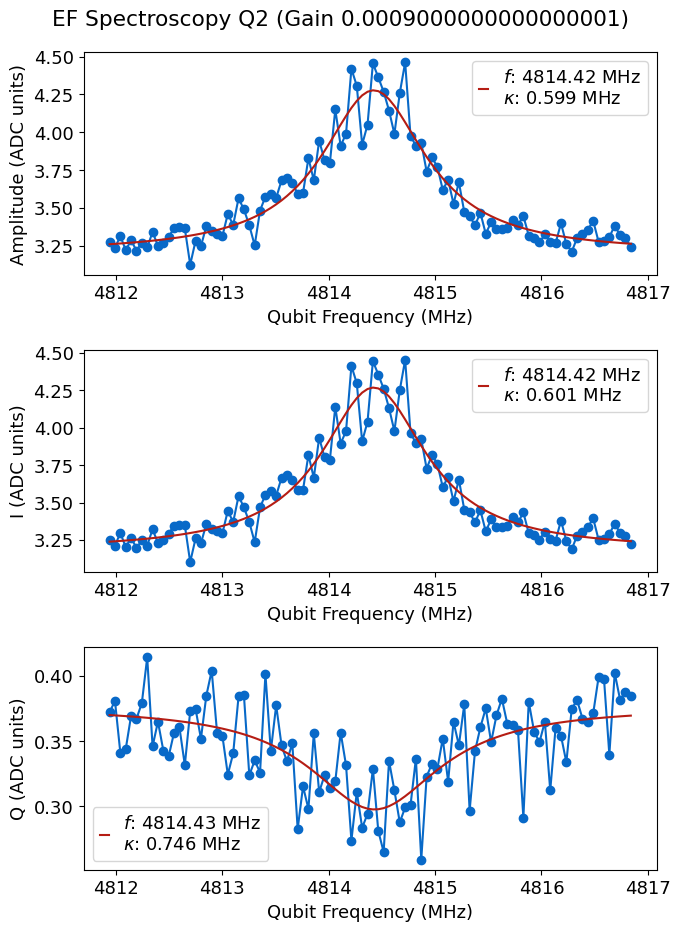

*Set cfg device.qubit 2 f_ef to 4814.4223 from 4814.3905*
Found qubit 2


In [64]:
qubit_list= np.arange(3)
bad_qubits=[]
qubit_list=[2]
for qi in qubit_list:
    status, ntries = qubit_tuning.find_spec(qi, cfg_dict, start='medium', freq='ef')
    if not status:
        bad_qubits.append(qi)

### Specific width

In [ ]:
# You may want to update this frequency, which will be the center of the scan. 
#style huge, coarse, medium, fine 
update=True

qubit_list = np.arange(10)
qubit_list=[2]
for qi in qubit_list:
    qspec=meas.QubitSpec(cfg_dict, qi=qi, style='coarse', params={'checkEF':True, 'gain':1,'reps':2000})#, params={'span':500, 'expts':1000,'reps':500,'gain':0.2})

    #qspec=meas.QubitSpec(cfg_dict, qi=qi, style='medium', params={'checkEF':True})#, params={'span':500, 'expts':1000,'reps':500,'gain':0.2})
    if update and qspec.status:
        auto_cfg = config.update_qubit(cfg_path, 'f_ef', qspec.data["best_fit"][2], qi)

## Rabi EF

*Set cfg device.qubit 0 ('pulses', 'pi_ef', 'sigma') to 0.1 from 0.1*
*Set cfg device.qubit 0 ('pulses', 'pi_ef', 'gain') to 0.0439 from 0.15*


  0%|          | 0/9000 [00:00<?, ?it/s]

R2:0.993	Fit par error:0.009	 Best fit:b'avgi'


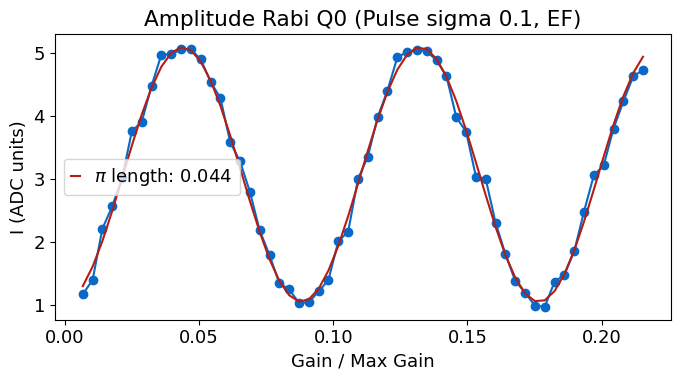

*Set cfg device.qubit 0 ('pulses', 'pi_ef', 'gain') to 0.0438 from 0.0439*
*Set cfg device.qubit 1 ('pulses', 'pi_ef', 'sigma') to 0.1 from 0.1*
*Set cfg device.qubit 1 ('pulses', 'pi_ef', 'gain') to 0.0313 from 0.15*


  0%|          | 0/9000 [00:00<?, ?it/s]

R2:0.982	Fit par error:0.013	 Best fit:b'avgi'


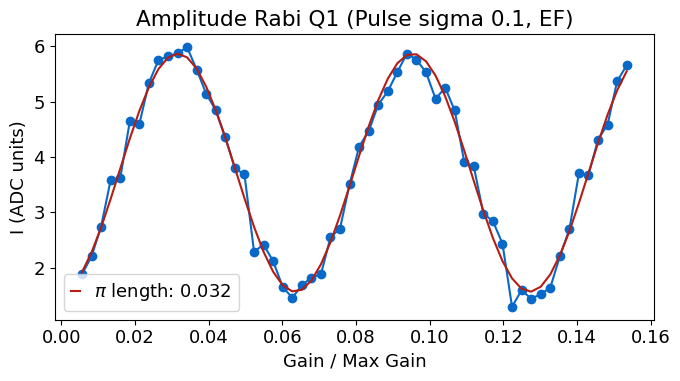

*Set cfg device.qubit 1 ('pulses', 'pi_ef', 'gain') to 0.0316 from 0.0313*
*Set cfg device.qubit 2 ('pulses', 'pi_ef', 'sigma') to 0.1 from 0.1*
*Set cfg device.qubit 2 ('pulses', 'pi_ef', 'gain') to 0.0277 from 0.15*


  0%|          | 0/9000 [00:00<?, ?it/s]

R2:0.983	Fit par error:0.014	 Best fit:b'avgi'


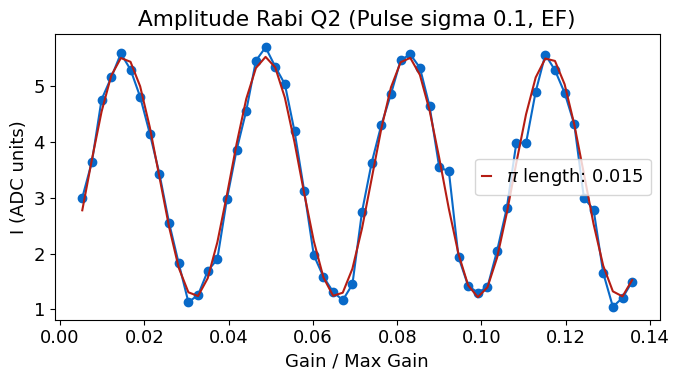

*Set cfg device.qubit 2 ('pulses', 'pi_ef', 'gain') to 0.0152 from 0.0277*


In [65]:
# If first time, initialize the sigma and gain to those of the ge 
first_time =True
update = True

qubit_list = np.arange(3)
#qubit_list=[0]

bad_qubits = []
auto_cfg = config.load(cfg_path)

for qi in qubit_list: 
    if first_time:
        #config.update_qubit(cfg_path, 'f_ef', auto_cfg.device.qubit.f_spec_ef[qi], qi)
        auto_cfg = config.update_qubit(cfg_path, ('pulses','pi_ef','sigma'), auto_cfg['device']['qubit']['pulses']['pi_ge']['sigma'][qi], qi)
        auto_cfg = config.update_qubit(cfg_path, ('pulses','pi_ef','gain'), auto_cfg['device']['qubit']['pulses']['pi_ge']['gain'][qi], qi)
    amp_rabi = meas.RabiExperiment(cfg_dict,qi=qi, params={'checkEF':True})
    if update and amp_rabi.status:
        config.update_qubit(cfg_path, ('pulses','pi_ef','gain'), amp_rabi.data['pi_length'], qi)
    else:
        print(f'Amplitude Rabi fit failed for qubit {qi}')
        bad_qubits.append(qi)

## Qubit Temperature

  0%|          | 0/9000 [00:00<?, ?it/s]

R2:0.988	Fit par error:0.011	 Best fit:b'avgi'


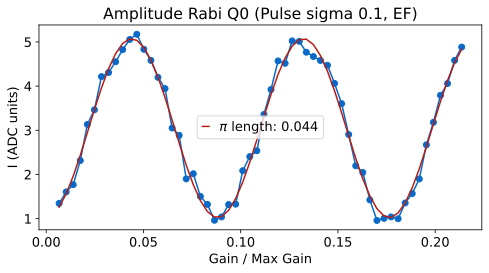

  0%|          | 0/30 [00:00<?, ?it/s]

R2:0.508	Fit par error:0.188	 Best fit:b'avgi'


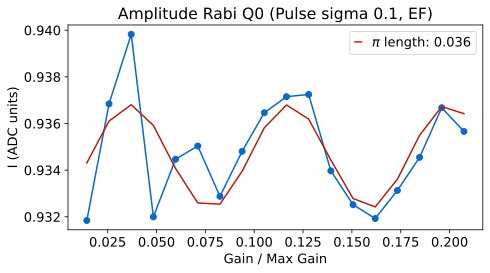

Qubit temp [mK]: 21.953087937348535
State preparation ratio: 0.001098958600995711
2.0249376358502134
0.002225322631397513


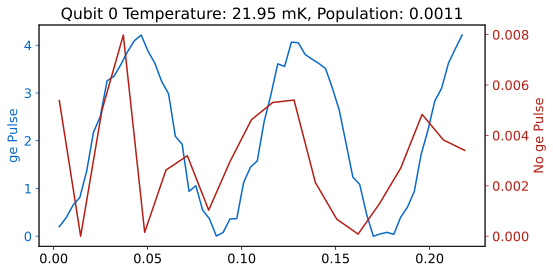

*Set cfg device.qubit 0 temp to 21.9531 from 0*
*Set cfg device.qubit 0 pop to 0.0011 from 0*


  0%|          | 0/9000 [00:00<?, ?it/s]

R2:0.980	Fit par error:0.014	 Best fit:b'avgi'


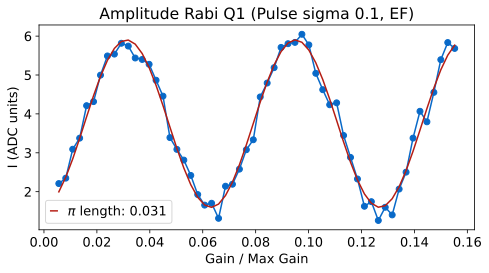

  0%|          | 0/30 [00:00<?, ?it/s]

R2:0.372	Fit par error:1.483	 Best fit:b'avgi'


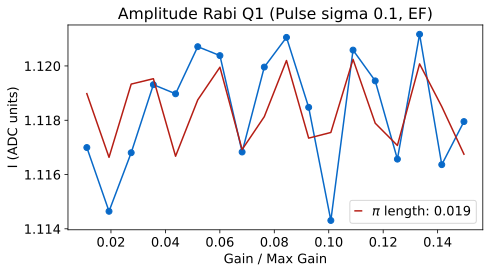

Qubit temp [mK]: 29.98767640498798
State preparation ratio: 0.0008423540967946775
2.1534532915198805
0.0018139702023677543


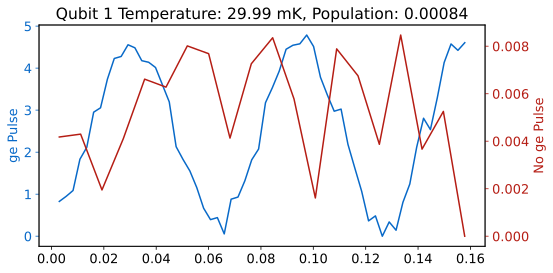

*Set cfg device.qubit 1 temp to 29.9877 from 0*
*Set cfg device.qubit 1 pop to 0.0008 from 0*


  0%|          | 0/9000 [00:00<?, ?it/s]

R2:0.987	Fit par error:0.013	 Best fit:b'avgi'


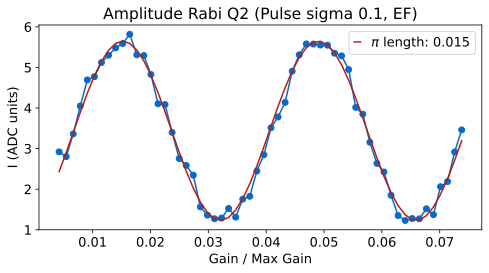

  0%|          | 0/30 [00:00<?, ?it/s]

R2:0.319	Fit par error:0.198	 Best fit:b'avgi'


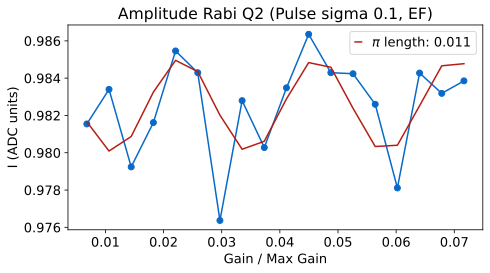

Qubit temp [mK]: 35.82907127655601
State preparation ratio: 0.0011302159720177857
2.208457759545925
0.002496034233365419


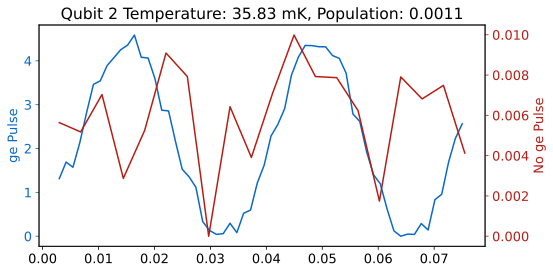

*Set cfg device.qubit 2 temp to 35.8291 from 0*
*Set cfg device.qubit 2 pop to 0.0011 from 0*


In [77]:
qubit_list = np.arange(3)
qubit_list=[0,1,2]
for qi in qubit_list: 
    # Soft_avgs will make scan take longer, needed for lower temperatures. 
    temp, pop = tuneup.measure_temp(cfg_dict, qi=qi)# , soft_avgs=5)
    auto_cfg = config.update_qubit(cfg_path, 'temp', temp, qi)
    auto_cfg = config.update_qubit(cfg_path, 'pop', pop, qi)

In [69]:
config.init_model_config(cfg_dict['cfg_file'], 3)

'Delta: [null, null, null]\nEc: [null, null, null]\nEj: [null, null, null]\nQ1: [null, null, null]\nQ1_max: [null, null, null]\nQ1_mean: [null, null, null]\nSum: [null, null, null]\nT1_max: [null, null, null]\nT1_mean: [null, null, null]\nT1_nopurcell: [null, null, null]\nT1_purcell: [null, null, null]\nT1max_nopurcell: [null, null, null]\nT1mean_nopurcell: [null, null, null]\nT2E_max: [null, null, null]\nT2E_mean: [null, null, null]\nT2R_max: [null, null, null]\nT2R_mean: [null, null, null]\nTphi: [null, null, null]\nalpha: [null, null, null]\ng_chi: [null, null, null]\ng_lamb: [null, null, null]\nkappa_low: [null, null, null]\nng: [null, null, null]\nnqubits: 3\nratio: [null, null, null]\n'

## Calculate Ec and Ej

In [74]:
import slab_qick_calib.qubit_params as qubit_params 

qubit_params.ham(cfg_path)
qubit_params.delta(cfg_path)
qubit_params.cohere(cfg_path)

## Ramsey EF

In [258]:
update=True
qubit_list=np.arange(3)
#qubit_list=[12]

for qi in qubit_list:
    t2r = meas.T2Experiment(cfg_dict, qi=qi, params={'ramsey_freq':0.15, 'checkEF':True})

    if update and t2r.status:
        config.update_qubit(cfg_path, 'f_ef', t2r.data['new_freq'], qi)
    else:
        print('T2 Ramsey fit failed')

  0%|          | 0/40000 [00:00<?, ?it/s]

KeyboardInterrupt: 

# Stark

## Ramsey

### Single experiment

Unexpected parameters found in params: {'stark_freq'}


  0%|          | 0/2 [00:00<?, ?it/s]

R2:0.022	Fit par error:0.788	 Best fit:b'avgi'


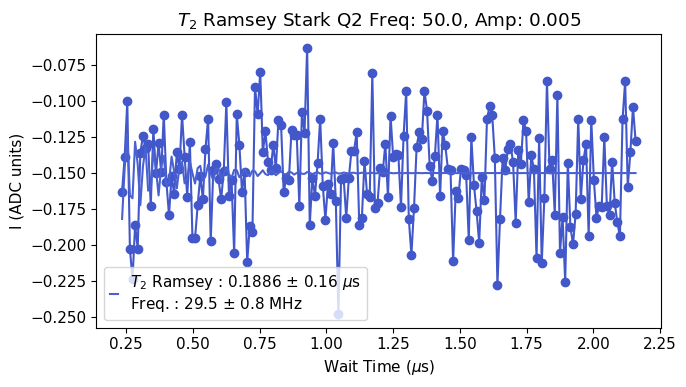

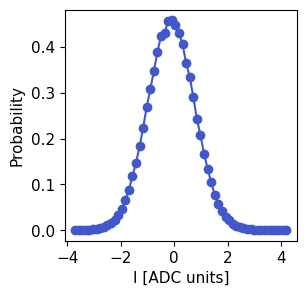

In [64]:
qi=2
meas.RamseyStarkExperiment(cfg_dict, qi=qi, params={'stark_gain':0.005,'step':0.01,'df':50,'acStark':True,'ramsey_freq':0.1})

### Sweep frequency

In [ ]:
qubit_list = np.arange(3,20)
qubit_list=[2]

gain = np.linspace(0.1,1,10)
for qi in qubit_list:
    for g in gain:
        t2rstark=meas.RamseyStarkFreqExperiment(cfg_dict, qi=qi, params={'step':1/430+0.001, 'stark_gain':g, 'start_df':30, 'end_df':150, 'expts_df':10})

### Calibrate stark power positive freq

In [104]:
config.init_stark_section(cfg_dict['cfg_file'], 3)

{'aliases': {'soc': 'Qick105'},
 'device': {'qubit': {'T1': [94.07, 58.64, 22.58],
   'T2e': [21.92, 20.55, 18.9],
   'T2r': [31.17, 40.21, 40.02],
   'f_ef': [3250.0555, 4361.0968, 5298.7098],
   'f_ge': [3392.5489, 4590.885, 5561.0957],
   'kappa': [0.8525, 0.224, 20.3627],
   'low_gain': 0.003,
   'max_gain': 1,
   'pop': [0.0032, 0.0064, 0.0035],
   'pulses': {'pi_ef': {'gain': [0.2831, 0.5108, 0.1246],
     'sigma': [0.1, 0.1, 0.1],
     'sigma_inc': [5, 5, 5],
     'type': ['gauss', 'gauss', 'gauss']},
    'pi_ge': {'gain': [0.0222, 0.0227, 0.0136],
     'sigma': [0.1, 0.1, 0.1],
     'sigma_inc': [5, 5, 5],
     'type': ['gauss', 'gauss', 'gauss']}},
   'spec_gain': [0.1, 0.1, 0.8],
   'temp': [28.3178, 43.5699, 46.9897],
   'tuned_up': [True, True, False]},
  'readout': {'active_reset': [False, False, True],
   'chi': [-0.5431, -0.7348, -1.7253],
   'fidelity': [0.6501, 0.8136, 0.5452],
   'final_delay': [564.41, 351.83, 135.48],
   'frequency': [5375.6984, 5915.5068, 6623.5552

Unexpected parameters found in params: {'end_gain', 'expts_gain', 'start_gain', 'stark_freq'}


  0%|          | 0/12 [00:00<?, ?it/s]

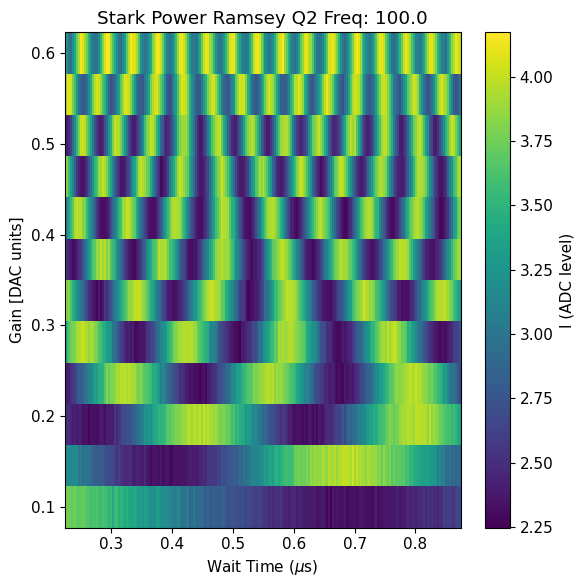

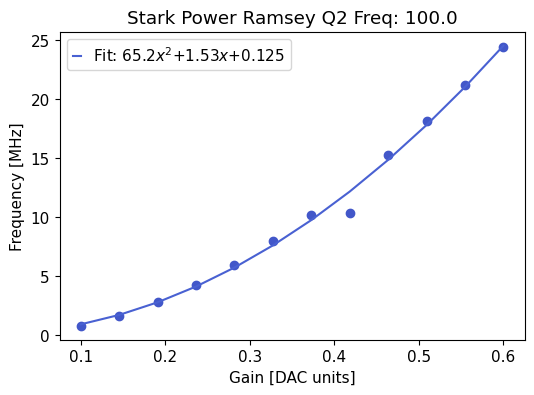

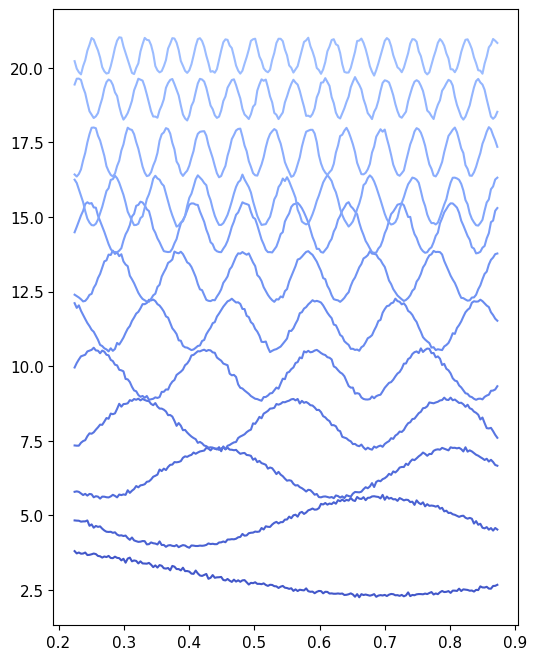

*Set cfg stark 2 q to 65.236 from 77.8802*
*Set cfg stark 2 l to 1.534 from -1.2334*
*Set cfg stark 2 o to 0.1247 from 0.1948*


In [134]:
qubit_list = np.arange(13,20)
qubit_list=[2]
d=[]
freqs= [100]
for f in freqs:
    for qi in qubit_list:
        t2rstark=meas.RamseyStarkPowerExperiment(cfg_dict, qi=qi, params={'step':1/430+0.001, 'expts_gain':12, 'df':f, 'start_gain':0.1, 'end_gain':0.6})
        d.append(t2rstark)
        config.update_stark(cfg_path, 'q', t2rstark.data['quad_fit'][0], qi)
        config.update_stark(cfg_path, 'l', t2rstark.data['quad_fit'][1], qi)
        config.update_stark(cfg_path, 'o', t2rstark.data['quad_fit'][2], qi)

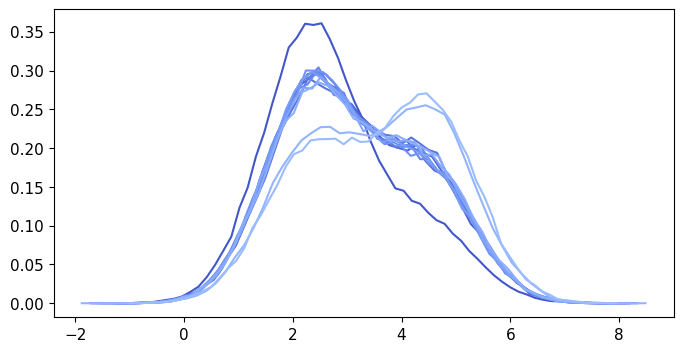

In [135]:
plt.figure()
for i in range(len(t2rstark.data['bin_centers'])):
    plt.plot(t2rstark.data['bin_centers'][i], t2rstark.data['hist'][i])

### Negative frequency

Unexpected parameters found in params: {'end_gain', 'expts_gain', 'start_gain', 'stark_freq'}


  0%|          | 0/12 [00:00<?, ?it/s]

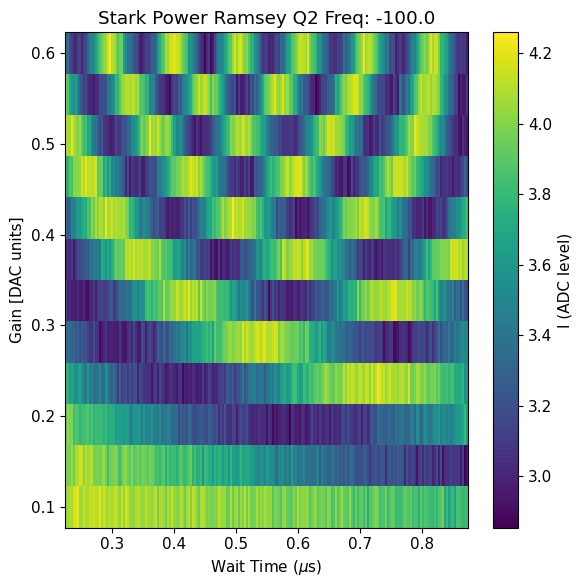

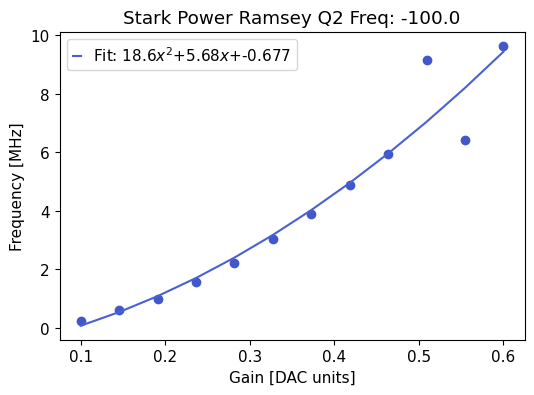

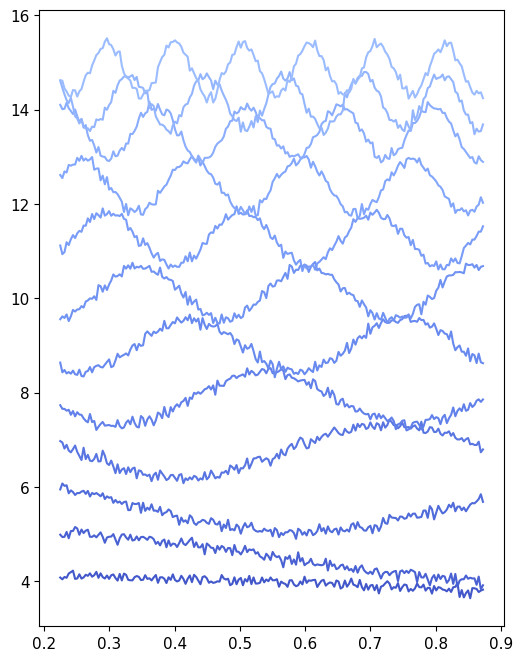

*Set cfg stark 2 qneg to 18.6405 from 29.888*
*Set cfg stark 2 lneg to 5.6796 from -0.9272*
*Set cfg stark 2 oneg to -0.6774 from 0.129*


In [136]:
#qubit_list = np.arange(20)
d=[]
qubit_list=[2]
for qi in qubit_list:
    t2rstark=meas.RamseyStarkPowerExperiment(cfg_dict, qi=qi, params={'step':1/430+0.001, 'expts_gain':12, 'df':-100, 'start_gain':0.1, 'end_gain':0.6, 'soft_avgs':1})
    d.append(t2rstark)
    config.update_stark(cfg_path, 'qneg', t2rstark.data['quad_fit'][0], qi)
    config.update_stark(cfg_path, 'lneg', t2rstark.data['quad_fit'][1], qi)
    config.update_stark(cfg_path, 'oneg', t2rstark.data['quad_fit'][2], qi)
#handy.plot_many(d, title='Ramsey Stark', save_path=cfg_dict['expt_path'])

## T1

### Single exp

In [178]:
qi=0
gain_list = [1]
for g in gain_list:
    t1 = meas.T1StarkExperiment(cfg_dict, qi=qi, params={'active_reset':False, 'df':50, 'stark_gain':g,'expts':300,'start':10,'span':100}) 

Unexpected parameters found in params: {'stark_freq'}


RuntimeError: tried to cast a swept QickRawParam to int, which is not safe

### Gain sweep

Unexpected parameters found in params: {'end_gain', 'expts_gain', 'start_gain', 'stark_freq'}


  0%|          | 0/40 [00:00<?, ?it/s]

  0%|          | 0/36000 [00:00<?, ?it/s]

  0%|          | 0/36000 [00:00<?, ?it/s]

  0%|          | 0/36000 [00:00<?, ?it/s]

...

  0%|          | 0/36000 [00:00<?, ?it/s]

  0%|          | 0/36000 [00:00<?, ?it/s]

  0%|          | 0/36000 [00:00<?, ?it/s]

  0%|          | 0/36000 [00:00<?, ?it/s]

  0%|          | 0/36000 [00:00<?, ?it/s]

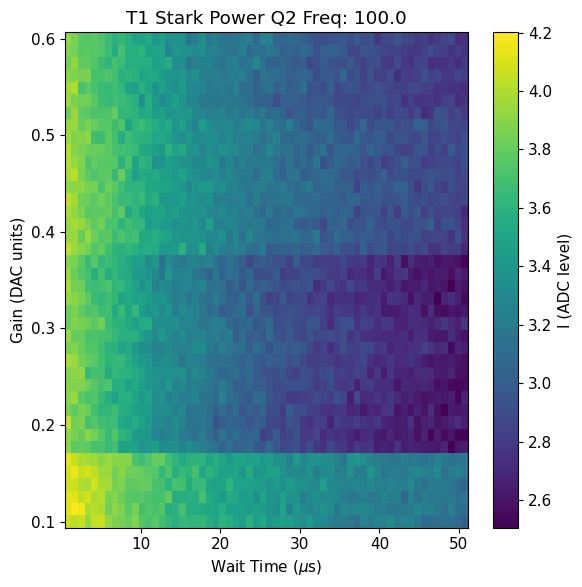

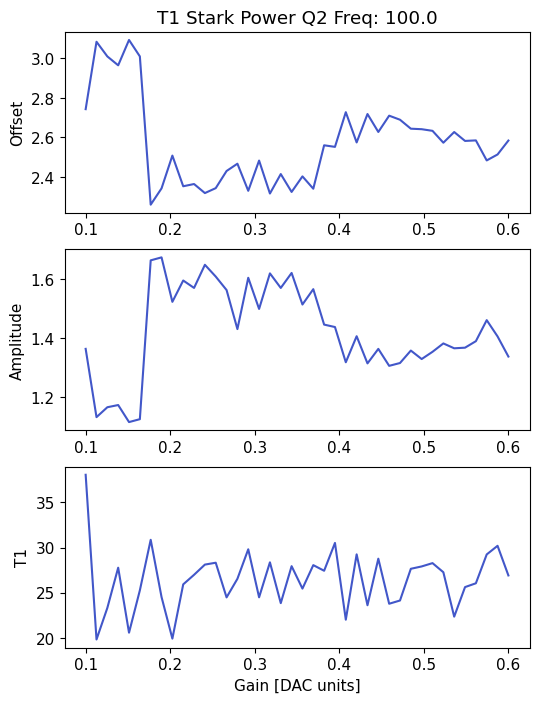

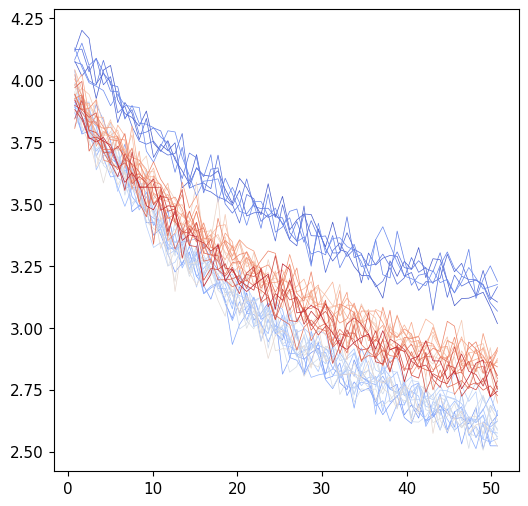

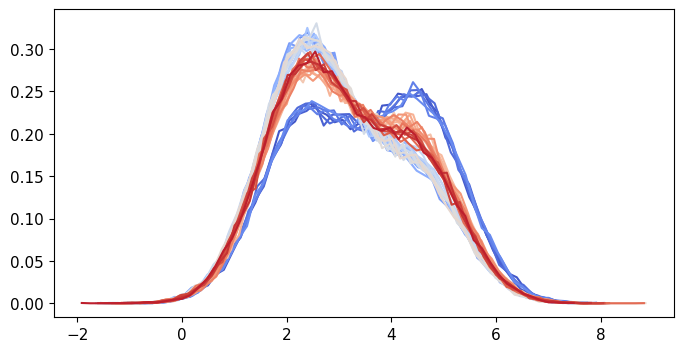

In [133]:
qubit_list = np.arange(3)
qubit_list=[2]
flist=[100]
for f in flist:
    for qi in qubit_list: 
        #t1_neg = meas.T1StarkPowerExperiment(cfg_dict, qi=qi, params={'df':-70,'start_gain':0.02,'end_gain':0.2,'start':3, 'soft_avgs':4})

        t1_pos = meas.T1StarkPowerExperiment(cfg_dict, qi=qi, params={'df':f,'start_gain':0.1,'end_gain':0.6,'start':0.2, 'soft_avgs':1,'span':50,'expts_gain':40}) 
        plt.figure()
        for i in range(len(t1_pos.data['bin_centers'])):
            plt.plot(t1_pos.data['bin_centers'][i], t1_pos.data['hist'][i])

### Freq sweep

In [ ]:
t1_freq = meas.T1StarkFreqExperiment(cfg_dict, qi=19, params={'span':6, 'span_f':100, 'start_df':50, 'expts_f':100})

In [ ]:
t1_freq = meas.T1StarkFreqExperiment(cfg_dict, qi=19, params={'span':6, 'span_f':100, 'start_df':50, 'expts_f':100,'gain':0.5})

### Single evo point linear gain sweep

In [157]:
t1_cont = meas.T1StarkPowerSingle(cfg_dict, qi=0, params={"reps":100, "wait_time":80})

Unexpected parameters found in params: {'stark_freq'}


  0%|          | 0/20000 [00:00<?, ?it/s]

RuntimeError: Pulse length of 208936 cycles is out of range (exceeds 16 bits, or less than 3) - use multiple pulses, or zero-pad the envelope

In [168]:
t1_cont = meas.T1StarkPowerQuadMulti(cfg_dict, qi=2, params={"reps":100, 'df_pos':100, 'df_neg':-100})

Unexpected parameters found in params: {'wait_times'}
gain_pos: [0.0, 0.02462225139367636, 0.0547275142902765, 0.07494327403766407, 0.09126574906415352, 0.10533457756709638, 0.1178855439292636, 0.12932432955695974, 0.13990279836250963, 0.14979004503753054, 0.15910610730429556, 0.1679398430882662, 0.17635921315716346, 0.18441757560677982, 0.19215773407999073, 0.1996146480799214, 0.20681730912104215, 0.21379007656467983, 0.22055365196522073, 0.22712580475068303, 0.23352192266645203, 0.23975543608361566, 0.24583814979728827, 0.2517805058336457, 0.25759179402869803, 0.263280322530943, 0.2688535571734419, 0.2743182363926469, 0.2796804667419042, 0.28494580286039345, 0.2901193148820571, 0.29520564561459967, 0.30020905932438174, 0.30513348358593667, 0.3099825453643943, 0.3147596022733975, 0.3194677697742668, 0.324109944942541, 0.32868882731697485, 0.33320693725714945, 0.33766663216418347, 0.34207012086092203, 0.34641947638059406, 0.35071664737406927, 0.3549634683138286, 0.3591616686462373, 0.3

  0%|          | 0/199 [00:00<?, ?it/s]

KeyError: 'end_wait'

### Run linear scan for multiple qubits

In [ ]:
#first, need to configure active reset and check stark for all. 
nexp = 3
qubit_list =[1,2]#2,4,5,6,7]
expts = 200
t1_data = [[] for _ in qubit_list]

for i in range(nexp):
    for j, qi in enumerate(qubit_list):
        t1_cont = meas.T1StarkPowerSingle(cfg_dict, qi=qi, params={ "soft_avgs":2,'expts':100})
        t1_data[j].append(t1_cont.data['t1'])

plt.figure()
fig, ax = plt.subplots(3, 2, figsize=(10, 10))
ax = ax.flatten()
for i, qi in enumerate(qubit_list):
    ax[i].set_title(f'Q{qi}')
    ax[i].pcolormesh(t1_data[i])
    plt.colorbar(ax[i].collections[0], ax=ax[i])

### Repeated single evo, sweep frequency linearly with gain [Main scan]

In [ ]:
d=[]
qi=6
params={'stop_f':20, 'df_pos':100, 'df_neg':-70}
for i in range(200):
    if i%10==0:
        t1stark=meas.T1StarkPowerQuadSingle(cfg_dict, qi=qi, params=params)
        shot = meas.HistogramExperiment(cfg_dict, qi=qi, params={'shots':20000})
        config.update_readout(cfg_path, 'threshold',shot.data['thresholds'][0], qi);
        config.update_readout(cfg_path, 'phase', shot.data['angle'], qi);
        phase.append(shot.data['angle'])
    else:
        t1stark=meas.T1StarkPowerQuadSingle(cfg_dict, qi=qi, params=params, display=False, progress=False)

    d.append(t1stark)

times = [d[i].data['start_time'] for i in range(0, len(d))] 
tm = [datetime.strptime(times[i].decode('utf-8'), '%Y-%m-%d %H:%M:%S') for i in range(len(times))]
time_from_first = [(t - tm[0]).total_seconds() for t in tm]
print(time_from_first)

concatenated_data = np.concatenate([d[i].data['avgi'] for i in range(0, len(d))], axis=1)

plt.figure()
plt.pcolormesh(concatenated_data)

In [ ]:
plt.figure()
concatenated_data = np.concatenate([d[i].data['avgi'] for i in range(0, len(d))], axis=1)
import matplotlib.dates as mdates

plt.pcolormesh(np.array(time_from_first)/60/60, d[-1].data['f_pts'], concatenated_data)
#plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d %H:%M'))
#plt.gca().xaxis.set_major_locator(mdates.HourLocator(interval=1))
#plt.gcf().autofmt_xdate()


### Calib sweep

### Analysis of multiple evo times using normal fittingh

In [ ]:
# Processing for multiple evo times 
cd0 = np.concatenate([d[i].data['avgi_0'] for i in range(0, len(d))], axis=1)
cd1 = np.concatenate([d[i].data['avgi_1'] for i in range(0, len(d))], axis=1)
cd2 = np.concatenate([d[i].data['avgi_2'] for i in range(0, len(d))], axis=1)
cd3 = np.concatenate([d[i].data['avgi_3'] for i in range(0, len(d))], axis=1)

combined_cd = np.stack((cd0, cd1, cd2, cd3), axis=-1)
print(combined_cd.shape)

tms=d[0].data['wait_times']

sns.set_palette('coolwarm',len(combined_cd))
from scipy.optimize import curve_fit
plt.figure()
def t1_fit(x, a, b, c):
    return b * np.exp(-x / c) + a
fits=[]
tm_full = np.linspace(0, tms[3])
#for i in range(5):
for i in range(len(combined_cd)):
    plt.plot(tms, combined_cd[i][0][:],'o-')
    p0 = (np.min(combined_cd[i][0][:]), np.max(combined_cd[i][0][:])-np.min(combined_cd[i][0][:]), tms[2])
    popt, err = curve_fit(t1_fit, tms, combined_cd[i][0][:], p0=p0)
    fit_err = np.sqrt(np.diag(err))   
    if np.mean(fit_err/np.abs(popt))>0.5:
        fits.append(np.nan*np.ones(3))   
    else:
        fits.append(popt)
    #print(p0)
    #plt.plot(tm_full, t1_fit(np.array(tm_full), *popt),'k', label=f'Fit {i}')
    #print(popt)
#plt.legend()
t1_data = [fits[i][2] for i in range(len(fits))]    
offset = [fits[i][0] for i in range(len(fits))]
amp = [fits[i][1] for i in range(len(fits))]

fig, ax = plt.subplots(3, 1, figsize=(8, 7))
ax[0].plot(t1_data, 'o-')
ax[1].plot(offset, 'o-')
ax[2].plot(amp, 'o-')

In [ ]:
# Concatenate all d[i].data['avgi'] into a single dataset
concatenated_data = np.concatenate([d[i].data['avgi'] for i in range(1, len(d))], axis=1)

#print(concatenated_data)

plt.figure()
plt.pcolormesh(concatenated_data)

#### Check max value for calibration

In [ ]:
np.max(t1.data['avgi'], axis=1)
plt.figure()
plt.plot(np.max(t1.data['avgi'], axis=1))